# How prompt bans move an LLM's path-search choices: runnable demo (Qwen3-8B, T1 grid path)

This notebook is a runnable, CPU-only walk-through of the experiment **"How prompt bans move an LLM's path-search
choices"**. It follows the artifact's entry point `method.py` stage by stage, using the original code.

**The question.** When Qwen3-8B (bf16, thinking off, T = 1.0) is asked to write a path-search program, which
algorithm does it choose? If that algorithm is *banned* in the prompt, where does the model go instead? And does the
geometry of the model's internal states predict where it goes?

**Task T1 (`t1_grid_path`).** `solve(grid, start, goal)` on a 4-connected grid of up to 30×30 cells. The catalogue
has 6 algorithm families: `bfs, dfs, bidir_bfs, iddfs, astar, dijkstra_unit`. (The artifact also has a weighted
shortest-path task T2, which is not part of this demo.)

**What `method.py` runs, and what this notebook does with each stage.** In the original, each stage is a separate
process. The GPU stages took about 2.2 h on one NVIDIA L4.

| stage | what it does | here |
|---|---|---|
| `tasks` | hidden test suite (41 T1 cases); every catalogue reference must pass; wrong programs must fail | **runs** |
| `labtests` | labeller unit tests: references and mutants, runtime tracer and AST rules | **runs** |
| `prompts`, `succession` | every prompt (condition × paraphrase) | **runs** (prompt texts) |
| `phase_a` | GPU sampling: baseline N=200; forced-named and name-masked prompts, 30 per algorithm | replayed from saved programs |
| `label_a` | label every program (hidden tests + runtime trace + AST; blind LLM judge on disagreement); Phase-A summary | **runs** (stored judge decisions replayed) |
| `phase_b` | read-position states h_R (GPU forward pass), R gate (probes), manifold, **hash-committed forecasts** | **runs** on the saved h_R at layer 27 |
| `phase_c`, `phase_c_ext` | GPU sampling of prompt bans, labelled online, scored against the commit | replayed, re-labelled, scored |
| `phase_d`, `phase_d_ext` | removing the modal algorithm's direction from the activations (hooked generation) | full-run summary only |
| `analysis` | condition summaries, geodesic-MDS manifold, forecast contest | **runs** |

**Demo data.** `mini_demo_data.json` is a curated subset of 100 T1 programs:

* 48 forced-named programs and 12 name-masked programs (8 + 2 per algorithm);
* 10 baseline programs;
* 14 `ban:bfs` programs;
* 6 + 6 exploratory step-2 bans;
* 4 `mention:bfs` programs.

The label mix of every condition follows the full run. Each example carries its prompt's **read-position state at
layer 27** (residual stream at the last prompt token; layer 27 is T1's l\*), so the geometry runs on real activations.

**Full-run headline (T1).**

* Baseline: 200/200 BFS.
* `ban:bfs` (N=100): 62 BFS / 29 DFS / 9 unit-Dijkstra, a compliance of only 0.18.
* The mass that leaves BFS lands only on BFS's two geodesic neighbours on the read-position manifold: DFS (distance
  41) and unit-Dijkstra (58). It never lands on A\*, IDDFS or bidirectional BFS (71–95).
* Of the hash-committed forecasts, geodesic proximity has the best mean log score. The model's own ranking of the
  "most standard alternative" is the worst.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (the artifact's logger) - NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib, pandas - pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0', 'pandas==2.2.2')

## Imports

These are the module-level imports of the original scripts (`common.py`, `tasks/tasklib.py`, `labeller/*.py`,
`hf/phase_b.py`, `gen/phase_c.py`, `analysis/*.py`), merged into one cell. Imports that the original makes inside
functions (scikit-learn, `scipy.stats`, `joblib`, `threadpoolctl`) stay inside those functions. `matplotlib` and
`pandas` are notebook additions for the results tables.

In [2]:
from __future__ import annotations

import ast
import asyncio
import datetime
import gc
import hashlib
import heapq
import io
import itertools
import json
import math
import os
import random
import re
import shutil
import subprocess
import sys
import tempfile
import threading
import time
import tokenize
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from scipy.sparse import coo_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components, minimum_spanning_tree, shortest_path
from scipy.spatial.distance import cdist

# notebook additions: figures and tables
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

## Load the demo data

`mini_demo_data.json` is fetched from the paper's GitHub repository. If the URL is not reachable yet, the local copy
next to the notebook is used.

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-1/experiment-2/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["description"])
print(f"\n{len(data['examples'])} programs; h_R at layer {meta['layer']} ({meta['hR_dim']} dims) per program")
print("programs per condition:", meta["selection"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated 100-program subset of the T1 grid-path dataset (t1_grid_path) of the path-search ban screen on Qwen3-8B (bf16, thinking off, T=1.0). Each example is one generated program in the original sample-row schema, with its prompt text and the read-position state h_R of its prompt at layer 27 (residual stream after decoder block 27, last prompt token).

100 programs; h_R at layer 27 (4096 dims) per program
programs per condition: {'forced:bfs': 8, 'forced:dfs': 8, 'forced:bidir_bfs': 8, 'forced:iddfs': 8, 'forced:astar': 8, 'forced:dijkstra_unit': 8, 'masked:bfs': 2, 'masked:dfs': 2, 'masked:bidir_bfs': 2, 'masked:iddfs': 2, 'masked:astar': 2, 'masked:dijkstra_unit': 2, 'baseline': 10, 'ban:bfs': 14, 'ban:bfs+dfs': 6, 'ban:bfs+dijkstra_unit': 6, 'mention:bfs': 4}


## Configuration

Every tunable parameter is set here, with the full-run value in the comment. All of them fit the 10-minute budget at
their original values, and the published notebook uses those values. The demo-data sizes (8 forced-named programs per
algorithm instead of 30, and so on) are fixed by `mini_demo_data.json`. The full-size run is `python method.py` in the
repository, on a GPU.

In [5]:
# ---------------- demo scope ----------------
TASKS = ["t1"]          # original: ["t1", "t2"]; the demo data holds the T1 grid-path dataset only
LAYER = meta["layer"]   # 27 = T1's l* (argmax of named->masked probe transfer over layers 8..28 in the full run)

# ---------------- stage `tasks` ----------------
N_REF_REPS = 3          # runs of every catalogue reference on the hidden tests; original: 3 (all must pass)

# ---------------- labelling (stages `labtests`, `label_a`, `phase_c`) ----------------
N_RELABEL = 100         # programs re-labelled on CPU per labelling stage (demo data: 70 Phase-A + 30 Phase-C programs;
                        # the others keep their stored labels); original: every program
LABEL_WORKERS = 2       # parallel labeller threads; original: 6
USE_LLM_JUDGE = False   # original: True (blind OpenRouter judge on runtime/AST disagreement; needs OPENROUTER_API_KEY)

# ---------------- stage `phase_b` ----------------
N_SHUF = 20             # shuffled-label probe refits behind the R-gate nulls; original: 20
KNN_K = 10              # neighbours per state in the kNN manifold graph; original: 10
N_BOOT = 1000           # bootstrap resamples behind the forecast-stability checks; original: 1000

# ---------------- stage `analysis` ----------------
N_TWONN_NULLS = 20      # column-shuffled nulls for the TwoNN intrinsic dimension; original: 20
MDS_N_INIT = 4          # restarts of the geodesic MDS; original: 4

### Work folder

The original scripts resolve every path from the artifact folder `ROOT`: `tasks/`, `sandbox/`, `logs/`, `results/`,
`figures/`, `cache/`, `predictions/` and `data/`. Here `ROOT` is a fresh work folder next to the notebook, so every
original path expression works unchanged. Each stage writes its outputs there, and later stages read them back, as
in the original pipeline.

In [6]:
ROOT = Path("pathsearch_demo_work").resolve()
shutil.rmtree(ROOT, ignore_errors=True)  # start every run from an empty work folder
for sub in ("tasks", "labeller", "prompts", "results", "figures", "predictions", "cache", "logs", "sandbox", "data"):
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
print("work folder: ./" + ROOT.name)

work folder: ./pathsearch_demo_work


## Shared constants: `common.py`

Every phase imports `common.py`, so condition names, prompt templates and the row schema are identical everywhere.

* `SPEC` is the task statement.
* `CATALOGUE` lists the algorithm families. `DISPLAY` gives the names used inside prompts, and `DESCRIPTIONS` gives
  the name-free descriptions used by the *name-masked* forced prompts.
* Every prompt is built as *frame(condition core)* + *task spec*. `FRAMES` holds 10 paraphrase frames. The condition
  cores are `BASELINE_CORES`, `FORCED_CORES`, `MASKED_CORE`, `BAN_CORES`, `MENTION_CORES` and `LISTALL_CORE`.

The T2 entries are kept so the constants read exactly as in the original. (The vLLM/Triton cache environment
variables at the top of `common.py` are omitted, because no GPU engine runs here.)

In [7]:
# --- common.py (verbatim) ---
MODEL_ID = "Qwen/Qwen3-8B"

MODEL_TAG = "Qwen3-8B-bf16"

DECODING_GEN = "T=1.0,top_p=1.0,top_k=off,min_p=0,max_tokens=1024,thinking=off,stop=closing_fence"

DECODING_HOOK = "T=1.0,top_p=1.0,top_k=off,max_new_tokens=768,thinking=off,hooked_hf,stop=closing_fence"

# TASKS comes from the configuration cell (original: ["t1", "t2"])
TASK_DATASET = {"t1": "t1_grid_path", "t2": "t2_weighted_sp"}

CACHE_LAYERS = list(range(8, 29))  # l = output of decoder block l = hidden_states[l + 1]

N_LAYERS_MODEL = 36

SPEC = {
    "t1": (
        "Write a Python function solve(grid, start, goal). grid is a list of equal-length strings over . (free) "
        "and # (wall), at most 30 rows and 30 columns; start and goal are (row, col) tuples of free cells. A move "
        "goes to one of the 4 orthogonal neighbours inside the grid. Return any valid path from start to goal as a "
        "list of (row, col) tuples including both endpoints, or [] if the goal is unreachable. Return only one "
        "```python code block containing the function and its imports."
    ),
    "t2": (
        "Write a Python function solve(n, edges, s, t). Nodes are 0..n-1 with n <= 100; edges is a list of directed "
        "(u, v, w) triples with integer weights 0 <= w <= 100, at most 1000 edges; cycles, self-loops and parallel "
        "edges may occur. Return the length of the shortest path from s to t, or -1 if t is unreachable. Return only "
        "one ```python code block containing the function and its imports."
    ),
}

CATALOGUE: dict[str, list[str]] = {
    "t1": ["bfs", "dfs", "bidir_bfs", "iddfs", "astar", "dijkstra_unit"],
    "t2": ["dijkstra", "bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"],
}

DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bidir_bfs": "bidirectional BFS",
        "iddfs": "iterative-deepening DFS (IDDFS)",
        "astar": "A* search with a Manhattan-distance heuristic",
        "dijkstra_unit": "Dijkstra's algorithm",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bellman_ford_spfa": "Bellman-Ford (or SPFA)",
        "bidir_dijkstra": "bidirectional Dijkstra",
        "floyd_warshall": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}

ONE_LINE_DEF: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search: FIFO queue, level-by-level expansion from the start only",
        "dfs": "depth-first search: LIFO stack or recursion following one route deep and backtracking (no growing depth limit)",
        "bidir_bfs": "bidirectional BFS: two FIFO frontiers, one from the start and one from the goal, until they meet",
        "iddfs": "iterative-deepening DFS: depth-limited DFS restarted with limits 0,1,2,... until the goal is found",
        "astar": "A* (or greedy best-first): priority queue ordered by cost-so-far plus (or only) Manhattan distance to the goal",
        "dijkstra_unit": "Dijkstra with unit weights: priority queue (heap) ordered by step count only, no heuristic",
    },
    "t2": {
        "dijkstra": "Dijkstra: one binary heap (or repeated minimum selection) of tentative distances from the source",
        "bellman_ford_spfa": "Bellman-Ford (repeated sweeps over all edges) or SPFA (FIFO queue of improved nodes, no heap)",
        "bidir_dijkstra": "bidirectional Dijkstra: forward search from s and backward search from t on reversed edges",
        "floyd_warshall": "Floyd-Warshall: all-pairs n x n distance matrix with a triple loop over intermediate nodes",
        "dial": "Dial's algorithm: array of buckets indexed by integer distance scanned in increasing order, no heap",
    },
}

DESCRIPTIONS: dict[str, dict[str, list[str]]] = {
    "t1": {
        "bfs": [
            "explore cells in order of their step distance from the start, level by level, with a first-in-first-out queue",
            "expand the search outward one ring of equal step count at a time, always processing the earliest-discovered cell next",
            "keep a first-in-first-out frontier of discovered cells and record each cell's predecessor the first time it is reached",
        ],
        "dfs": [
            "follow one route as deep as possible and backtrack with a last-in-first-out stack or recursion",
            "keep extending the current route to an unvisited neighbour and step back only when the route gets stuck",
            "always continue from the most recently discovered cell, retreating to an earlier branch point at dead ends",
        ],
        "bidir_bfs": [
            "grow two level-by-level frontiers, one from the start and one from the goal, until they meet",
            "search outward from both endpoints at the same time, one ring of cells per round, and join the two halves where they touch",
            "alternate expanding a first-in-first-out frontier around the start and another around the goal, stopping when a cell is reached from both sides",
        ],
        "iddfs": [
            "repeat a depth-limited deep-first search with limits 0, 1, 2, ... until the goal is found",
            "run a deep-first search that may not exceed a maximum route length, and restart it with a larger maximum each time it fails",
            "combine deep-first exploration with a step budget that grows by one after every unsuccessful complete pass",
        ],
        "astar": [
            "always expand the cell with the smallest steps-so-far plus Manhattan distance to the goal",
            "rank frontier cells by the route length so far plus the row and column distance remaining to the goal, and expand the best-ranked one",
            "use a priority queue ordered by cost-so-far plus an optimistic estimate of the remaining distance (absolute row difference plus absolute column difference)",
        ],
        "dijkstra_unit": [
            "keep a min-priority queue of tentative step counts and settle the cell with the smallest one",
            "repeatedly take the cell with the smallest known distance from a heap, finalize it, and lower its neighbours' distances",
            "maintain tentative distances to every cell and always finalize the closest unfinalized cell, taken from a heap, updating its neighbours",
        ],
    },
    "t2": {
        "dijkstra": [
            "settle the unsettled node with the smallest tentative distance from a min-priority queue and relax its outgoing edges",
            "grow a set of finalized nodes by always finalizing the closest remaining node, taken from a heap, and updating its neighbours",
            "keep tentative distances in a binary heap and repeatedly pop the minimum, skipping stale entries, and lower the distances of its successors",
        ],
        "bellman_ford_spfa": [
            "relax every edge repeatedly, or the edges of nodes whose distance just improved kept in a queue, until nothing changes",
            "sweep over the full edge list again and again, lowering any distance that an edge can improve, for at most n-1 rounds",
            "start with only the source distance known and keep improving distances by passing over all edges until a full pass makes no change",
        ],
        "bidir_dijkstra": [
            "run the smallest-tentative-distance settling process forward from the source and backward from the target on reversed edges until they meet",
            "search from both ends at once, settling nodes by distance from the source and by distance to the target on reversed edges, and stop when the two searches cannot improve the best meeting point",
            "alternate between a forward heap-based search from the source and a backward heap-based search from the target over reversed edges, combining them at the meeting node",
        ],
        "floyd_warshall": [
            "fill an all-pairs distance matrix by letting each node in turn act as an intermediate point",
            "build an n by n table of distances and improve every entry through each possible intermediate node with three nested loops",
            "compute distances between all pairs of nodes with dynamic programming over the allowed intermediate nodes, then read off the source-to-target entry",
        ],
        "dial": [
            "keep buckets indexed by integer tentative distance and scan them in increasing order",
            "place nodes into a list of buckets, one per possible integer distance, and process the buckets from the smallest distance upward",
            "exploit the small integer weights with an array of lists indexed by distance value instead of a heap, sweeping the array in increasing order",
        ],
    },
}

# Ten frames shared by every framed condition; frame f wraps the core clause of paraphrase f.
FRAMES = [
    "{core}",
    "Here is a programming exercise. {core}",
    "{core} Keep the code concise.",
    "Read the task below carefully. {core}",
    "{core} Make sure the code is correct.",
    "Consider the problem below. {core}",
    "{core} Write clean, readable Python.",
    "A coding task follows. {core}",
    "{core} Aim for a correct and efficient program.",
    "Your assignment is described below. {core}",
]

BASELINE_CORES = [
    "Solve the following programming task.",
    "Please solve the task below.",
    "Complete the following coding task.",
    "Solve this programming problem.",
    "Write a solution to the following task.",
    "Solve the task described below.",
    "Here is a task for you to solve.",
    "Please complete the programming task below.",
    "Solve the following problem in Python.",
    "Write code that solves the task below.",
]

FORCED_CORES = ["Implement {X} for this task.", "Solve this task using {X}.", "Write a solution based on {X}."]

MASKED_CORE = "Solve this task with the following approach: {D}."

BAN_CORES = [
    "Do not use {X}.",
    "You must not use {X}.",
    "Avoid {X} entirely.",
    "Your solution must not use {X}.",
    "Do not implement {X}.",
    "Using {X} is not allowed.",
    "Do not base your solution on {X}.",
    "{X} is forbidden for this task.",
    "Please do not use {X}.",
    "Stay away from {X}.",
]

MENTION_CORES = [
    "{X} is one well-known approach to this task; implement any correct algorithm.",
    "{X} is one standard way to solve this; you may implement any correct algorithm.",
    "{X} is a common approach here; implement any correct algorithm.",
    "{X} is one known approach; your solution may use any correct algorithm.",
    "{X} is one familiar technique for this; implement any correct algorithm.",
    "{X} is one possible approach; any correct algorithm is allowed.",
    "{X} is one approach people use for this; implement any correct algorithm.",
    "{X} is one option for this task; implement any correct algorithm.",
    "{X} is one well-known approach; please implement any correct algorithm.",
    "{X} is one widely used approach; implement any correct algorithm.",
]

LISTALL_CORE = "Known approaches include {LIST}; implement any correct algorithm."

ELICIT_TEMPLATE = (
    "For the task below, rank the following approaches by how standard an alternative to {X} they are for this task, "
    "most standard first. Approaches: {NAMES}. Answer with only a JSON list of the names exactly as written."
)

N_PARA = 10

The shared helpers include:

* stable seeds and SHA-256 hashing (for prompt ids and the forecast commit);
* JSONL I/O;
* Wilson intervals;
* the Hill number of order 1 (`hill1` = exp(Shannon entropy) of the label counts, the "effective number of
  algorithms");
* the Jensen-Shannon divergence;
* the loguru logger used by every stage.

In [8]:
# --- common.py (verbatim) ---
def join_names(names: list[str]) -> str:
    """'a', 'a or b', 'a, b or c' (used inside ban cores)."""
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " or " + names[-1]

def join_names_and(names: list[str]) -> str:
    if len(names) == 1:
        return names[0]
    return ", ".join(names[:-1]) + " and " + names[-1]

def frame(f: int, core: str) -> str:
    return FRAMES[f].format(core=core)

def user_message(condition_segment: str, task: str) -> str:
    return condition_segment + "\n\n" + SPEC[task]

def stable_seed(*parts: Any) -> int:
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()
    return int(h[:8], 16) % (2**31 - 1)

def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode()).hexdigest()

def sha256_file(p: Path) -> str:
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

def read_jsonl(p: Path) -> list[dict]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    for line in p.read_text().splitlines():
        line = line.strip()
        if line:
            out.append(json.loads(line))
    return out

def write_jsonl(p: Path, rows: Iterable[dict]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("w") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")

def append_jsonl(p: Path, rows: Iterable[dict]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as fh:
        for r in rows:
            fh.write(json.dumps(r) + "\n")

def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))

def hill1(counts: dict[str, int]) -> float:
    """Hill number of order 1 = exp(Shannon entropy) over label counts."""
    tot = sum(v for v in counts.values() if v > 0)
    if tot == 0:
        return 0.0
    H = -sum((v / tot) * math.log(v / tot) for v in counts.values() if v > 0)
    return math.exp(H)

def js_div(p: dict[str, float] | list[float], q: dict[str, float] | list[float], keys: list[str] | None = None) -> float:
    """Jensen-Shannon divergence (base 2, in [0, 1])."""
    import numpy as np

    if isinstance(p, dict):
        keys = keys or sorted(set(p) | set(q))
        pa = np.array([p.get(k, 0.0) for k in keys], float)
        qa = np.array([q.get(k, 0.0) for k in keys], float)
    else:
        pa, qa = np.asarray(p, float), np.asarray(q, float)
    pa = pa / pa.sum() if pa.sum() > 0 else pa
    qa = qa / qa.sum() if qa.sum() > 0 else qa
    m = 0.5 * (pa + qa)

    def kl(a, b):
        mask = a > 0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))

    return 0.5 * kl(pa, m) + 0.5 * kl(qa, m)

def setup_logger(name: str):
    from loguru import logger

    (ROOT / "logs").mkdir(exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(ROOT / "logs" / f"{name}.log"), rotation="30 MB", level="DEBUG")
    return logger

def log_timing(phase: str, arm: str, n: int, seconds: float, **extra: Any) -> None:
    import time

    row = {"utc": time.time(), "phase": phase, "arm": arm, "n": n, "seconds": round(seconds, 3),
           "sec_per_sample": round(seconds / max(n, 1), 4)}
    row.update(extra)
    append_jsonl(ROOT / "logs" / "timing.jsonl", [row])

def add_deviation(text: str) -> None:
    """Append a deviation note (deduplicated) to results/deviations.json."""
    p = ROOT / "results" / "deviations.json"
    p.parent.mkdir(exist_ok=True)
    cur = json.loads(p.read_text()) if p.exists() else []
    if text not in cur:
        cur.append(text)
        p.write_text(json.dumps(cur, indent=1))

def set_limits(ram_gb: float) -> None:
    import resource

    b = int(ram_gb * 1024**3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (b, b))
    except (ValueError, OSError):
        pass

def container_ram_gb() -> float:
    for p in ["/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"]:
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return 32.0

def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, q // p)
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return max(1, int(parts[0]) // int(parts[1]))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1

def mode_names(task: str) -> list[str]:
    return list(CATALOGUE[task])

def condition_mode(cond: str) -> str | None:
    """'forced:bfs' -> 'bfs'; 'ban:bfs+dfs' -> 'dfs' (most recent); 'baseline' -> None."""
    if ":" not in cond:
        return None
    return cond.split(":", 1)[1].split("+")[-1]

def condition_banset(cond: str) -> list[str]:
    if cond.startswith("ban:"):
        return cond.split(":", 1)[1].split("+")
    if cond.startswith("removal:"):
        return [cond.split(":", 1)[1]]
    return []

## The stage runner: `method.py`

`method.py` holds only the stage table and a loop: `main()` runs each stage as its own process,
`subprocess.run([PY, script, ...], cwd=ROOT)`, and stops at the first non-zero exit code. Running every GPU phase as a
separate process frees the VRAM between phases. Bans (Phase C) run before removal (Phase D). The forecasts are
hash-committed at the end of Phase B, before any Phase C/D sample exists, and Phases C and D refuse to start if the
hash does not match.

The cell below is `method.py`'s stage table, verbatim. It prints what each stage launches and how this notebook
handles it. The sections that follow run the stages in the same order.

In [9]:
# --- method.py (verbatim stage table) ---
PY = str(ROOT / ".venv" / "bin" / "python")

def modal_arg() -> list[str]:
    s = json.loads((ROOT / "results" / "phaseA_summary.json").read_text())
    return ["--modal", ",".join(f"{t}={s[t]['modal']}" for t in TASKS)]

STAGES = [
    ("tasks", lambda: [PY, "tasks/tasklib.py"]),
    ("labtests", lambda: [PY, "labeller/test_labeller.py"]),
    ("prompts", lambda: [PY, "prompts/build_prompts.py"]),
    ("phase_a", lambda: [PY, "gen/phase_a.py", "--batch", "32"]),
    ("label_a", lambda: [PY, "labeller/run_label_a.py"]),
    ("succession", lambda: [PY, "prompts/build_prompts.py"] + modal_arg()),
    ("phase_b", lambda: [PY, "hf/phase_b.py"]),
    ("phase_c", lambda: [PY, "gen/phase_c.py", "--deadline-min", "45"]),
    ("phase_d", lambda: [PY, "hf/phase_d.py"]),
    ("phase_c_ext", lambda: [PY, "gen/phase_c_ext.py"]),
    ("phase_d_ext", lambda: [PY, "hf/phase_d.py", "--exploratory-full"]),
    ("analysis", lambda: [PY, "analysis/analyze.py"]),
]

# notebook: how each stage is handled below (CPU stages run; GPU stages are replayed from their saved outputs)
DEMO_MODE = {
    "tasks": "runs: T1 hidden tests, references, wrong programs",
    "labtests": "runs: T1 references + mutants",
    "prompts": "runs: prompt texts (token ids need the Qwen3 tokenizer)",
    "phase_a": "GPU sampling -> saved programs replayed",
    "label_a": "runs: tests + runtime trace + AST; stored judge decisions",
    "succession": "runs inside the prompts stage",
    "phase_b": "runs on the saved h_R of layer 27 (forward pass = GPU)",
    "phase_c": "GPU sampling -> replayed, re-labelled, commit-checked",
    "phase_d": "GPU hooked generation -> full-run summary",
    "phase_c_ext": "replayed inside phase_c",
    "phase_d_ext": "GPU -> full-run summary",
    "analysis": "runs: summaries, geodesic-MDS manifold, contest",
}
for name, cmd in STAGES:
    c = cmd() if name != "succession" else [PY, "prompts/build_prompts.py", "--modal", "<Phase-A modal per task>"]
    print(f"{name:<12} {' '.join(x.replace(str(ROOT), '.') for x in c):<55} -> {DEMO_MODE[name]}")

tasks        ./.venv/bin/python tasks/tasklib.py                     -> runs: T1 hidden tests, references, wrong programs
labtests     ./.venv/bin/python labeller/test_labeller.py            -> runs: T1 references + mutants
prompts      ./.venv/bin/python prompts/build_prompts.py             -> runs: prompt texts (token ids need the Qwen3 tokenizer)
phase_a      ./.venv/bin/python gen/phase_a.py --batch 32            -> GPU sampling -> saved programs replayed
label_a      ./.venv/bin/python labeller/run_label_a.py              -> runs: tests + runtime trace + AST; stored judge decisions
succession   ./.venv/bin/python prompts/build_prompts.py --modal <Phase-A modal per task> -> runs inside the prompts stage
phase_b      ./.venv/bin/python hf/phase_b.py                        -> runs on the saved h_R of layer 27 (forward pass = GPU)
phase_c      ./.venv/bin/python gen/phase_c.py --deadline-min 45     -> GPU sampling -> replayed, re-labelled, commit-checked
phase_d      ./.venv/bin/pytho

## Stage `tasks`: hidden tests and the sandboxed runner (`tasks/`)

Every generated program is run against a hidden test suite. On T1, a returned path is valid if it is any
4-connected path of free cells from start to goal (or `[]` when the goal is unreachable). The suite includes cases
built to break wrong programs: unreachable goals, a snake corridor, U-shaped detours that defeat greedy search,
carved mazes and random walls. Per-test time limits are `max(1 s, 10 × the slowest catalogue reference)`.

Programs run in a sandbox: a fresh `python -I` interpreter (`tasks/harness.py`) with `RLIMIT_AS` at 2 GB, an
interval timer per test, fail-fast, and a hard kill. In *trace* mode the same harness records how a program
searches on three small probe grids:

* which data structures it pops from: heaps, deques (FIFO vs LIFO), list pops, `queue` classes;
* its recursion depth, and how often it re-expands the start cell;
* per-line execution counts.

The labeller reads its runtime label from this trace.

The next cell writes `harness.py` verbatim into the work folder.

In [10]:
%%writefile pathsearch_demo_work/tasks/harness.py
"""Sandbox harness: executed as `python -I harness.py job.json result.json` inside a resource-limited subprocess.

Modes
  tests : run solve() sequentially on the hidden tests with per-test itimer limits; fail fast.
  trace : run solve() on the labeller probe inputs with runtime instrumentation (heapq, deque, queue,
          list pops via sys.setprofile c_call/c_return, recursion depth, start re-expansions, line counts).
The harness never imports anything from the workspace (-I isolates it); everything comes from the job JSON.
"""
import collections
import heapq
import io
import json
import queue
import resource
import signal
import sys
import time

JOB, RES = sys.argv[1], sys.argv[2]
job = json.load(open(JOB))
mem = int(job.get("mem_bytes", 2 * 1024**3))
try:
    resource.setrlimit(resource.RLIMIT_AS, (mem, mem))
except (ValueError, OSError):
    pass
sys.setrecursionlimit(20000)


class _Timeout(BaseException):
    pass


def _alarm(signum, frame):
    raise _Timeout()


signal.signal(signal.SIGALRM, _alarm)
_result = {"ok": False}


def _write():
    with open(RES, "w") as fh:
        json.dump(_result, fh)


def _conv_t1(args):
    grid, start, goal = args
    return [list(grid), tuple(start), tuple(goal)]


def _conv_t2(args):
    n, edges, s, t = args
    return [n, [tuple(e) for e in edges], s, t]


def _valid_t1(out, test):
    grid, start, goal = test["args"]
    start, goal = tuple(start), tuple(goal)
    R, C = len(grid), len(grid[0])
    if not test["reachable"]:
        return isinstance(out, (list, tuple)) and len(out) == 0
    if not isinstance(out, (list, tuple)) or len(out) == 0:
        return False
    try:
        cells = [tuple(int(v) for v in c) for c in out]
    except (TypeError, ValueError):
        return False
    if any(len(c) != 2 for c in cells):
        return False
    if cells[0] != start or cells[-1] != goal:
        return False
    for (r, c) in cells:
        if not (0 <= r < R and 0 <= c < C) or grid[r][c] != ".":
            return False
    for a, b in zip(cells, cells[1:]):
        if abs(a[0] - b[0]) + abs(a[1] - b[1]) != 1:
            return False
    return True


def _valid_t2(out, test):
    exp = test["expected"]
    if isinstance(out, bool) or not isinstance(out, (int, float)):
        return False
    return out == exp


def _load_solve(code):
    ns = {"__name__": "__solution__", "__builtins__": __builtins__}
    old_out = sys.stdout
    sys.stdout = io.StringIO()
    try:
        exec(compile(code, "<program>", "exec"), ns)
    finally:
        sys.stdout = old_out
    fn = ns.get("solve")
    if not callable(fn):
        raise NameError("no solve()")
    return fn


def run_tests():
    task = job["task"]
    conv = _conv_t1 if task == "t1" else _conv_t2
    valid = _valid_t1 if task == "t1" else _valid_t2
    t_all = time.time()
    _result.update({"n_pass": 0, "n_tests": len(job["tests"]), "fail_index": None, "fail_kind": None, "times": []})
    try:
        signal.setitimer(signal.ITIMER_REAL, 10.0)
        solve = _load_solve(job["code"])
        signal.setitimer(signal.ITIMER_REAL, 0)
    except _Timeout:
        _result.update({"ok": True, "passed": False, "fail_kind": "load_timeout", "wall_s": time.time() - t_all})
        return
    except BaseException as e:  # noqa: BLE001 -- untrusted program; record any load failure
        signal.setitimer(signal.ITIMER_REAL, 0)
        _result.update({"ok": True, "passed": False, "fail_kind": f"load_error:{type(e).__name__}:{str(e)[:200]}",
                        "wall_s": time.time() - t_all})
        return
    for i, (test, lim) in enumerate(zip(job["tests"], job["limits"])):
        args = conv(json.loads(json.dumps(test["args"])))
        old_out = sys.stdout
        sys.stdout = io.StringIO()
        t0 = time.time()
        try:
            signal.setitimer(signal.ITIMER_REAL, float(lim))
            out = solve(*args)
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok = valid(out, test)
            kind = None if ok else "wrong_answer"
        except _Timeout:
            ok, kind = False, "timeout"
        except RecursionError:
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, "recursion_error"
        except MemoryError:
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, "memory_error"
        except BaseException as e:  # noqa: BLE001
            signal.setitimer(signal.ITIMER_REAL, 0)
            ok, kind = False, f"exception:{type(e).__name__}"
        finally:
            sys.stdout = old_out
        _result["times"].append(round(time.time() - t0, 5))
        if not ok:
            _result.update({"ok": True, "passed": False, "fail_index": i, "fail_kind": kind,
                            "wall_s": time.time() - t_all})
            return
        _result["n_pass"] += 1
    _result.update({"ok": True, "passed": True, "wall_s": time.time() - t_all})


# ----------------------------------------------------------------------------------------------- trace mode
class _Rec:
    def __init__(self):
        self.reset()

    def reset(self):
        self.heaps = {}          # id(list) -> list of pushed items (json-safe repr)
        self.heap_pops = {}      # id(list) -> list of popped items
        self.deq = {}            # id(deque) -> {"popleft": n, "pop": n, "appendleft": n, "append": n, "popped": [...]}
        self.lists = {}          # id(list) -> {"front": n, "back": n, "popped": [...]} via profile
        self.queues = {}         # id(Queue) -> {"kind": .., "get": n, "popped": [...]}
        self.calls = collections.Counter()
        self.max_depth = 0
        self.depth = 0
        self.start_calls = 0
        self.start_calls_fn = collections.Counter()
        self.lines = collections.Counter()
        self.sorts = 0
        self.mins = 0


REC = _Rec()
MAXREC = 5000


def _js(x, depth=0):
    if isinstance(x, (int, float, str, bool)) or x is None:
        return x
    if depth > 3:
        return None
    if isinstance(x, (tuple, list)):
        if len(x) > 50:
            return [_js(x[0], depth + 1), "...", _js(x[-1], depth + 1)]
        return [_js(v, depth + 1) for v in x]
    return repr(x)[:40]


_orig = {k: getattr(heapq, k) for k in ("heappush", "heappop", "heapify", "heapreplace", "heappushpop")}


def _hp_push(h, item):
    lst = REC.heaps.setdefault(id(h), [])
    if len(lst) < MAXREC:
        lst.append(_js(item))
    return _orig["heappush"](h, item)


def _hp_pop(h):
    item = _orig["heappop"](h)
    lst = REC.heap_pops.setdefault(id(h), [])
    if len(lst) < MAXREC:
        lst.append(_js(item))
    REC.heaps.setdefault(id(h), [])
    return item


def _hp_heapify(h):
    lst = REC.heaps.setdefault(id(h), [])
    for it in h[:MAXREC]:
        lst.append(_js(it))
    return _orig["heapify"](h)


def _hp_replace(h, item):
    out = _orig["heapreplace"](h, item)
    REC.heaps.setdefault(id(h), []).append(_js(item))
    REC.heap_pops.setdefault(id(h), []).append(_js(out))
    return out


def _hp_pushpop(h, item):
    out = _orig["heappushpop"](h, item)
    REC.heaps.setdefault(id(h), []).append(_js(item))
    REC.heap_pops.setdefault(id(h), []).append(_js(out))
    return out


_OrigDeque = collections.deque


class RecDeque(_OrigDeque):
    def _st(self):
        return REC.deq.setdefault(id(self), {"popleft": 0, "pop": 0, "appendleft": 0, "append": 0, "popped": []})

    def popleft(self):
        x = _OrigDeque.popleft(self)
        st = self._st()
        st["popleft"] += 1
        if len(st["popped"]) < MAXREC:
            st["popped"].append(["L", _js(x)])
        return x

    def pop(self):
        x = _OrigDeque.pop(self)
        st = self._st()
        st["pop"] += 1
        if len(st["popped"]) < MAXREC:
            st["popped"].append(["R", _js(x)])
        return x

    def appendleft(self, x):
        self._st()["appendleft"] += 1
        return _OrigDeque.appendleft(self, x)

    def append(self, x):
        self._st()["append"] += 1
        return _OrigDeque.append(self, x)


def _wrap_queue(cls, kind):
    class W(cls):
        def get(self, *a, **k):
            x = cls.get(self, *a, **k)
            st = REC.queues.setdefault(id(self), {"kind": kind, "get": 0, "popped": [], "put": []})
            st["get"] += 1
            if len(st["popped"]) < MAXREC:
                st["popped"].append(_js(x))
            return x

        def put(self, item, *a, **k):
            st = REC.queues.setdefault(id(self), {"kind": kind, "get": 0, "popped": [], "put": []})
            if len(st["put"]) < MAXREC:
                st["put"].append(_js(item))
            return cls.put(self, item, *a, **k)

    W.__name__ = cls.__name__
    return W


_pending_pop = {}


def _profile(frame, event, arg):
    if event == "call":
        if frame.f_code.co_filename == "<program>":
            REC.depth += 1
            REC.calls[frame.f_code.co_name] += 1
            if REC.depth > REC.max_depth:
                REC.max_depth = REC.depth
            st = job.get("_cur_start")
            if st is not None and frame.f_code.co_name != "solve":
                code = frame.f_code
                argv = [frame.f_locals.get(nm) for nm in code.co_varnames[:code.co_argcount]]
                hit = any(isinstance(v, (tuple, list)) and len(v) == 2 and list(v) == st for v in argv)
                if not hit:
                    ints = [v for v in argv if isinstance(v, int) and not isinstance(v, bool)]
                    hit = any(ints[i] == st[0] and ints[i + 1] == st[1] for i in range(len(ints) - 1))
                if hit:
                    REC.start_calls_fn[code.co_name] += 1
    elif event == "return":
        if frame.f_code.co_filename == "<program>":
            REC.depth -= 1
    elif event == "c_call":
        nm = getattr(arg, "__name__", "")
        if nm == "sort" and isinstance(getattr(arg, "__self__", None), list):
            REC.sorts += 1
        elif nm in ("min", "sorted") and getattr(arg, "__self__", None) is not None and \
                type(arg.__self__).__name__ == "module":
            REC.mins += 1
        if nm == "pop" and isinstance(getattr(arg, "__self__", None), list):
            lst = arg.__self__
            if lst:
                _pending_pop[id(lst)] = (len(lst), lst[0], lst[-1])
    elif event == "c_return":
        if getattr(arg, "__name__", "") == "pop" and isinstance(getattr(arg, "__self__", None), list):
            lst = arg.__self__
            pre = _pending_pop.pop(id(lst), None)
            if pre is not None and len(lst) == pre[0] - 1:
                st = REC.lists.setdefault(id(lst), {"front": 0, "back": 0, "popped": []})
                if pre[0] == 1:
                    side = "back"
                elif lst and lst[0] is not pre[1] and (lst[-1] is pre[2]):
                    side = "front"
                else:
                    side = "back"
                st[side] += 1
                if len(st["popped"]) < MAXREC:
                    st["popped"].append([side[0].upper(), _js(pre[1] if side == "front" else pre[2])])


def _tracer(frame, event, arg):
    if frame.f_code.co_filename != "<program>":
        return None
    if event == "line":
        REC.lines[frame.f_lineno] += 1
    return _tracer


def run_trace():
    task = job["task"]
    conv = _conv_t1 if task == "t1" else _conv_t2
    for k, f in (("heappush", _hp_push), ("heappop", _hp_pop), ("heapify", _hp_heapify),
                 ("heapreplace", _hp_replace), ("heappushpop", _hp_pushpop)):
        setattr(heapq, k, f)
    collections.deque = RecDeque
    queue.Queue = _wrap_queue(queue.Queue, "fifo")
    queue.LifoQueue = _wrap_queue(queue.LifoQueue, "lifo")
    queue.PriorityQueue = _wrap_queue(queue.PriorityQueue, "prio")
    try:
        signal.setitimer(signal.ITIMER_REAL, 10.0)
        solve = _load_solve(job["code"])
        signal.setitimer(signal.ITIMER_REAL, 0)
    except BaseException as e:  # noqa: BLE001
        signal.setitimer(signal.ITIMER_REAL, 0)
        _result.update({"ok": True, "load_error": f"{type(e).__name__}:{str(e)[:200]}", "probes": []})
        return
    probes = []
    for probe in job["probes"]:
        REC.reset()
        _pending_pop.clear()
        args = conv(json.loads(json.dumps(probe["args"])))
        if task == "t1":
            job["_cur_start"] = list(probe["args"][1])
            job["_cur_start_node"] = None
        else:
            job["_cur_start"] = None
            job["_cur_start_node"] = probe["args"][2]
        err = None
        old_out = sys.stdout
        sys.stdout = io.StringIO()
        try:
            signal.setitimer(signal.ITIMER_REAL, float(job.get("probe_limit", 20.0)))
            sys.setprofile(_profile)
            sys.settrace(_tracer)
            out = solve(*args)
        except _Timeout:
            err = "timeout"
            out = None
        except BaseException as e:  # noqa: BLE001
            err = f"{type(e).__name__}"
            out = None
        finally:
            sys.settrace(None)
            sys.setprofile(None)
            signal.setitimer(signal.ITIMER_REAL, 0)
            sys.stdout = old_out
        probes.append({
            "name": probe["name"], "error": err, "out": _js(out),
            "heaps": [{"pushes": v, "pops": REC.heap_pops.get(k, [])} for k, v in REC.heaps.items()],
            "deques": list(REC.deq.values()),
            "lists": [v for v in REC.lists.values() if v["front"] + v["back"] > 0],
            "queues": list(REC.queues.values()),
            "calls": dict(REC.calls), "max_depth": REC.max_depth,
            "start_calls": max(REC.start_calls_fn.values()) if REC.start_calls_fn else 0,
            "start_calls_fn": dict(REC.start_calls_fn),
            "sorts": REC.sorts, "mins": REC.mins,
            "max_line_count": max(REC.lines.values()) if REC.lines else 0,
            "line_counts_top": REC.lines.most_common(5),
        })
    _result.update({"ok": True, "probes": probes})


try:
    if job["mode"] == "tests":
        run_tests()
    else:
        run_trace()
except BaseException as e:  # noqa: BLE001
    _result.update({"ok": False, "harness_error": f"{type(e).__name__}:{str(e)[:300]}"})
_write()

Writing pathsearch_demo_work/tasks/harness.py


`tasks/tasklib.py`: the T1 test generators (`build_t1_tests`, seed 1) and the labeller's three T1 probe inputs. The
`probes` function also holds the T2 probes. The T2 generators themselves are not needed for this T1 demo.

In [11]:
# --- tasks/tasklib.py (verbatim; T2 generators omitted) ---
TASK_DIR = ROOT / "tasks"
HARNESS = TASK_DIR / "harness.py"
SANDBOX = ROOT / "sandbox"
PY = sys.executable

def bfs_dist(grid: list[str], start: tuple[int, int]) -> dict[tuple[int, int], int]:
    R, C = len(grid), len(grid[0])
    d = {tuple(start): 0}
    q = deque([tuple(start)])
    while q:
        r, c = q.popleft()
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == "." and (nr, nc) not in d:
                d[(nr, nc)] = d[(r, c)] + 1
                q.append((nr, nc))
    return d

def _free_cells(grid):
    return [(r, c) for r in range(len(grid)) for c in range(len(grid[0])) if grid[r][c] == "."]

def _random_grid(rng, R, C, p):
    g = [["#" if rng.random() < p else "." for _ in range(C)] for _ in range(R)]
    return g

def _maze(rng, R, C):
    """Recursive-backtracker maze on an R x C grid (odd cells are rooms)."""
    g = [["#"] * C for _ in range(R)]
    sr, sc = 0, 0
    g[sr][sc] = "."
    stack = [(sr, sc)]
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, r + dr // 2, c + dc // 2) for dr, dc in ((2, 0), (-2, 0), (0, 2), (0, -2))
                if 0 <= r + dr < R and 0 <= c + dc < C and g[r + dr][c + dc] == "#"]
        if not nbrs:
            stack.pop()
            continue
        nr, nc, wr, wc = rng.choice(nbrs)
        g[wr][wc] = "."
        g[nr][nc] = "."
        stack.append((nr, nc))
    return g

def _t1_case(grid_rows, start, goal, name):
    grid = ["".join(r) if not isinstance(r, str) else r for r in grid_rows]
    d = bfs_dist(grid, start)
    return {"name": name, "args": [grid, list(start), list(goal)], "reachable": tuple(goal) in d,
            "shortest": d.get(tuple(goal), -1)}

def build_t1_tests(seed: int = 1) -> list[dict]:
    rng = random.Random(seed)
    T = []
    T.append(_t1_case(["."], (0, 0), (0, 0), "1x1"))
    g = ["." * 7 for _ in range(5)]
    T.append(_t1_case(g, (2, 3), (2, 3), "start_eq_goal"))
    g = [list("." * 8) for _ in range(8)]
    for r, c in ((5, 6), (6, 5), (6, 7), (7, 6)):
        g[r][c] = "#"
    T.append(_t1_case(g, (0, 0), (6, 6), "unreachable_walled_goal"))
    g = [list("." * 10) for _ in range(10)]
    for c in range(10):
        g[5][c] = "#"
    T.append(_t1_case(g, (0, 0), (9, 9), "unreachable_split"))
    # snake corridor
    R, C = 15, 15
    g = [["#"] * C for _ in range(R)]
    for r in range(0, R, 2):
        for c in range(C):
            g[r][c] = "."
        if r + 1 < R:
            g[r + 1][C - 1 if (r // 2) % 2 == 0 else 0] = "."
    T.append(_t1_case(g, (0, 0), (R - 1, 0 if ((R - 1) // 2) % 2 == 1 else C - 1), "snake_corridor"))
    T.append(_t1_case(["." * 30 for _ in range(30)], (0, 0), (29, 29), "open_30x30"))
    T.append(_t1_case(["." * 30 for _ in range(30)], (15, 15), (0, 29), "open_30x30_center"))
    T.append(_t1_case(["." * 30], (0, 0), (0, 29), "single_row"))
    T.append(_t1_case(["."] * 30, (29, 0), (0, 0), "single_column"))
    T.append(_t1_case(["....#....", "....#....", "........."], (0, 0), (0, 8), "single_row_detour"))
    T.append(_t1_case(["." * 30 for _ in range(3)], (1, 0), (1, 29), "wide_3x30"))
    # U-shaped detour that defeats greedy
    R, C = 20, 20
    g = [["."] * C for _ in range(R)]
    for r in range(3, 17):
        g[r][14] = "#"
    for c in range(5, 15):
        g[3][c] = "#"
        g[16][c] = "#"
    T.append(_t1_case(g, (10, 2), (10, 18), "u_detour"))
    R, C = 25, 25
    g = [["."] * C for _ in range(R)]
    for r in range(0, 22):
        g[r][12] = "#"
    T.append(_t1_case(g, (0, 0), (0, 24), "long_wall_detour"))
    # carved mazes
    for i, (R, C) in enumerate([(15, 15), (21, 21), (29, 29), (29, 15), (11, 29), (25, 25), (9, 9), (29, 29)]):
        g = _maze(rng, R, C)
        free = _free_cells(g)
        a, b = rng.sample(free, 2)
        T.append(_t1_case(g, (0, 0), b if i % 2 else (R - 1 if (R - 1) % 2 == 0 else R - 2, C - 1 if (C - 1) % 2 == 0 else C - 2), f"maze_{i}"))
    # random walls 20-40% at sizes 5..30
    sizes = [5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 30, 30, 7, 13, 19, 25]
    for i, s in enumerate(sizes):
        p = 0.2 + 0.2 * (i % 5) / 4
        Rr, Cc = s, max(5, s - (i % 3) * 2)
        g = _random_grid(rng, Rr, Cc, p)
        free = _free_cells(g)
        if len(free) < 2:
            g[0][0] = "."
            g[Rr - 1][Cc - 1] = "."
            free = _free_cells(g)
        a, b = rng.sample(free, 2)
        T.append(_t1_case(g, a, b, f"random_{s}x{Cc}_p{p:.2f}_{i}"))
    return T

def probes(task: str) -> list[dict]:
    if task == "t1":
        p1 = {"name": "T1-P1_open9", "args": [["." * 9 for _ in range(9)], [0, 0], [8, 8]]}
        g = [list("." * 9) for _ in range(9)]
        for r in range(1, 8):
            g[r][5] = "#"
        for c in range(2, 6):
            g[1][c] = "#"
            g[7][c] = "#"
        p2 = {"name": "T1-P2_cup", "args": [["".join(r) for r in g], [4, 0], [4, 8]]}
        p3 = {"name": "T1-P3_corridor", "args": [["#" * 14, "." * 14, "#" * 14], [1, 0], [1, 13]]}
        return [p1, p2, p3]
    rng = random.Random(7)
    n1 = 30
    e1 = [(i, i + 1, rng.randint(1, 20)) for i in range(n1 - 1)]
    e1 += [(rng.randrange(n1), rng.randrange(n1), rng.randint(1, 20)) for _ in range(90)]
    p1 = {"name": "T2-P1_random30", "args": [n1, [list(e) for e in e1], 0, n1 - 1]}
    n2 = 24
    e2 = [(i, i + 1, 3) for i in range(n2 - 1)] + [(i, i + 2, 7) for i in range(0, n2 - 2, 3)]
    e2 += [(i, (i * 7) % n2, 9) for i in range(n2)]
    p2 = {"name": "T2-P2_chain24", "args": [n2, [list(e) for e in e2], 0, n2 - 1]}
    n3 = 40
    e3 = [(rng.randrange(n3), rng.randrange(n3), rng.randint(0, 30)) for _ in range(160)]
    e3 += [(i, i + 1, 25) for i in range(n3 - 1)]
    p3 = {"name": "T2-P3_random40", "args": [n3, [list(e) for e in e3], 0, n3 - 1]}
    return [p1, p2, p3]

The runner (verbatim). Each job goes to a fresh isolated interpreter, which is hard-killed at the timeout.
`run_hidden_tests` returns pass/fail and the first failure; `run_trace` returns the probe traces.

In [12]:
# --- tasks/tasklib.py (verbatim) ---
def run_job(job: dict, hard_timeout: float) -> dict:
    """Run the harness in a fresh isolated interpreter; hard-kill at hard_timeout seconds."""
    SANDBOX.mkdir(exist_ok=True)
    d = Path(tempfile.mkdtemp(dir=SANDBOX))
    jp, rp = d / "job.json", d / "res.json"
    jp.write_text(json.dumps(job))
    t0 = time.time()
    try:
        proc = subprocess.run([PY, "-I", str(HARNESS), str(jp), str(rp)], cwd=str(d), stdout=subprocess.DEVNULL,
                              stderr=subprocess.PIPE, timeout=hard_timeout, start_new_session=True)
        if rp.exists():
            res = json.loads(rp.read_text())
        else:
            res = {"ok": False, "harness_error": f"no result (rc={proc.returncode}) {proc.stderr[-300:].decode(errors='replace')}"}
    except subprocess.TimeoutExpired:
        res = {"ok": True, "passed": False, "fail_kind": "hard_timeout", "hard_killed": True}
    except (OSError, json.JSONDecodeError) as e:
        res = {"ok": False, "harness_error": f"{type(e).__name__}:{e}"}
    finally:
        shutil.rmtree(d, ignore_errors=True)
    res.setdefault("wall_s", time.time() - t0)
    res["wall_total_s"] = time.time() - t0
    return res

_TESTS_CACHE: dict[str, dict] = {}

def load_tests(task: str) -> dict:
    if task not in _TESTS_CACHE:
        _TESTS_CACHE[task] = json.loads((TASK_DIR / f"hidden_tests_{task}.json").read_text())
    return _TESTS_CACHE[task]

def run_hidden_tests(code: str, task: str) -> dict:
    ht = load_tests(task)
    job = {"mode": "tests", "task": task, "code": code, "tests": ht["tests"], "limits": ht["limits"]}
    res = run_job(job, hard_timeout=sum(ht["limits"]) + 5.0)
    passed = bool(res.get("passed", False))
    return {"passed": passed, "wall_s": round(float(res.get("wall_s", 0.0)), 4), "fail_kind": res.get("fail_kind"),
            "fail_index": res.get("fail_index"), "n_pass": res.get("n_pass"), "harness_error": res.get("harness_error")}

def run_trace(code: str, task: str) -> dict:
    job = {"mode": "trace", "task": task, "code": code, "probes": probes(task), "probe_limit": 20.0}
    return run_job(job, hard_timeout=75.0)

`tasks/references.py`: the catalogue reference implementations for T1. Every one must pass the hidden suite, and the
labeller must give each its own label. Variants that should map to the same family are separate entries with the same
label: iterative vs recursive DFS, and A\* vs greedy best-first. Two deliberately wrong programs must **fail**: an
off-by-one path, and brute-force enumeration, which times out.

In [13]:
# --- tasks/references.py (verbatim, T1 part) ---
T1_REFS: list[tuple[str, str, str]] = [
    ("bfs", "bfs_deque", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    prev = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in prev:
                prev[(nr, nc)] = cur
                q.append((nr, nc))
    return []
'''),
    ("dfs", "dfs_iterative", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    prev = {start: None}
    stack = [start]
    seen = set()
    while stack:
        cur = stack.pop()
        if cur in seen:
            continue
        seen.add(cur)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in seen:
                prev[(nr, nc)] = cur
                stack.append((nr, nc))
    return []
'''),
    ("dfs", "dfs_recursive", '''
import sys

def solve(grid, start, goal):
    sys.setrecursionlimit(10000)
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    visited = set()
    path = []

    def dfs(cell):
        if cell == goal:
            path.append(cell)
            return True
        visited.add(cell)
        path.append(cell)
        r, c = cell
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in visited:
                if dfs((nr, nc)):
                    return True
        path.pop()
        return False

    return path if dfs(start) else []
'''),
    ("bidir_bfs", "bidir_bfs", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    if start == goal:
        return [start]
    pf = {start: None}
    pb = {goal: None}
    qf = deque([start])
    qb = deque([goal])

    def nbrs(cell):
        r, c = cell
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                yield (nr, nc)

    def build(meet):
        left = []
        cur = meet
        while cur is not None:
            left.append(cur)
            cur = pf[cur]
        left.reverse()
        cur = pb[meet]
        while cur is not None:
            left.append(cur)
            cur = pb[cur]
        return left

    while qf and qb:
        for _ in range(len(qf)):
            cur = qf.popleft()
            for nb in nbrs(cur):
                if nb not in pf:
                    pf[nb] = cur
                    if nb in pb:
                        return build(nb)
                    qf.append(nb)
        for _ in range(len(qb)):
            cur = qb.popleft()
            for nb in nbrs(cur):
                if nb not in pb:
                    pb[nb] = cur
                    if nb in pf:
                        return build(nb)
                    qb.append(nb)
    return []
'''),
    ("iddfs", "iddfs_best_depth", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)

    def dls(limit):
        best = {start: 0}
        stack = [(start, 0, [start])]
        cutoff = False
        while stack:
            cell, d, path = stack.pop()
            if cell == goal:
                return path, cutoff
            if d == limit:
                cutoff = True
                continue
            r, c = cell
            for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
                nr, nc = r + dr, c + dc
                if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.':
                    nd = d + 1
                    if best.get((nr, nc), 10**9) > nd:
                        best[(nr, nc)] = nd
                        stack.append(((nr, nc), nd, path + [(nr, nc)]))
        return None, cutoff

    limit = 0
    while True:
        path, cutoff = dls(limit)
        if path is not None:
            return path
        if not cutoff:
            return []
        limit += 1
'''),
    ("astar", "astar_manhattan", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)

    def h(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    g = {start: 0}
    prev = {start: None}
    heap = [(h(start), 0, start)]
    closed = set()
    while heap:
        f, gc, cur = heapq.heappop(heap)
        if cur in closed:
            continue
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        closed.add(cur)
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.':
                ng = gc + 1
                if ng < g.get(nb, 10**9):
                    g[nb] = ng
                    prev[nb] = cur
                    heapq.heappush(heap, (ng + h(nb), ng, nb))
    return []
'''),
    ("astar", "greedy_best_first", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)

    def manhattan(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    prev = {start: None}
    heap = [(manhattan(start), start)]
    while heap:
        _, cur = heapq.heappop(heap)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.' and nb not in prev:
                prev[nb] = cur
                heapq.heappush(heap, (manhattan(nb), nb))
    return []
'''),
    ("dijkstra_unit", "dijkstra_unit", '''
import heapq

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    dist = {start: 0}
    prev = {start: None}
    heap = [(0, start)]
    while heap:
        d, cur = heapq.heappop(heap)
        if d > dist.get(cur, 10**9):
            continue
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.':
                nd = d + 1
                if nd < dist.get(nb, 10**9):
                    dist[nb] = nd
                    prev[nb] = cur
                    heapq.heappush(heap, (nd, nb))
    return []
'''),
]

# Deliberately wrong programs: each must FAIL the hidden suite (testing plan item 1).
T1_WRONG: list[tuple[str, str]] = [
    ("off_by_one_path", '''
from collections import deque

def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    prev = {start: None}
    q = deque([start])
    while q:
        cur = q.popleft()
        if cur == goal:
            path = []
            while prev[cur] is not None:
                path.append(cur)
                cur = prev[cur]
            return path[::-1]
        r, c = cur
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in prev:
                prev[(nr, nc)] = cur
                q.append((nr, nc))
    return []
'''),
    ("brute_force_enumeration", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    best = []
    def rec(cell, path, seen):
        nonlocal best
        if cell == goal:
            if not best or len(path) < len(best):
                best = list(path)
            return
        r, c = cell
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nb = (r + dr, c + dc)
            if 0 <= nb[0] < R and 0 <= nb[1] < C and grid[nb[0]][nb[1]] == '.' and nb not in seen:
                seen.add(nb); path.append(nb)
                rec(nb, path, seen)
                path.pop(); seen.discard(nb)
    import sys
    sys.setrecursionlimit(100000)
    rec(start, [start], {start})
    return best
'''),
]

REFS = {"t1": T1_REFS}  # original: {"t1": T1_REFS, "t2": T2_REFS}
WRONG = {"t1": T1_WRONG}  # original: {"t1": T1_WRONG, "t2": T2_WRONG}

Run the stage (`tasklib.py`'s `main()`, for T1). It:

1. builds the 41 hidden tests;
2. times every reference `N_REF_REPS` times with generous limits (each run must pass);
3. sets the per-test limits;
4. checks that the wrong programs fail;
5. re-checks every reference under the final limits.

The suite is written to `tasks/hidden_tests_t1.json`, where the labeller reads it.

In [14]:
# --- tasks/tasklib.py main(), for the demo task (repetitions = N_REF_REPS; original: 3) ---
t_stage = time.time()
for task, builder in (("t1", build_t1_tests),):  # original: (("t1", build_t1_tests), ("t2", build_t2_tests))
    tests = builder()
    assert len(tests) >= 40, f"{task}: only {len(tests)} tests"
    # time every reference 3x with generous limits
    gen_limits = [60.0] * len(tests)
    ref_times = []
    for label, var, src in REFS[task]:
        for rep in range(N_REF_REPS):
            res = run_job({"mode": "tests", "task": task, "code": src, "tests": tests, "limits": gen_limits},
                          hard_timeout=900)
            assert res.get("passed"), f"{task} reference {var} failed rep {rep}: {res}"
            ref_times.append(res["times"])
        print(f"{task} reference {label}/{var}: pass {N_REF_REPS}/{N_REF_REPS}, total {sum(res['times']):.3f}s", flush=True)
    slowest = [max(rt[i] for rt in ref_times) for i in range(len(tests))]
    limits = [round(max(1.0, 10 * s), 3) for s in slowest]
    out = {"task": task, "n_tests": len(tests), "tests": tests, "limits": limits,
           "slowest_reference_s": slowest, "names": [t["name"] for t in tests]}
    (TASK_DIR / f"hidden_tests_{task}.json").write_text(json.dumps(out))
    _TESTS_CACHE.pop(task, None)
    print(f"{task}: {len(tests)} tests, sum of limits {sum(limits):.1f}s", flush=True)
    for name, src in WRONG[task]:
        r = run_hidden_tests(src, task)
        assert not r["passed"], f"{task} wrong program {name} PASSED: {r}"
        print(f"{task} wrong program {name}: correctly fails ({r['fail_kind']} at test {r['fail_index']}, "
              f"{r['wall_s']:.1f}s)", flush=True)
    # final 3/3 check under the real limits
    for label, var, src in REFS[task]:
        for rep in range(N_REF_REPS):
            r = run_hidden_tests(src, task)
            assert r["passed"], f"{task} reference {var} failed under real limits: {r}"
    print(f"{task}: all references pass {N_REF_REPS}/{N_REF_REPS} under the final limits", flush=True)
print(f"stage tasks done in {time.time() - t_stage:.1f}s")

# notebook: one of the hidden tests (a U-shaped wall that defeats greedy best-first search)
case = next(c for c in load_tests("t1")["tests"] if c["name"] == "u_detour")
grid, start, goal = case["args"]
print(f"\ntest '{case['name']}': start {tuple(start)}, goal {tuple(goal)}, shortest path {case['shortest']} steps")
print("\n".join("".join("S" if (r, c) == tuple(start) else "G" if (r, c) == tuple(goal) else ch
                        for c, ch in enumerate(row)) for r, row in enumerate(grid)))

t1 reference bfs/bfs_deque: pass 3/3, total 0.004s


t1 reference dfs/dfs_iterative: pass 3/3, total 0.009s


t1 reference dfs/dfs_recursive: pass 3/3, total 0.003s


t1 reference bidir_bfs/bidir_bfs: pass 3/3, total 0.004s


t1 reference iddfs/iddfs_best_depth: pass 3/3, total 0.395s


...

t1: 41 tests, sum of limits 41.6s


t1 wrong program off_by_one_path: correctly fails (wrong_answer at test 0, 0.0s)


t1 wrong program brute_force_enumeration: correctly fails (timeout at test 2, 1.0s)


t1: all references pass 3/3 under the final limits


stage tasks done in 7.9s

test 'u_detour': start (10, 2), goal (10, 18), shortest path 30 steps
....................
....................
....................
.....##########.....
..............#.....
..............#.....
..............#.....
..............#.....
..............#.....
..............#.....
..S...........#...G.
..............#.....
..............#.....
..............#.....
..............#.....
..............#.....
.....##########.....
....................
....................
....................


## Stage `labtests`: the labeller rules (`labeller/rules.py`)

A program's algorithm family comes from two independent rule sets.

**(a) The runtime classifier (primary)** reads the probe traces:

* On T1, if the program pushes to a heap, regress the heap priorities on (steps from start *g*, Manhattan distance
  to goal *h*). A weight on *h* means A\*; a pure *g* priority means unit-Dijkstra.
* Otherwise, FIFO pops mean BFS. Two FIFO frontiers, or early pops next to the goal, mean bidirectional BFS.
* LIFO pops or deep recursion mean DFS. Repeated re-expansion of the start cell means IDDFS.

**(b) The AST rules (secondary)** read the syntax: heapq vs deque, `popleft`/`pop(0)` vs `pop()`, recursion, a
Manhattan heuristic, two-sided identifiers, depth-limit parameters.

Each rule set returns `(label or None, confident, evidence)`. When the two disagree, or either is unsure, the
program goes to a blind LLM judge, which sees the code with comments and docstrings stripped (`strip_comments`).

In [15]:
# --- labeller/rules.py (verbatim): helpers + runtime rules ---
def _is_int(v) -> bool:
    return isinstance(v, int) and not isinstance(v, bool)

def _num(v) -> bool:
    return isinstance(v, (int, float)) and not isinstance(v, bool)

def find_cell(item, R: int, C: int):
    """Find an (r, c) grid cell inside a recorded (json-ified) container item."""
    def is_cell(x):
        return isinstance(x, list) and len(x) == 2 and _is_int(x[0]) and _is_int(x[1]) and 0 <= x[0] < R and 0 <= x[1] < C

    if is_cell(item):
        return tuple(item)
    if isinstance(item, list):
        # (r, c, d) style triples
        if len(item) >= 3 and _is_int(item[0]) and _is_int(item[1]) and all(_num(v) for v in item[:3]) and \
                0 <= item[0] < R and 0 <= item[1] < C and not any(isinstance(v, list) for v in item):
            return (item[0], item[1])
        for sub in item:
            if is_cell(sub):
                return tuple(sub)
        for sub in item:  # nested: path lists -> last cell
            if isinstance(sub, list) and sub and all(is_cell(s) for s in sub if s != "..."):
                cells = [s for s in sub if s != "..."]
                if cells:
                    return tuple(cells[-1])
    return None

def find_node(item, n: int):
    if _is_int(item) and 0 <= item < n:
        return item
    if isinstance(item, list):
        ints = [v for v in item if _is_int(v)]
        # (dist, node) or (dist, node, ...) -> the node is usually item[1]
        if len(item) >= 2 and _is_int(item[1]) and 0 <= item[1] < n:
            return item[1]
        if ints and 0 <= ints[-1] < n:
            return ints[-1]
    return None

def first_prio(item):
    if _num(item):
        return float(item)
    if isinstance(item, list) and item and _num(item[0]):
        return float(item[0])
    return None

def runtime_label(task: str, trace: dict) -> tuple[str | None, bool, dict]:
    if not trace or not trace.get("ok") or trace.get("load_error"):
        return None, False, {"reason": "trace_failed", "detail": str(trace.get("load_error") or trace.get("harness_error"))[:200]}
    prs = probes(task)
    pres = trace.get("probes", [])
    if task == "t1":
        return _runtime_t1(prs, pres)
    return _runtime_t2(prs, pres)

def _pops(pr: dict, kinds: str) -> list[list]:
    """Popped items grouped per structure; kinds 'fifo' or 'lifo'."""
    groups = []
    for d in pr.get("deques", []):
        side = "L" if kinds == "fifo" else "R"
        items = [it for s, it in d["popped"] if s == side]
        if items:
            groups.append(items)
    for l in pr.get("lists", []):
        side = "F" if kinds == "fifo" else "B"
        items = [it for s, it in l["popped"] if s == side]
        if items:
            groups.append(items)
    for q in pr.get("queues", []):
        if (q["kind"] == "fifo" and kinds == "fifo") or (q["kind"] == "lifo" and kinds == "lifo"):
            if q["popped"]:
                groups.append(q["popped"])
    return groups

def _runtime_t1(prs, pres) -> tuple[str | None, bool, dict]:
    ev: dict = {}
    heap_rows = []
    n_heaps_max = 0
    fifo_n = lifo_n = 0
    fifo_groups_max = 0
    start_reexp = 0
    bidir_early = False
    max_depth = 0
    for spec, pr in zip(prs, pres):
        if pr.get("error"):
            ev.setdefault("probe_errors", []).append(pr["error"])
            continue
        grid, start, goal = spec["args"]
        R, C = len(grid), len(grid[0])
        dist = bfs_dist(grid, tuple(start))
        heaps = [h for h in pr["heaps"] if len(h["pushes"]) >= 2]
        pq = [q for q in pr["queues"] if q["kind"] == "prio" and len(q["put"]) >= 2]
        n_heaps_max = max(n_heaps_max, len(heaps) + len(pq))
        for h in heaps + [{"pushes": q["put"]} for q in pq]:
            for it in h["pushes"]:
                p = first_prio(it)
                cell = find_cell(it[1:] if isinstance(it, list) else it, R, C)
                if p is None or cell is None or cell not in dist:
                    continue
                g = dist[cell]
                hh = abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])
                heap_rows.append((p, g, hh, spec["name"]))
        fg = _pops(pr, "fifo")
        lg = _pops(pr, "lifo")
        fifo_n += sum(len(g) for g in fg)
        lifo_n += sum(len(g) for g in lg)
        fifo_groups_max = max(fifo_groups_max, sum(1 for g in fg if len(g) >= 2))
        max_depth = max(max_depth, pr.get("max_depth", 0))
        if spec["name"].startswith("T1-P3"):
            # start re-expansions: recursive calls with the start cell, or stack pops of the start cell
            pops_start = 0
            for g in lg + fg:
                for it in g:
                    if find_cell(it, R, C) == tuple(start):
                        pops_start += 1
            start_reexp = max(pr.get("start_calls", 0), pops_start)
            # bidirectional: one of the first 6 FIFO pops lies within 2 steps of the goal
            first = []
            for g in fg:
                first.extend(g[:6])
            for it in first:
                cell = find_cell(it, R, C)
                if cell is not None and abs(cell[0] - goal[0]) + abs(cell[1] - goal[1]) <= 2 and \
                        abs(cell[0] - start[0]) + abs(cell[1] - start[1]) > 4:
                    bidir_early = True
    sorts = max((pr.get("sorts", 0) for pr in pres if not pr.get("error")), default=0)
    if sorts >= 3:
        return None, False, ev | {"reason": "sorted_list_queue", "sorts": sorts}
    ev.update({"heap_pushes": len(heap_rows), "n_heaps_max": n_heaps_max, "fifo_pops": fifo_n, "lifo_pops": lifo_n,
               "fifo_groups_max": fifo_groups_max, "start_reexp": start_reexp, "bidir_early": bidir_early,
               "max_depth": max_depth})
    if len(heap_rows) >= 8:
        P = np.array([r[0] for r in heap_rows], float)
        G = np.array([r[1] for r in heap_rows], float)
        H = np.array([r[2] for r in heap_rows], float)
        X = np.stack([G, H, np.ones_like(G)], 1)
        coef, *_ = np.linalg.lstsq(X, P, rcond=None)
        pred = X @ coef
        ss = float(np.sum((P - P.mean()) ** 2))
        r2 = 1.0 - float(np.sum((P - pred) ** 2)) / ss if ss > 1e-9 else 0.0
        a, b = float(coef[0]), float(coef[1])
        ev.update({"coef_g": round(a, 3), "coef_h": round(b, 3), "r2": round(r2, 3)})
        if n_heaps_max >= 2:
            return None, False, ev | {"reason": "two_heaps_t1"}
        if b > 0.4 and r2 >= 0.8:
            return "astar", r2 >= 0.9, ev
        if a > 0.5 and abs(b) < 0.25 and r2 >= 0.8:
            return "dijkstra_unit", r2 >= 0.9, ev
        return None, False, ev | {"reason": "heap_unexplained"}
    if fifo_n >= 5 and fifo_n >= lifo_n:
        if fifo_groups_max >= 2 or bidir_early:
            return "bidir_bfs", True, ev
        return "bfs", True, ev
    if lifo_n >= 5 or max_depth >= 6:
        if start_reexp >= 5:
            return "iddfs", True, ev
        return "dfs", True, ev
    return None, False, ev | {"reason": "no_structure_seen"}

def _runtime_t2(prs, pres) -> tuple[str | None, bool, dict]:
    ev: dict = {}
    n_heaps_max = 0
    fifo_reinsert = False
    fifo_n = 0
    floyd_like = False
    bucket_lists = 0
    edge_sweeps = False
    sorts = 0
    min_sel = False
    for spec, pr in zip(prs, pres):
        if pr.get("error"):
            ev.setdefault("probe_errors", []).append(pr["error"])
            continue
        n, edges, s, t = spec["args"]
        heaps = [h for h in pr["heaps"] if len(h["pushes"]) + len(h["pops"]) >= 2]
        pq = [q for q in pr["queues"] if q["kind"] == "prio" and len(q["put"]) >= 2]
        n_heaps_max = max(n_heaps_max, len(heaps) + len(pq))
        for g in _pops(pr, "fifo"):
            fifo_n += len(g)
            nodes = [find_node(it, n) for it in g]
            cnt = Counter(v for v in nodes if v is not None)
            if cnt and max(cnt.values()) >= 2:
                fifo_reinsert = True
        if pr.get("max_line_count", 0) >= 0.8 * n ** 3:
            floyd_like = True
        bucket_lists = max(bucket_lists, sum(1 for l in pr.get("lists", []) if l["back"] + l["front"] >= 1))
        if pr.get("max_line_count", 0) >= 2 * len(edges) and not heaps:
            edge_sweeps = True
        sorts = max(sorts, pr.get("sorts", 0))
        if pr.get("mins", 0) >= n // 2:
            min_sel = True
    ev.update({"n_heaps_max": n_heaps_max, "fifo_pops": fifo_n, "fifo_reinsert": fifo_reinsert,
               "floyd_like": floyd_like, "bucket_lists": bucket_lists, "edge_sweeps": edge_sweeps, "sorts": sorts,
               "min_select": min_sel})
    if n_heaps_max >= 4:  # many small heaps = heaps used as distance buckets -> let the judge decide
        return None, False, ev | {"reason": "many_heaps"}
    if n_heaps_max >= 2:
        return "bidir_dijkstra", True, ev
    if n_heaps_max == 1:
        return "dijkstra", True, ev
    if floyd_like:
        return "floyd_warshall", True, ev
    if sorts >= 3:
        return "dijkstra", True, ev
    if min_sel and fifo_n < 5 and bucket_lists < 5:
        return "dijkstra", False, ev
    if bucket_lists >= 5:
        return "dial", True, ev
    if fifo_n >= 5 and fifo_reinsert:
        return "bellman_ford_spfa", True, ev
    if fifo_n >= 5:
        return "bellman_ford_spfa", False, ev
    if edge_sweeps:
        return "bellman_ford_spfa", False, ev
    return None, False, ev | {"reason": "no_structure_seen"}

In [16]:
# --- labeller/rules.py (verbatim): AST rules + comment stripping ---
class _Feat(ast.NodeVisitor):
    def __init__(self):
        self.names = Counter()
        self.attrs = Counter()
        self.calls = Counter()
        self.pop0 = 0
        self.pop_plain = 0
        self.popleft = 0
        self.min_key = 0
        self.funcs: dict[str, ast.FunctionDef] = {}
        self.recursive: set[str] = set()
        self.manhattan = False
        self.max_for_depth = 0
        self.range_triple = False
        self.edge_sweep = False
        self.bucket_lists = False
        self.depth_param = False
        self.two_sided = False
        self.reverse_adj = False
        self._cur_func: list[str] = []
        self._for_stack: list[ast.For] = []

    def visit_FunctionDef(self, node):
        self.funcs[node.name] = node
        self._cur_func.append(node.name)
        for a in node.args.args:
            if any(k in a.arg.lower() for k in ("depth", "limit", "bound", "max_d")):
                self.depth_param = True
        self.generic_visit(node)
        self._cur_func.pop()

    visit_AsyncFunctionDef = visit_FunctionDef

    def visit_Name(self, node):
        self.names[node.id] += 1
        self.generic_visit(node)

    def visit_Attribute(self, node):
        self.attrs[node.attr] += 1
        self.generic_visit(node)

    def visit_Call(self, node):
        f = node.func
        name = f.id if isinstance(f, ast.Name) else (f.attr if isinstance(f, ast.Attribute) else None)
        if name:
            self.calls[name] += 1
            if self._cur_func and name == self._cur_func[-1] and isinstance(f, ast.Name):
                self.recursive.add(name)
            if isinstance(f, ast.Attribute) and name == "pop":
                if node.args and isinstance(node.args[0], ast.Constant) and node.args[0].value == 0:
                    self.pop0 += 1
                elif not node.args:
                    self.pop_plain += 1
            if name == "popleft":
                self.popleft += 1
            if name == "min" and any(k.arg == "key" for k in node.keywords):
                self.min_key += 1
        self.generic_visit(node)

    def visit_BinOp(self, node):
        if isinstance(node.op, ast.Add):
            def is_abs(x):
                return isinstance(x, ast.Call) and isinstance(x.func, ast.Name) and x.func.id == "abs"
            if is_abs(node.left) and is_abs(node.right):
                self.manhattan = True
        self.generic_visit(node)

    def visit_For(self, node):
        self._for_stack.append(node)
        depth = len(self._for_stack)
        self.max_for_depth = max(self.max_for_depth, depth)
        if depth >= 3 and all(_is_range_for(f) for f in self._for_stack[-3:]):
            self.range_triple = True
        # (n-1)-iteration loop over all edges
        if _is_range_for(node) and any(_iterates_edges(sub) for sub in ast.walk(node) if isinstance(sub, ast.For) and sub is not node):
            self.edge_sweep = True
        self.generic_visit(node)
        self._for_stack.pop()

    def visit_While(self, node):
        if any(_iterates_edges(sub) for sub in ast.walk(node) if isinstance(sub, ast.For)):
            # `while changed:` sweeps over all edges
            src = ast.unparse(node.test).lower() if hasattr(ast, "unparse") else ""
            if any(k in src for k in ("changed", "updated", "relax", "improved", "true")):
                self.edge_sweep = True
        self.generic_visit(node)

    def visit_ListComp(self, node):
        if isinstance(node.elt, (ast.List, ast.Set)) and not getattr(node.elt, "elts", [1]):
            self._maybe_bucket(node)
        elif isinstance(node.elt, ast.Call) and isinstance(node.elt.func, ast.Name) and node.elt.func.id in ("list", "set", "deque"):
            self._maybe_bucket(node)
        self.generic_visit(node)

    def _maybe_bucket(self, node):
        try:
            src = ast.unparse(node)
        except (ValueError, AttributeError):
            src = ""
        if any(k in src for k in ("* (n", "*(n", "* n", "*n", "max_w", "maxw", "max_weight", "100 *", "100*", "C *", "C*")):
            self.bucket_lists = True

def _is_range_for(f: ast.For) -> bool:
    it = f.iter
    return isinstance(it, ast.Call) and isinstance(it.func, ast.Name) and it.func.id == "range"

def _iterates_edges(f) -> bool:
    it = getattr(f, "iter", None)
    return isinstance(it, ast.Name) and it.id in ("edges", "edge_list", "E", "graph_edges")

def ast_features(code: str) -> dict | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    v = _Feat()
    v.visit(tree)
    src = code.lower()
    names = {k.lower() for k in v.names}
    heap = ("heapq" in src) or ("heappush" in src) or ("priorityqueue" in src)
    deque_used = "deque" in src
    ids = " ".join(sorted(names))

    def has_sub(k):
        return any(k in nm for nm in names)

    two_sided = ((has_sub("forward") and has_sub("backward")) or
                 (any(nm.startswith("front") for nm in names) and any(nm.startswith("back") for nm in names)) or
                 any(k in names for k in ("visited_start", "visited_goal", "visited_end", "q_start", "q_goal", "q_end",
                                        "start_queue", "goal_queue", "end_queue", "visited_s", "visited_t", "dist_s",
                                        "dist_t", "pf", "pb", "qf", "qb", "df", "db", "fwd", "bwd", "hf", "hb",
                                        "from_start", "from_goal", "from_end", "frontier_start", "frontier_goal",
                                        "start_frontier", "goal_frontier", "reverse", "rev", "radj", "rgraph",
                                        "reverse_graph", "reverse_adj", "dist_f", "dist_b", "heap_f", "heap_b",
                                        "pq_f", "pq_b", "parent_start", "parent_goal")))
    iddfs = (v.depth_param or any(k in names for k in ("depth_limit", "max_depth", "limit", "depth"))) and \
            ("iddfs" in src or "iterative deepening" in src or "deepening" in src or
             any(k in names for k in ("depth_limit", "limit", "max_depth")) and (bool(v.recursive) or v.pop_plain > 0))
    sort_select = (v.calls.get("sort", 0) > 0 or v.calls.get("sorted", 0) > 0) and (v.pop0 > 0 or v.pop_plain > 0)
    min_select = v.min_key > 0
    return {"heap": heap, "deque": deque_used, "sort_select": sort_select, "min_select": min_select, "popleft": v.popleft, "pop0": v.pop0, "pop_plain": v.pop_plain,
            "recursive": sorted(v.recursive), "manhattan": v.manhattan or "manhattan" in src or "heuristic" in ids,
            "range_triple": v.range_triple, "edge_sweep": v.edge_sweep, "bucket_lists": v.bucket_lists or "bucket" in ids,
            "two_sided": two_sided, "iddfs": bool(iddfs), "max_for_depth": v.max_for_depth}

def ast_label(task: str, code: str) -> tuple[str | None, bool, dict]:
    f = ast_features(code)
    if f is None:
        return None, False, {"reason": "syntax_error"}
    fifo = f["popleft"] > 0 or f["pop0"] > 0
    stackish = f["pop_plain"] > 0 or bool(f["recursive"])
    if task == "t1":
        if f["sort_select"] or f["min_select"]:
            return ("astar", True, f) if f["manhattan"] else ("dijkstra_unit", False, f)
        if f["heap"]:
            if f["two_sided"]:
                return None, False, f | {"reason": "two_sided_heap"}
            return ("astar", True, f) if f["manhattan"] else ("dijkstra_unit", True, f)
        if fifo:
            return ("bidir_bfs", True, f) if f["two_sided"] else ("bfs", not stackish or f["popleft"] > 0, f)
        if f["iddfs"] and stackish:
            return "iddfs", True, f
        if stackish:
            return "dfs", True, f
        if f["two_sided"]:
            return "bidir_bfs", False, f
        return None, False, f | {"reason": "no_rule"}
    # T2
    if f["range_triple"] and not f["heap"]:
        return "floyd_warshall", True, f
    if f["bucket_lists"] and not f["heap"]:
        return "dial", True, f
    if f["heap"]:
        return ("bidir_dijkstra", True, f) if f["two_sided"] else ("dijkstra", True, f)
    if f["sort_select"] or f["min_select"]:
        return ("bidir_dijkstra", False, f) if f["two_sided"] else ("dijkstra", True, f)
    if f["edge_sweep"]:
        return "bellman_ford_spfa", True, f
    if fifo:
        return "bellman_ford_spfa", True, f
    return None, False, f | {"reason": "no_rule"}

def strip_comments(code: str) -> str:
    """Remove comments and docstrings (the judge must not read the algorithm name from prose).

    ast.unparse drops every comment; docstrings are removed from module, class and function bodies.
    Unparseable code falls back to line-wise '#' stripping.
    """
    try:
        tree = ast.parse(code)
        for node in ast.walk(tree):
            if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
                body = node.body
                if body and isinstance(body[0], ast.Expr) and isinstance(getattr(body[0], "value", None), ast.Constant) \
                        and isinstance(body[0].value.value, str):
                    node.body = body[1:] or [ast.Pass()]
        return ast.unparse(tree)
    except (SyntaxError, ValueError, RecursionError):
        return "\n".join(ln.split("#", 1)[0].rstrip() for ln in code.splitlines() if ln.split("#", 1)[0].strip())

`labeller/test_labeller.py`: every reference and three mutants must get their expected label from **both** the
runtime rules and the AST rules. The mutants are:

* BFS with `pop()` instead of `popleft()`, which really is DFS;
* BFS on a plain list with `pop(0)`;
* A\* whose heap items carry whole paths.

In [17]:
# --- labeller/test_labeller.py (verbatim; T1 mutants) ---
MUTANTS = [
    ("t1", "dfs", "bfs_with_pop_is_dfs", REFS["t1"][0][2].replace("q.popleft()", "q.pop()")),
    ("t1", "bfs", "bfs_list_pop0", '''
def solve(grid, start, goal):
    R, C = len(grid), len(grid[0])
    start, goal = tuple(start), tuple(goal)
    queue = [start]
    parent = {start: None}
    while queue:
        cur = queue.pop(0)
        if cur == goal:
            path = []
            while cur is not None:
                path.append(cur)
                cur = parent[cur]
            return path[::-1]
        for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):
            nr, nc = cur[0] + dr, cur[1] + dc
            if 0 <= nr < R and 0 <= nc < C and grid[nr][nc] == '.' and (nr, nc) not in parent:
                parent[(nr, nc)] = cur
                queue.append((nr, nc))
    return []
'''),
    ("t1", "astar", "astar_path_items", '''
import heapq

def solve(grid, start, goal):
    rows, cols = len(grid), len(grid[0])
    def heuristic(a, b):
        return abs(a[0] - b[0]) + abs(a[1] - b[1])
    open_set = [(heuristic(start, goal), 0, tuple(start), [tuple(start)])]
    visited = set()
    while open_set:
        f, g, node, path = heapq.heappop(open_set)
        if node == tuple(goal):
            return path
        if node in visited:
            continue
        visited.add(node)
        for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nx, ny = node[0] + dx, node[1] + dy
            if 0 <= nx < rows and 0 <= ny < cols and grid[nx][ny] == '.' and (nx, ny) not in visited:
                heapq.heappush(open_set, (g + 1 + heuristic((nx, ny), goal), g + 1, (nx, ny), path + [(nx, ny)]))
    return []
'''),
    # (the two T2 mutants, dijkstra_resort_list and spfa_is_bf, belong to the T2 half of the screen)
]


def check(task, expect, name, code):
    tr = run_hidden_tests(code, task)
    trace = run_trace(code, task)
    rl, rc, rev = runtime_label(task, trace)
    al, ac, aev = ast_label(task, code)
    return {"task": task, "name": name, "expect": expect, "runtime": rl, "rt_conf": rc, "ast": al, "ast_conf": ac,
            "passed_tests": tr["passed"], "rt_ev": rev, "ast_ev": {k: v for k, v in aev.items() if k != "recursive"}}


# main() (worker count = LABEL_WORKERS; original: 6)
jobs = [(t, lab, var, src) for t in TASKS for lab, var, src in REFS[t]]
jobs += [(t, e, n, c) for t, e, n, c in MUTANTS]
with ThreadPoolExecutor(LABEL_WORKERS) as ex:
    res = list(ex.map(lambda j: check(*j), jobs))
ok_all = True
for r in res:
    ok_rt = r["runtime"] == r["expect"]
    ok_ast = r["ast"] == r["expect"]
    ok_all &= ok_rt and ok_ast
    print(f"{r['task']} {r['name']:<24} expect={r['expect']:<18} runtime={str(r['runtime']):<18}{'OK ' if ok_rt else 'BAD'} "
          f"ast={str(r['ast']):<18}{'OK ' if ok_ast else 'BAD'} tests={r['passed_tests']}  ev={json.dumps(r['rt_ev'])[:300]}")
(ROOT / "labeller" / "unit_test_results.json").write_text(json.dumps(res, indent=1, default=str))
print("ALL OK" if ok_all else "SOME FAILURES")

t1 bfs_deque                expect=bfs                runtime=bfs               OK  ast=bfs               OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 163, "lifo_pops": 0, "fifo_groups_max": 1, "start_reexp": 1, "bidir_early": false, "max_depth": 1}
t1 dfs_iterative            expect=dfs                runtime=dfs               OK  ast=dfs               OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 0, "lifo_pops": 133, "fifo_groups_max": 0, "start_reexp": 1, "bidir_early": false, "max_depth": 1}
t1 dfs_recursive            expect=dfs                runtime=dfs               OK  ast=dfs               OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 0, "lifo_pops": 0, "fifo_groups_max": 0, "start_reexp": 1, "bidir_early": false, "max_depth": 32}
t1 bidir_bfs                expect=bidir_bfs          runtime=bidir_bfs         OK  ast=bidir_bfs         OK  tests=True  ev={"heap_pushes": 0, "n_heaps_max": 0, "fifo_pops": 143,

## Stages `prompts` and `succession`: every prompt of the screen (`prompts/build_prompts.py`)

The conditions for every algorithm X, each with 10 paraphrases:

* `baseline`: just the task;
* `forced:X`: "Implement X for this task.";
* `masked:X`: the same request with X's *description* instead of its name, to separate the algorithm from its name;
* `ban:X`: "Do not use X.";
* `mention:X`: "X is one well-known approach; implement any correct algorithm.";
* `listall`: all six names are listed.

The `succession` stage adds the ordered cumulative ban sets that start with the Phase-A modal algorithm (`ban:bfs+dfs`,
`ban:bfs+dfs+astar`, ...). The original then applies the Qwen3 chat template (`enable_thinking=False`) and stores
the token ids. It also asserts that the *suffix* tokens (task spec + template tail, L_s = 123 tokens on T1) are
identical in every prompt, so the **read position R** (the last prompt token, `\n\n` after `</think>`) is the same
token everywhere. That tokenizer step is skipped here, because the read-position states are loaded from the run.

In [18]:
# --- prompts/build_prompts.py (verbatim) ---
ELICIT_TAIL = "Remember: answer with only the JSON list of approach names, not code."

N_ELICIT = 20

def build_rows(modal: dict[str, str]) -> list[dict]:
    rows: list[dict] = []

    def add(task: str, cond: str, para: int, seg: str, kind: str, **extra) -> None:
        rows.append({"task": task, "condition": cond, "paraphrase_id": para, "kind": kind,
                     "text": seg + "\n\n" + SPEC[task], **extra})

    for task in TASKS:
        modes = CATALOGUE[task]
        disp = DISPLAY[task]
        for p in range(N_PARA):
            add(task, "baseline", p, frame(p, BASELINE_CORES[p]), "geom", frame_id=p)
        for x in modes:
            for f in range(N_PARA):
                for v, core in enumerate(FORCED_CORES):
                    add(task, f"forced:{x}", f * 3 + v, frame(f, core.format(X=disp[x])), "geom", frame_id=f, variant_id=v)
                for v, desc in enumerate(DESCRIPTIONS[task][x]):
                    add(task, f"masked:{x}", f * 3 + v, frame(f, MASKED_CORE.format(D=desc)), "geom", frame_id=f, variant_id=v)
            for p in range(N_PARA):
                add(task, f"ban:{x}", p, frame(p, BAN_CORES[p].format(X=disp[x])), "geom", frame_id=p)
                add(task, f"mention:{x}", p, frame(p, MENTION_CORES[p].format(X=disp[x])), "geom", frame_id=p)
        for p in range(N_PARA):
            names = [disp[m] for m in modes]
            rot = names[p % len(names):] + names[: p % len(names)]
            add(task, "listall", p, frame(p, LISTALL_CORE.format(LIST=join_names_and(rot))), "geom", frame_id=p)
        # association elicitation: 20 samples per X, fresh random order of the K-1 other names per sample
        for x in modes:
            others = [m for m in modes if m != x]
            for s in range(N_ELICIT):
                rng = random.Random(stable_seed("elicit_order", task, x, s))
                order = others[:]
                rng.shuffle(order)
                names = ", ".join(disp[m] for m in order)
                seg = ELICIT_TEMPLATE.format(X=disp[x], NAMES=names)
                rows.append({"task": task, "condition": f"elicit:{x}", "paraphrase_id": s, "kind": "elicit",
                             "text": seg + "\n\n" + SPEC[task] + "\n\n" + ELICIT_TAIL, "order": order})
        # succession prompts (ordered cumulative ban sets starting with the modal mode)
        if task in modal:
            m0 = modal[task]
            rest = [m for m in modes if m != m0]
            seqs = [(m0, a) for a in rest] + [(m0, a, b) for a, b in itertools.permutations(rest, 2)]
            for seq in seqs:
                cond = "ban:" + "+".join(seq)
                for p in range(N_PARA):
                    add(task, cond, p, frame(p, BAN_CORES[p].format(X=join_names([disp[m] for m in seq]))), "geom",
                        frame_id=p)
    return rows


# main(), without the tokenizer step (chat template, token ids, suffix assertion); modal = the `succession` stage's
# --modal argument (BFS is T1's Phase-A modal algorithm; the summary below re-derives it)
rows_p = build_rows({"t1": "bfs"})
for r in rows_p:
    r["prompt_id"] = f"{r['task']}|{r['condition']}|p{r['paraphrase_id']:02d}"
write_jsonl(ROOT / "prompts" / "prompts.jsonl", rows_p)
print(f"wrote {len(rows_p)} prompts: {Counter((r['task'], r['condition'].split(':')[0]) for r in rows_p)}")

# notebook check: every demo program's prompt text is reproduced exactly by build_rows()
by_id = {r["prompt_id"]: r for r in rows_p}
n_same = sum(by_id[ex["prompt_id"]]["text"] == ex["prompt_text"] for ex in data["examples"])
print(f"prompt texts reproduced exactly for {n_same}/{len(data['examples'])} demo programs\n")
for pid in ("t1|baseline|p01", "t1|forced:astar|p00", "t1|masked:dfs|p26", "t1|ban:bfs|p03", "t1|mention:bfs|p00"):
    print(f"[{pid}] {by_id[pid]['text'].split(chr(10))[0]}")
print("\n[task spec, shared by every prompt]", SPEC["t1"])

wrote 870 prompts: Counter({('t1', 'ban'): 310, ('t1', 'forced'): 180, ('t1', 'masked'): 180, ('t1', 'elicit'): 120, ('t1', 'mention'): 60, ('t1', 'baseline'): 10, ('t1', 'listall'): 10})
prompt texts reproduced exactly for 100/100 demo programs

[t1|baseline|p01] Here is a programming exercise. Please solve the task below.
[t1|forced:astar|p00] Implement A* search with a Manhattan-distance heuristic for this task.
[t1|masked:dfs|p26] Solve this task with the following approach: always continue from the most recently discovered cell, retreating to an earlier branch point at dead ends. Aim for a correct and efficient program.
[t1|ban:bfs|p03] Read the task below carefully. Your solution must not use breadth-first search (BFS).
[t1|mention:bfs|p00] breadth-first search (BFS) is one well-known approach to this task; implement any correct algorithm.

[task spec, shared by every prompt] Write a Python function solve(grid, start, goal). grid is a list of equal-length strings over . (free) an

## Stage `phase_a`: sampling (GPU, replayed)

In the run, `gen/phase_a.py` sampled Qwen3-8B with batched HF `generate`: bf16, T = 1.0, top-p 1, no top-k,
thinking off, at most 1024 new tokens, stopping at the closing code fence, with per-batch seeds. It drew 200
baseline programs (10 paraphrases × 20) and one program per forced-named and per name-masked prompt (30 + 30 per
algorithm).

Here the saved generations stand in for the sampling call. The Python code is extracted from each one with the
original `extract_code`, and its SHA-256 must equal the hash recorded in the run.

In [19]:
# --- gen/vllm_engine.py (verbatim helpers used on every generation) ---
CLOSE_FENCE_STOP = "\n```\n"

CODE_RE = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:\n```|\Z)", re.DOTALL)

def extract_code(text: str) -> str | None:
    m = CODE_RE.search(text)
    if not m:
        return None
    code = m.group(1)
    code = code.rstrip("`").rstrip()
    return code if code.strip() else None


# Replay of the sampling calls: the saved generations (prompt id, decoding, raw text) stand in for hf_sample()
RAW_KEYS = ("task", "condition", "paraphrase_id", "sample_id", "prompt_id", "model", "decoding", "raw_text",
            "finish_reason", "n_gen_tokens", "utc")
rows_raw = {"A": [], "C": []}
for ex in data["examples"]:
    r = {k: ex[k] for k in RAW_KEYS} | ({"event_tag": ex["event_tag"]} if ex["phase"] == "C" else {})
    r["code"] = extract_code(r["raw_text"])
    r["code_sha256"] = sha256_text(r["code"]) if r["code"] else None
    assert r["code_sha256"] == ex["code_sha256"], f"code extraction differs from the run for {r['prompt_id']}"
    rows_raw[ex["phase"]].append(r)
print(f"Phase A: {len(rows_raw['A'])} programs, Phase C: {len(rows_raw['C'])} programs; extracted code matches the "
      f"run's SHA-256 for all {len(data['examples'])}")
ex0 = next(r for r in rows_raw["A"] if r["condition"] == "baseline")
print(f"\n--- a baseline generation ({ex0['prompt_id']}, sample {ex0['sample_id']}, {ex0['n_gen_tokens']} tokens) ---")
print(ex0["raw_text"])

Phase A: 70 programs, Phase C: 30 programs; extracted code matches the run's SHA-256 for all 100

--- a baseline generation (t1|baseline|p00, sample 12, 324 tokens) ---
```python
from collections import deque

def solve(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0]) if rows > 0 else 0
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    
    # Check if start or goal is out of bounds or is a wall
    if not (0 <= start[0] < rows and 0 <= start[1] < cols and grid[start[0]][start[1]] == '.'):
        return []
    if not (0 <= goal[0] < rows and 0 <= goal[1] < cols and grid[goal[0]][goal[1]] == '.'):
        return []
    
    # BFS setup
    queue = deque()
    queue.append((start[0], start[1], [start]))
    visited = set()
    visited.add((start[0], start[1]))
    
    while queue:
        r, c, path = queue.popleft()
        if (r, c) == goal:
            return path
        for dr, dc in directions:
            nr, nc = r + dr, c + dc
            if 0 <= nr < rows

## Stage `label_a`: labelling every program (`labeller/label.py`)

`label_rows()` labels each program in three steps:

1. **CPU stage.** Run the hidden tests (pass/fail) and the runtime trace, then apply the runtime rules and the AST
   rules.
2. **Combination.** If both rule sets are confident and agree, the label is final (`runtime+ast`).
3. **Judge.** Otherwise a blind LLM judge (`anthropic/claude-haiku-5.5`, temperature 0) picks one family, or "other",
   from the comment-stripped code.

A program is **compliant** with a ban if it passes the tests and is not labelled as a banned family (`finalize_row`).

The cell below is the original labeller. The judge needs an OpenRouter key, so the demo replays the judge's
**stored decision** for those programs; set `USE_LLM_JUDGE = True` with `OPENROUTER_API_KEY` to call it live.

In [20]:
# --- labeller/label.py (verbatim, plus one notebook fix in judge_many) ---
JUDGE_MODEL = "anthropic/claude-haiku-5.5"

GOLD_JUDGES = ["anthropic/claude-haiku-5.5", "openai/gpt-4.1-mini"]

GOLD_RESOLVER = "deepseek/deepseek-v4.1-flash-1017"

JUDGE_BUDGET_USD = 1.0

SPEND_FILE = ROOT / "logs" / "openrouter_spend.jsonl"

_lock = threading.Lock()

class BudgetExhausted(Exception):
    pass

def spent_usd() -> float:
    tot = 0.0
    if SPEND_FILE.exists():
        for line in SPEND_FILE.read_text().splitlines():
            if line.strip():
                tot += float(json.loads(line).get("cost", 0.0))
    return tot

def cpu_label_one(task: str, code: str | None) -> dict:
    if not code:
        return {"passed": False, "wall_s": 0.0, "fail_kind": "no_code", "rt_label": None, "rt_conf": False,
                "ast_label": None, "ast_conf": False, "rt_ev": {}, "ast_ev": {}}
    tr = run_hidden_tests(code, task)
    trace = run_trace(code, task)
    rl, rc, rev = runtime_label(task, trace)
    al, ac, aev = ast_label(task, code)
    return {"passed": tr["passed"], "wall_s": tr["wall_s"], "fail_kind": tr["fail_kind"], "fail_index": tr["fail_index"],
            "rt_label": rl, "rt_conf": rc, "ast_label": al, "ast_conf": ac, "rt_ev": rev, "ast_ev": aev}

def cpu_stage(rows: list[dict], workers: int, logger) -> None:
    """Run tests + trace + rules for every row (deduplicated by (task, code_sha256))."""
    uniq: dict[tuple, dict] = {}
    for r in rows:
        key = (r["task"], r.get("code_sha256") or f"none-{id(r)}")
        uniq.setdefault(key, r)
    keys = list(uniq)
    t0 = time.time()
    results: dict[tuple, dict] = {}
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = {ex.submit(cpu_label_one, k[0], uniq[k].get("code")): k for k in keys}
        for i, f in enumerate(futs):
            k = futs[f]
            try:
                results[k] = f.result()
            except (OSError, RuntimeError, ValueError) as e:
                logger.error(f"cpu label failed for {k}: {e}")
                results[k] = {"passed": False, "wall_s": 0.0, "fail_kind": f"labeller_error:{e}", "rt_label": None,
                              "rt_conf": False, "ast_label": None, "ast_conf": False, "rt_ev": {}, "ast_ev": {}}
    for r in rows:
        key = (r["task"], r.get("code_sha256") or f"none-{id(r)}")
        r.update(results[key])
    logger.info(f"CPU labelling: {len(keys)} unique programs in {time.time() - t0:.0f}s")

def judge_prompt(task: str, code: str) -> str:
    cat = "\n".join(f"- {m}: {ONE_LINE_DEF[task][m]}" for m in CATALOGUE[task])
    return (
        "You label which search algorithm a Python program implements.\n\n"
        f"Task the program was written for:\n{SPEC[task]}\n\n"
        f"Algorithm families (choose exactly one label):\n{cat}\n- other: none of the above (a different algorithm, "
        "or no recognisable search procedure)\n\n"
        "Rules: label what the code actually executes, not what identifiers suggest. Recursion vs iteration is not a "
        "separate family. Greedy best-first search (priority = Manhattan distance only) counts as astar. A heap ordered "
        "by step count only is dijkstra_unit on grids. SPFA counts as bellman_ford_spfa.\n\n"
        f"Program (comments and docstrings removed):\n```python\n{strip_comments(code)}\n```\n\n"
        'Answer with only a JSON object: {"label": "<one label>", "rationale": "<one sentence>"}'
    )

def parse_judge(text: str, task: str) -> tuple[str | None, str]:
    m = re.search(r"\{.*\}", text or "", re.DOTALL)
    if not m:
        return None, ""
    try:
        obj = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None, ""
    lab = str(obj.get("label", "")).strip().lower()
    if lab not in CATALOGUE[task] + ["other"]:
        return None, str(obj.get("rationale", ""))
    return lab, str(obj.get("rationale", ""))

async def _call(client, sem, model: str, prompt: str, state: dict, logger, max_tokens: int = 2000) -> tuple[str, float]:
    async with sem:
        if state.get("stop"):
            raise BudgetExhausted()
        if spent_usd() + state.get("pending", 0.0) > state["budget"]:
            state["stop"] = True
            raise BudgetExhausted()
        for attempt in range(4):
            try:
                extra = {"usage": {"include": True}}
                if model.startswith(("anthropic/", "deepseek/")):
                    extra["reasoning"] = {"effort": "low"}  # reasoning models: keep thinking short, answer in content
                resp = await client.chat.completions.create(
                    model=model, messages=[{"role": "user", "content": prompt}], temperature=0.0, max_tokens=max_tokens,
                    extra_body=extra)
                text = resp.choices[0].message.content or ""
                usage = getattr(resp, "usage", None)
                cost = 0.0
                if usage is not None:
                    cost = float(getattr(usage, "cost", 0.0) or (usage.model_extra or {}).get("cost", 0.0) or 0.0)
                with _lock:
                    append_jsonl(SPEND_FILE, [{"utc": time.time(), "model": model, "cost": cost,
                                               "in": getattr(usage, "prompt_tokens", None),
                                               "out": getattr(usage, "completion_tokens", None)}])
                logger.debug(f"judge {model} -> {text[:200]!r} cost={cost:.5f}")
                return text, cost
            except Exception as e:  # noqa: BLE001 -- openai raises many types; budget refusals must stop the batch
                msg = str(e)
                if "AI Inventor per-run OpenRouter budget" in msg:
                    state["stop"] = True
                    logger.error("OpenRouter budget refusal: stopping all judge calls")
                    raise BudgetExhausted() from e
                logger.warning(f"judge call failed ({model}, attempt {attempt}): {msg[:200]}")
                await asyncio.sleep(2 + 3 * attempt)
                if state.get("stop"):
                    raise BudgetExhausted() from e
        return "", 0.0

async def _judge_many(items: list[tuple[str, str]], model: str, logger, budget: float, conc: int = 12) -> list[dict]:
    from openai import AsyncOpenAI

    client = AsyncOpenAI(base_url=os.environ["OPENROUTER_BASE_URL"], api_key=os.environ["OPENROUTER_API_KEY"],
                         timeout=90)
    sem = asyncio.Semaphore(conc)
    state = {"budget": budget, "stop": False}

    async def one(task, code):
        try:
            text, cost = await _call(client, sem, model, judge_prompt(task, code), state, logger)
            lab, rat = parse_judge(text, task)
            if lab is None and not state.get("stop"):
                text, cost2 = await _call(client, sem, model, judge_prompt(task, code) + "\nReturn valid JSON only.",
                                          state, logger)
                lab, rat = parse_judge(text, task)
            return {"label": lab, "rationale": rat, "raw": text[:500]}
        except BudgetExhausted:
            return {"label": None, "rationale": "", "raw": "", "budget_stop": True}

    out = await asyncio.gather(*[one(t, c) for t, c in items])
    await client.close()
    return list(out)

def judge_many(items: list[tuple[str, str]], model: str, logger, budget: float = JUDGE_BUDGET_USD) -> list[dict]:
    if not items:
        return []
    # notebook fix: Jupyter already runs an event loop, so asyncio.run() goes to a worker thread
    with ThreadPoolExecutor(1) as ex:
        return ex.submit(asyncio.run, _judge_many(items, model, logger, budget)).result()

def combine(rows: list[dict], logger, judge_primary_tasks: set[str] | None = None, use_judge: bool = True) -> None:
    judge_primary_tasks = judge_primary_tasks or set()
    need = []
    for r in rows:
        if not r.get("code"):
            r["label"], r["labeller_source"] = "no_code", "none"
            continue
        if r["task"] not in judge_primary_tasks and r["rt_conf"] and r["ast_conf"] and r["rt_label"] == r["ast_label"] \
                and r["rt_label"] is not None:
            r["label"], r["labeller_source"] = r["rt_label"], "runtime+ast"
        else:
            need.append(r)
    # deduplicate judge calls by code hash
    uniq: dict[tuple, list[dict]] = {}
    for r in need:
        uniq.setdefault((r["task"], r["code_sha256"]), []).append(r)
    keys = list(uniq)
    if use_judge and keys:
        logger.info(f"judge: {len(keys)} unique programs (spent so far ${spent_usd():.3f})")
        res = judge_many([(k[0], uniq[k][0]["code"]) for k in keys], JUDGE_MODEL, logger)
    else:
        res = [{"label": None, "budget_stop": True} for _ in keys]
    for k, j in zip(keys, res):
        for r in uniq[k]:
            r["judge_label"] = j.get("label")
            r["judge_rationale"] = j.get("rationale", "")
            if j.get("label") is not None:
                r["label"], r["labeller_source"] = j["label"], "judge"
            else:
                fb = r["rt_label"] or r["ast_label"] or "other"
                r["label"], r["labeller_source"] = fb, "runtime_only_unadjudicated"
    logger.info(f"judge spend total ${spent_usd():.3f}")

def finalize_row(r: dict, banned: list[str] | None = None) -> dict:
    """Shared row schema {task, condition, paraphrase_id, sample_id, model, decoding, label, labeller_source, passed,
    wall_s, code_sha256, code} + diagnostics."""
    banned = banned or []
    r["compliant"] = bool(r.get("passed")) and r.get("label") not in banned and r.get("label") not in ("no_code",)
    for k in ("rt_ev", "ast_ev"):
        if k in r:
            r[k] = json.loads(json.dumps(r[k], default=str))
    return r

def label_rows(rows: list[dict], logger, workers: int = 6, judge_primary_tasks: set[str] | None = None,
               use_judge: bool = True) -> list[dict]:
    if judge_primary_tasks is None:  # carry the Phase-A labeller-gate decision into later phases
        gp = ROOT / "results" / "labeller_gate.json"
        judge_primary_tasks = set(json.loads(gp.read_text()).get("judge_primary_tasks", [])) if gp.exists() else set()
    cpu_stage(rows, workers, logger)
    combine(rows, logger, judge_primary_tasks, use_judge)
    for r in rows:
        finalize_row(r, condition_banset(r["condition"]))
    return rows

`label_rows_demo` is `label_rows` for the replay. The CPU stage runs on `N_RELABEL` programs, spread over the
conditions; the other programs keep the CPU results stored in the run. Programs that need the judge get its stored
decision. The re-labelled programs are compared with the run's labels.

In [21]:
logger = setup_logger("label_a")
STORED = {(ex["phase"], ex["prompt_id"], ex["sample_id"]): ex for ex in data["examples"]}
CPU_KEYS = ("passed", "wall_s", "fail_kind", "fail_index", "rt_label", "rt_conf", "ast_label", "ast_conf")


def label_rows_demo(rows: list[dict], phase: str, logger) -> list[dict]:
    # label_rows() for the replay: cpu_stage() on N_RELABEL programs spread over the conditions (stored CPU results
    # for the rest), combine() unchanged, stored judge decision when the judge is not called; returns the re-labelled rows
    rank = Counter()
    order = []
    for i, r in enumerate(rows):
        order.append((rank[r["condition"]], i))
        rank[r["condition"]] += 1
    pick = {i for _, i in sorted(order)[:N_RELABEL]}
    for i, r in enumerate(rows):
        if i not in pick:
            st = STORED[(phase, r["prompt_id"], r["sample_id"])]
            r.update({k: st[k] for k in CPU_KEYS} | {"rt_ev": {}, "ast_ev": {}})
    todo = [r for i, r in enumerate(rows) if i in pick]
    if todo:
        cpu_stage(todo, workers=LABEL_WORKERS, logger=logger)
    combine(rows, logger, judge_primary_tasks=set(), use_judge=USE_LLM_JUDGE and "OPENROUTER_API_KEY" in os.environ)
    for r in rows:
        if r["labeller_source"] == "runtime_only_unadjudicated":  # the judge was not called: replay its stored decision
            r["label"], r["labeller_source"] = STORED[(phase, r["prompt_id"], r["sample_id"])]["label"], "judge (stored)"
        finalize_row(r, condition_banset(r["condition"]))
    return todo


def agreement(rows: list[dict], phase: str) -> pd.DataFrame:
    # notebook: re-labelled programs vs the labels of the run
    out = []
    for r in rows:
        st = STORED[(phase, r["prompt_id"], r["sample_id"])]
        out.append({"condition": r["condition"], "program": f"{r['condition']} p{r['paraphrase_id']} s{r['sample_id']}",
                    "runtime": r["rt_label"], "AST": r["ast_label"], "label": r["label"], "source": r["labeller_source"],
                    "passed": r["passed"], "fail_kind": r["fail_kind"],
                    "same as run": r["label"] == st["label"] and r["passed"] == st["passed"]
                    and r["rt_label"] == st["rt_label"] and r["ast_label"] == st["ast_label"]})
    return pd.DataFrame(out)


rows = rows_raw["A"]
t0 = time.time()
relabelled = label_rows_demo(rows, "A", logger)
write_jsonl(ROOT / "data" / "samples_phaseA.jsonl", rows)
agA = agreement(relabelled, "A")
print(f"CPU-labelled {len(relabelled)} of {len(rows)} Phase-A programs in {time.time() - t0:.0f}s; runtime label, AST "
      f"label, final label and pass/fail all match the run for {int(agA['same as run'].sum())}/{len(agA)}")
print("labeller sources:", dict(Counter(r["labeller_source"] for r in rows)))
display(agA.groupby("condition").agg(programs=("label", "size"), labels=("label", lambda s: dict(Counter(s))),
                                     passed=("passed", "sum"), same_as_run=("same as run", "sum")))

05:20:45|INFO   |CPU labelling: 70 unique programs in 145s


05:20:45|INFO   |judge spend total $0.000


CPU-labelled 70 of 70 Phase-A programs in 145s; runtime label, AST label, final label and pass/fail all match the run for 70/70
labeller sources: {'runtime+ast': 57, 'judge (stored)': 13}


,programs,labels,passed,same_as_run
condition,,,,
baseline,10,{'bfs': 10},10,10
forced:astar,8,{'astar': 8},7,8
forced:bfs,8,{'bfs': 8},8,8
forced:bidir_bfs,8,"{'bidir_bfs': 5, 'bfs': 3}",1,8
forced:dfs,8,{'dfs': 8},2,8
forced:dijkstra_unit,8,{'dijkstra_unit': 8},7,8
forced:iddfs,8,{'iddfs': 8},0,8
masked:astar,2,{'astar': 2},2,2
masked:bfs,2,{'bfs': 2},2,2


### Phase-A summary (`labeller/run_label_a.py`)

`summarise()` computes the following:

* the **baseline distribution** and its **modal** algorithm;
* the strata: each algorithm is *modal*, *present-minor* (≥ 10% of the baseline) or *absent*;
* the **manipulation check**: the share of forced-named and name-masked programs labelled as the requested algorithm.

It also computes the **association objects**. In Phase A the model ranked "how standard an alternative to X" each
other algorithm is (20 rankings per X); the Borda scores become the *association* forecast. Those rankings are not
in the demo data, so the run's association objects are replayed into the summary, which is where Phase B reads them.
(The labeller gate, with two judges plus a resolver on a gold set, needs LLM calls and is skipped. In the run:
κ(runtime, AST) = 0.90, runtime vs adjudicated = 0.96.)

In [22]:
# --- labeller/run_label_a.py (verbatim) ---
def borda_objects(el_rows: list[dict], task: str, x: str) -> dict:
    others = [m for m in CATALOGUE[task] if m != x]
    K = len(CATALOGUE[task])
    pts = Counter({m: 1.0 for m in others})  # 1 pseudo-point
    first = Counter({m: 1.0 for m in others})  # 1 pseudo-count
    rankings = [r["ranking"] for r in el_rows if r["task"] == task and r["condition"] == f"elicit:{x}" and r.get("ranking")]
    for rk in rankings:
        for pos, m in enumerate(rk):
            pts[m] += (K - 2 - pos)
        first[rk[0]] += 1
    tot = sum(pts.values())
    A = {m: pts[m] / tot for m in others}
    ftot = sum(first.values())
    F = {m: first[m] / ftot for m in others}
    winner = max(others, key=lambda m: (A[m], -others.index(m)))
    clarity = sum(rk[0] == winner for rk in rankings) / len(rankings) if rankings else float("nan")
    # Kendall's W over the rankings (rank 1 = most standard)
    W = float("nan")
    if len(rankings) >= 2:
        m_, n_ = len(rankings), len(others)
        R = Counter()
        for rk in rankings:
            for pos, mm in enumerate(rk):
                R[mm] += pos + 1
        Rbar = m_ * (n_ + 1) / 2
        S = sum((R[mm] - Rbar) ** 2 for mm in others)
        W = 12 * S / (m_ ** 2 * (n_ ** 3 - n_))
    fr = Counter(rk[0] for rk in rankings)
    H = -sum((c / len(rankings)) * math.log(c / len(rankings)) for c in fr.values()) if rankings else float("nan")
    Hn = H / math.log(len(others)) if rankings and len(others) > 1 else float("nan")
    plurality_F = max(others, key=lambda m: (F[m], -others.index(m)))
    return {"X": x, "n_rankings": len(rankings), "borda_A": A, "first_rank_F": F, "borda_winner": winner,
            "clarity": clarity, "kendall_W": W, "first_rank_entropy_norm": Hn,
            "ambiguity_flag": plurality_F != winner}

def summarise(rows: list[dict], el_rows: list[dict]) -> dict:
    out: dict = {}
    for task in TASKS:
        cat = CATALOGUE[task]
        base = [r for r in rows if r["task"] == task and r["condition"] == "baseline"]
        counts = Counter(r["label"] for r in base)
        correct = Counter(r["label"] for r in base if r["passed"])
        n = len(base)
        npass = sum(r["passed"] for r in base)
        parse = [r for r in base if r["label"] not in ("no_code",)]
        pc = Counter(r["label"] for r in parse)
        modal = max(cat, key=lambda m: (pc.get(m, 0), -cat.index(m)))
        strata = {}
        for m in cat:
            share = pc.get(m, 0) / max(len(parse), 1)
            strata[m] = "modal" if m == modal else ("present_minor" if share >= 0.10 else "absent")
        manip = {}
        for m in cat:
            for kind in ("forced", "masked"):
                rr = [r for r in rows if r["task"] == task and r["condition"] == f"{kind}:{m}"]
                k = sum(r["label"] == m for r in rr)
                manip[f"{kind}:{m}"] = {"n": len(rr), "share_labelled_X": k / max(len(rr), 1),
                                        "wilson": wilson(k, len(rr)), "pass_rate": sum(r["passed"] for r in rr) / max(len(rr), 1),
                                        "label_counts": dict(Counter(r["label"] for r in rr))}
        out[task] = {
            "baseline_n": n, "baseline_label_counts": dict(counts), "baseline_correct_label_counts": dict(correct),
            "pass_rate": npass / max(n, 1), "pass_wilson": wilson(npass, n), "hill_cc": hill1(correct),
            "modal": modal, "modal_share_parseable": pc.get(modal, 0) / max(len(parse), 1),
            "modal_wilson": wilson(pc.get(modal, 0), len(parse)), "strata": strata,
            "label_wilson": {m: wilson(pc.get(m, 0), len(parse)) for m in list(cat) + ["other"]},
            "manipulation_check": manip,
            "forced_overall_share": sum(v["share_labelled_X"] * v["n"] for k, v in manip.items() if k.startswith("forced"))
            / max(sum(v["n"] for k, v in manip.items() if k.startswith("forced")), 1),
            "labeller_sources": dict(Counter(r["labeller_source"] for r in rows if r["task"] == task)),
            "truncated": sum(r.get("finish_reason") == "length" for r in rows if r["task"] == task),
            "association": {x: borda_objects(el_rows, task, x) for x in cat},
        }
        if task == "t1":
            out[task]["bfs_fraction_T1_T1.0"] = counts.get("bfs", 0) / max(n, 1)
    return out


summA = summarise(rows, [])
summA["t1"]["association"] = meta["phaseA_association_t1"]  # replay: the elicitation rankings are not in the demo data
(ROOT / "results" / "phaseA_summary.json").write_text(json.dumps(summA, indent=1, default=str))
for t in TASKS:
    s = summA[t]
    logger.info(f"{t}: modal={s['modal']} ({s['modal_share_parseable']:.2f}) pass={s['pass_rate']:.2f} "
                f"hill={s['hill_cc']:.2f} counts={s['baseline_label_counts']} strata={s['strata']} "
                f"forced_overall={s['forced_overall_share']:.2f}")

# notebook: manipulation check, demo vs full run (share of forced programs labelled as the requested algorithm)
full_m = meta["full_run_reference"]["phaseA"]
display(pd.DataFrame([{"condition": k, "demo n": v["n"], "demo labelled X": round(v["share_labelled_X"], 2),
                       "demo pass rate": round(v["pass_rate"], 2),
                       "full run labelled X": round(full_m["manipulation_share_labelled_X"][k], 2),
                       "full run pass rate": round(full_m["manipulation_pass_rate"][k], 2)}
                      for k, v in summA["t1"]["manipulation_check"].items()]))
print("association (model's own ranking of the most standard alternative to BFS):",
      {m: round(v, 3) for m, v in summA["t1"]["association"]["bfs"]["borda_A"].items()})

05:20:45|INFO   |t1: modal=bfs (1.00) pass=1.00 hill=1.00 counts={'bfs': 10} strata={'bfs': 'modal', 'dfs': 'absent', 'bidir_bfs': 'absent', 'iddfs': 'absent', 'astar': 'absent', 'dijkstra_unit': 'absent'} forced_overall=0.94


,condition,demo n,demo labelled X,demo pass rate,full run labelled X,full run pass rate
0,forced:bfs,8,1.00,1.00,1.00,1.00
1,masked:bfs,2,1.00,1.00,1.00,0.93
2,forced:dfs,8,1.00,0.25,1.00,0.30
3,masked:dfs,2,1.00,0.00,0.93,0.17
4,forced:bidir_bfs,8,0.62,0.12,0.67,0.23
5,masked:bidir_bfs,2,1.00,0.00,0.97,0.07
6,forced:iddfs,8,1.00,0.00,1.00,0.00
7,masked:iddfs,2,1.00,0.00,0.77,0.00
8,forced:astar,8,1.00,0.88,0.97,0.97
9,masked:astar,2,1.00,1.00,1.00,0.93


association (model's own ranking of the most standard alternative to BFS): {'dfs': 0.005, 'bidir_bfs': 0.229, 'iddfs': 0.107, 'astar': 0.371, 'dijkstra_unit': 0.288}


## Stage `phase_b`: read-position geometry and the committed forecasts (`hf/phase_b.py`)

Phase B works on the read-position states. It runs one forward pass per prompt and keeps **h_R**, the residual
stream at the read position R (the last prompt token), at layers 8–28. In the run this was a GPU step, and the
states went to `cache/hR_layer{l}.npy` + `cache/hR_index.jsonl`. Here the demo data's layer-27 states are written to
the same cache files, one row per distinct prompt. Then Phase B's `--reuse-cache` branch loads them, verbatim.

`analysis/geometry.py` builds the **manifold** as follows:

* a symmetric kNN graph over the forced-named states of one task, after centring and reducing to the principal
  components that explain 95% of the variance (at most 50);
* MST edges are added if the kNN graph is disconnected;
* extra points (mode centroids, condition means) are attached as leaf nodes to their k nearest states;
* **geodesic** distance = shortest path on this graph.

In [23]:
# --- analysis/geometry.py (verbatim) ---
def pca95(X: np.ndarray, cap: int = 50, var: float = 0.95) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return (mean, components [k, D], explained ratios) of the PCs explaining `var` of the variance."""
    mu = X.mean(0)
    Xc = X - mu
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    ev = S ** 2 / max(np.sum(S ** 2), 1e-12)
    k = int(np.searchsorted(np.cumsum(ev), var) + 1)
    k = max(2, min(k, cap, Vt.shape[0]))
    return mu, Vt[:k], ev[:k]

def knn_graph(P: np.ndarray, k: int, metric: str = "euclidean") -> tuple[csr_matrix, dict]:
    n = len(P)
    D = cdist(P, P, metric=metric)
    np.fill_diagonal(D, np.inf)
    k = min(k, n - 1)
    idx = np.argsort(D, axis=1)[:, :k]
    rows = np.repeat(np.arange(n), k)
    cols = idx.ravel()
    w = D[rows, cols]
    G = coo_matrix((w, (rows, cols)), shape=(n, n)).tocsr()
    G = G.maximum(G.T)  # symmetric kNN
    ncomp, _ = connected_components(G, directed=False)
    info = {"n_components_knn": int(ncomp), "mst_added": False}
    if ncomp > 1:
        Dfull = D.copy()
        np.fill_diagonal(Dfull, 0)
        mst = minimum_spanning_tree(csr_matrix(Dfull)).tocsr()
        mst = mst.maximum(mst.T)
        G = G.maximum(mst)
        info["mst_added"] = True
        info["n_components_after"] = int(connected_components(G, directed=False)[0])
    return G, info

def attach(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> csr_matrix:
    """Add the rows of Q as extra nodes, each joined to its k nearest points of P (leaf nodes)."""
    n, m = len(P), len(Q)
    D = cdist(Q, P, metric=metric)
    k = min(k, n)
    idx = np.argsort(D, axis=1)[:, :k]
    G2 = G.tocoo()
    rows = list(G2.row)
    cols = list(G2.col)
    vals = list(G2.data)
    for i in range(m):
        for j in idx[i]:
            rows += [n + i, j]
            cols += [j, n + i]
            vals += [D[i, j], D[i, j]]
    return coo_matrix((vals, (rows, cols)), shape=(n + m, n + m)).tocsr()

def geodesic_between(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> np.ndarray:
    """Geodesic distance matrix among the rows of Q after attaching them to the fixed graph G over P."""
    n = len(P)
    GA = attach(G, P, Q, k, metric)
    D = shortest_path(GA, directed=False, indices=np.arange(n, n + len(Q)))
    return D[:, n:]

def geodesic_full(G: csr_matrix, P: np.ndarray, Q: np.ndarray, k: int, metric: str = "euclidean") -> np.ndarray:
    """All-pairs geodesics over points + attached nodes (for MDS of the whole picture)."""
    GA = attach(G, P, Q, k, metric)
    return shortest_path(GA, directed=False)

def twonn_id(X: np.ndarray) -> float:
    """TwoNN intrinsic dimension (Facco et al. 2017), MLE form."""
    D = cdist(X, X)
    np.fill_diagonal(D, np.inf)
    s = np.sort(D, axis=1)[:, :2]
    ok = s[:, 0] > 0
    mu = s[ok, 1] / s[ok, 0]
    mu = mu[np.isfinite(mu) & (mu > 1)]
    if len(mu) < 3:
        return float("nan")
    return float(len(mu) / np.sum(np.log(mu)))

def softmax_neg(d: np.ndarray, scale: float) -> np.ndarray:
    z = -d / max(scale, 1e-9)
    z = z - z.max()
    e = np.exp(z)
    return e / e.sum()

In [24]:
# The GPU forward pass of Phase B (forward_states) is replaced by the saved states: write cache/hR_index.jsonl and
# cache/hR_layer27.npy from the demo data (one row per distinct prompt)
CACHE = ROOT / "cache"
CACHE_LAYERS = [LAYER]  # original: list(range(8, 29)); the demo data carries layer 27 (T1's l*) only
idx_rows, hR = [], {}
for ex in data["examples"]:
    if ex["prompt_id"] not in hR:
        idx_rows.append({k: ex[k] for k in ("prompt_id", "task", "condition", "paraphrase_id", "frame_id")})
        hR[ex["prompt_id"]] = ex["hR_l27"]
write_jsonl(CACHE / "hR_index.jsonl", idx_rows)
np.save(CACHE / f"hR_layer{LAYER}.npy", np.array([hR[r["prompt_id"]] for r in idx_rows], np.float16))

# --- hf/phase_b.py main(): inputs + the --reuse-cache branch (verbatim) ---
logger = setup_logger("phase_b")
rowsA = read_jsonl(ROOT / "data" / "samples_phaseA.jsonl")
summA = json.loads((ROOT / "results" / "phaseA_summary.json").read_text())
modal = {t: summA[t]["modal"] for t in TASKS}
index = read_jsonl(CACHE / "hR_index.jsonl")
H = {l: np.load(CACHE / f"hR_layer{l}.npy") for l in CACHE_LAYERS}
pad = {"skipped": True}
print(f"{len(index)} prompts with h_R at layer(s) {CACHE_LAYERS}: {H[LAYER].shape}; conditions: "
      f"{dict(Counter(r['condition'].split(':')[0] for r in index))}")

96 prompts with h_R at layer(s) [27]: (96, 4096); conditions: {'forced': 48, 'masked': 12, 'baseline': 10, 'ban': 22, 'mention': 4}


### R gate: what does h_R know about the algorithm?

The forced-named prompts contain the algorithm's name, so a probe that decodes the algorithm from h_R might only be
reading the name. The gate therefore fits three checks, each against `N_SHUF` shuffled-label refits as nulls. The
`run_gate` code below is verbatim; with one cached layer it scores layer 27 only.

* **Named probe**: PCA, then logistic regression, scored leave-one-frame-out on the forced-named states.
* **Named → masked transfer**: the probe trained on named prompts classifies the **name-masked** prompts, which
  describe the algorithm without naming it. This is the evidence that h_R encodes the algorithm, not just its name.
* **Baseline decoder**: the probe's mean prediction on the baseline prompts, compared with the baseline label
  distribution (JS divergence).

l\* is the layer with the best transfer. In the run, T1 transfer peaked at layer 27 (0.67 vs a null p95 of 0.22).
The baseline decoder *failed* on T1 (it decodes DFS, while the model writes BFS), so T1's gate is flagged and its
geometry is descriptive. The demo shows the same two things on its 60 states: transfer well above its null, and a
baseline decoder that puts most of its mass on DFS, so its gate fails on the decoder criterion too.

In [25]:
# --- hf/phase_b.py (verbatim; N_SHUF from the configuration cell, original: 20) ---
# ============================================================================================ 7b gate
def _gate_one_layer(l: int, Xn, yn, gn, Xm, ym, Xb, base_dist, K: int, seed: int) -> dict:
    from threadpoolctl import threadpool_limits

    with threadpool_limits(1):
        return _gate_one_layer_inner(l, Xn, yn, gn, Xm, ym, Xb, base_dist, K, seed)

def _gate_one_layer_inner(l: int, Xn, yn, gn, Xm, ym, Xb, base_dist, K: int, seed: int) -> dict:
    from functools import partial

    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression as _LR
    from sklearn.model_selection import GroupKFold

    LogisticRegression = partial(_LR, tol=1e-3)

    rng = np.random.default_rng(seed + l)
    nc = min(50, Xn.shape[0] - 12)
    folds = list(GroupKFold(n_splits=len(np.unique(gn))).split(Xn, yn, gn))
    Z = []
    correct = 0
    ll = 0.0
    for tr, te in folds:
        pca = PCA(nc, random_state=0, svd_solver='randomized').fit(Xn[tr])
        Ztr, Zte = pca.transform(Xn[tr]), pca.transform(Xn[te])
        clf = LogisticRegression(C=1.0, max_iter=3000).fit(Ztr, yn[tr])
        pr = clf.predict_proba(Zte)
        correct += int((clf.classes_[pr.argmax(1)] == yn[te]).sum())
        cls = list(clf.classes_)
        ll += float(np.sum(np.log(np.clip([pr[i, cls.index(y)] if y in cls else 1e-9 for i, y in enumerate(yn[te])], 1e-9, 1))))
        Z.append((tr, te, Ztr, Zte))
    named_acc = correct / len(yn)
    null_named = []
    for s in range(N_SHUF):
        yp = rng.permutation(yn)
        c = 0
        for tr, te, Ztr, Zte in Z:
            clf = LogisticRegression(C=1.0, max_iter=300).fit(Ztr, yp[tr])
            c += int((clf.predict(Zte) == yn[te]).sum())
        null_named.append(c / len(yn))
    pca = PCA(nc, random_state=0, svd_solver='randomized').fit(Xn)
    Zn, Zm, Zb = pca.transform(Xn), pca.transform(Xm), pca.transform(Xb)
    clf = LogisticRegression(C=1.0, max_iter=3000).fit(Zn, yn)
    transfer = float((clf.predict(Zm) == ym).mean())
    pdec = np.zeros(K)
    pdec[clf.classes_] = clf.predict_proba(Zb).mean(0)
    js = js_div(pdec, base_dist)
    null_tr, null_js = [], []
    for s in range(N_SHUF):
        yp = rng.permutation(yn)
        c2 = LogisticRegression(C=1.0, max_iter=300).fit(Zn, yp)
        null_tr.append(float((c2.predict(Zm) == ym).mean()))
        q = np.zeros(K)
        q[c2.classes_] = c2.predict_proba(Zb).mean(0)
        null_js.append(js_div(q, base_dist))
    return {"layer": l, "named_acc": named_acc, "named_loglik": ll, "null_named_p95": float(np.percentile(null_named, 95)),
            "null_named_mean": float(np.mean(null_named)), "transfer_acc": transfer,
            "null_transfer_p95": float(np.percentile(null_tr, 95)), "null_transfer_mean": float(np.mean(null_tr)),
            "decoder_js": js, "null_js_p5": float(np.percentile(null_js, 5)), "null_js_mean": float(np.mean(null_js)),
            "decoder_dist": pdec.tolist()}

def run_gate(H, index, summA) -> dict:
    from joblib import Parallel, delayed

    out = {}
    for t in TASKS:
        cat = CATALOGUE[t]
        K = len(cat)
        sel = lambda pref: [i for i, r in enumerate(index) if r["task"] == t and r["condition"].startswith(pref)]  # noqa: E731
        iN, iM, iB = sel("forced:"), sel("masked:"), [i for i, r in enumerate(index) if r["task"] == t and r["condition"] == "baseline"]
        yn = np.array([cat.index(index[i]["condition"].split(":")[1]) for i in iN])
        gn = np.array([index[i]["frame_id"] for i in iN])
        ym = np.array([cat.index(index[i]["condition"].split(":")[1]) for i in iM])
        bc = summA[t]["baseline_label_counts"]
        base_dist = np.array([bc.get(m, 0) for m in cat], float)
        base_dist = base_dist / max(base_dist.sum(), 1)
        t0 = time.time()
        res = Parallel(n_jobs=6, backend="loky")(
            delayed(_gate_one_layer)(l, H[l][iN].astype(np.float32), yn, gn, H[l][iM].astype(np.float32), ym,
                                     H[l][iB].astype(np.float32), base_dist, K, 1234) for l in CACHE_LAYERS)
        logger.info(f"7b gate {t}: {len(res)} layers in {time.time() - t0:.0f}s")
        best = max(res, key=lambda r: (round(r["transfer_acc"], 6), -r["decoder_js"]))
        lstar = best["layer"]
        band = [l for l in range(lstar - 3, lstar + 4) if CACHE_LAYERS[0] <= l <= CACHE_LAYERS[-1]]
        passed = (best["named_acc"] >= best["null_named_p95"] + 0.20 and
                  best["transfer_acc"] >= best["null_transfer_p95"] + 0.20 and best["decoder_js"] < best["null_js_p5"])
        out[t] = {"per_layer": res, "l_star": lstar, "band": band, "gate_pass": bool(passed),
                  "baseline_dist": base_dist.tolist(), "criterion": "argmax masked-transfer accuracy (ties: lower decoder JS)"}
        if not passed:
            ll_best = max(res, key=lambda r: r["named_loglik"])
            out[t]["R_gate_failed"] = True
            add_deviation(f"{t}: R gate failed at l*={lstar} (named {best['named_acc']:.2f} vs null95 "
                          f"{best['null_named_p95']:.2f}; transfer {best['transfer_acc']:.2f} vs null95 "
                          f"{best['null_transfer_p95']:.2f}; decoder JS {best['decoder_js']:.3f} vs null p5 "
                          f"{best['null_js_p5']:.3f}). Geometry and C3 are reported descriptively with the flag "
                          f"'R gate failed'; best named log-likelihood layer = {ll_best['layer']}.")
        logger.info(f"{t}: l*={lstar} band={band} named={best['named_acc']:.2f} (null95 {best['null_named_p95']:.2f}) "
                    f"transfer={best['transfer_acc']:.2f} (null95 {best['null_transfer_p95']:.2f}) "
                    f"decoderJS={best['decoder_js']:.3f} (null p5 {best['null_js_p5']:.3f}) pass={passed}")
    add_deviation("Layer choice: named-only probe accuracy saturates because the algorithm name is in context, so l* "
                  "is the argmax of named->masked transfer accuracy (as pre-declared).")
    return out


# ---------------------------------------------------------------- 7b gate
gate = run_gate(H, index, summA)
gate["padding_check"] = pad
(ROOT / "results" / "gate.json").write_text(json.dumps(gate, indent=1))

gl = gate["t1"]["per_layer"][0]
ref = meta["full_run_reference"]["gate_l27"]
display(pd.DataFrame([
    {"check (layer 27)": "named probe accuracy (leave-one-frame-out)", "demo": gl["named_acc"],
     "demo null p95": gl["null_named_p95"], "full run": ref["named_acc"], "full-run null p95": ref["null_named_p95"]},
    {"check (layer 27)": "named -> masked transfer accuracy", "demo": gl["transfer_acc"],
     "demo null p95": gl["null_transfer_p95"], "full run": ref["transfer_acc"], "full-run null p95": ref["null_transfer_p95"]},
    {"check (layer 27)": "baseline decoder JS to baseline labels (lower = better)", "demo": gl["decoder_js"],
     "demo null p95": gl["null_js_p5"], "full run": ref["decoder_js"], "full-run null p95": ref["null_js_p5"]},
]).rename(columns={"demo null p95": "demo null (p95; p5 for JS)", "full-run null p95": "full-run null (p95; p5 for JS)"})
        .round(3))
print("baseline decoder distribution:", {m: round(float(v), 3) for m, v in zip(CATALOGUE["t1"], gl["decoder_dist"])})
print("gate pass:", gate["t1"]["gate_pass"], "| l* =", gate["t1"]["l_star"])

05:20:47|INFO   |7b gate t1: 1 layers in 2s


05:20:47|INFO   |t1: l*=27 band=[27] named=1.00 (null95 0.25) transfer=0.58 (null95 0.25) decoderJS=0.593 (null p5 0.359) pass=False


,check (layer 27),demo,demo null (p95; p5 for JS),full run,full-run null (p95; p5 for JS)
0,named probe accuracy (leave-one-frame-out),1.000,0.253,0.989,0.195
1,named -> masked transfer accuracy,0.583,0.254,0.672,0.218
2,baseline decoder JS to baseline labels (lower ...,0.593,0.359,0.722,0.175


baseline decoder distribution: {'bfs': 0.214, 'dfs': 0.5, 'bidir_bfs': 0.002, 'iddfs': 0.001, 'astar': 0.001, 'dijkstra_unit': 0.282}
gate pass: False | l* = 27


### Centroids and the manifold at l\*

For each algorithm, the centroid of its forced-named states is placed on the kNN graph. The geodesic distances
between centroids are the map that the *geodesic forecast* uses. The name-masked centroids are compared with the
named ones by Procrustes, as a robustness check. The geodesic matrix is also recomputed with other k and on cosine
distances in the full space, and compared by Spearman correlation.

The per-task body of Phase B's loop runs once, for T1 (`t = TASKS[0]` replaces `for t in TASKS:`). Step 7f is
skipped: it fits the removal directions and anchors and needs teacher-forced GPU passes. Step 7g (the C3
decomposition basis) is skipped too, because it needs every layer from 8 to 28.

In [26]:
# --- hf/phase_b.py helpers (verbatim) ---
# ============================================================================================ helpers
def centroids(H, index, t, l, kind="forced"):
    cat = CATALOGUE[t]
    C = np.stack([H[l][[i for i, r in enumerate(index) if r["task"] == t and r["condition"] == f"{kind}:{m}"]]
                  .astype(np.float32).mean(0) for m in cat])
    return C

def orth(v, B):
    for b in B:
        b = b / (np.linalg.norm(b) + 1e-12)
        v = v - (v @ b) * b
    return v

def unit(v):
    return v / (np.linalg.norm(v) + 1e-12)


# --- hf/phase_b.py main() (verbatim; k = KNN_K) ---
geo_out: dict = {}
preds: dict = {"created_utc": None, "model": "Qwen3-8B", "events": {}, "notes": [
    "association = Borda A(X_k -> .) restricted to survivors (ladder rule); association_X1 = A(X_1 -> .) sensitivity",
    "frequency = baseline counts + 1 restricted to survivors", "geodesic = softmax(-d_geo/median inter-centroid d_geo)",
    "decoder (exploratory) = l* probe on the mean h_R of the event's ban prompt; removal uses the affine-ablated "
    "baseline h_R"]}
t = TASKS[0]  # the per-task loop body, run once for T1 (original: for t in TASKS:)
cat = CATALOGUE[t]
X1 = modal[t]
lstar, band = gate[t]["l_star"], gate[t]["band"]
g: dict = {"l_star": lstar, "band": band}
# ---------------------------------------------------------------- 7c centroids + masked robustness
from scipy.spatial import procrustes

Cn = centroids(H, index, t, lstar)
Cm = centroids(H, index, t, lstar, "masked")
_, _, disp = procrustes(Cn - Cn.mean(0), Cm - Cm.mean(0))
cosm = [float(unit(a) @ unit(b)) for a, b in zip(Cn - Cn.mean(0), Cm - Cm.mean(0))]
g["procrustes_disparity_named_vs_masked"] = float(disp)
g["per_mode_cos_named_vs_masked"] = dict(zip(cat, cosm))
# ---------------------------------------------------------------- 7d manifold at l*
iN = [i for i, r in enumerate(index) if r["task"] == t and r["condition"].startswith("forced:")]
labN = [index[i]["condition"].split(":")[1] for i in iN]
Xn = H[lstar][iN].astype(np.float32)
mu, comps, ev = pca95(Xn)
P = (Xn - mu) @ comps.T
Cp = (Cn - mu) @ comps.T
G, ginfo = knn_graph(P, KNN_K)
Dc = geodesic_between(G, P, Cp, KNN_K)
Dc = (Dc + Dc.T) / 2
off = Dc[np.triu_indices(len(cat), 1)]
med = float(np.median(off))
g.update({"pca_dims": int(comps.shape[0]), "pca_explained": float(ev.sum()), "graph": ginfo,
          "centroid_geodesic": Dc.tolist(), "median_intercentroid_geodesic": med})
rob = {}
from scipy.stats import spearmanr

for k in (5, 15, 20):
    Gk, _ = knn_graph(P, k)
    Dk = geodesic_between(Gk, P, Cp, k)
    rob[f"k{k}"] = float(spearmanr(Dk[np.triu_indices(len(cat), 1)], off)[0])
Gc, _ = knn_graph(Xn, KNN_K, "cosine")
Dcos = geodesic_between(Gc, Xn, Cn, KNN_K, "cosine")
rob["cosine_full"] = float(spearmanr(Dcos[np.triu_indices(len(cat), 1)], off)[0])
g["geodesic_robustness_spearman_vs_k10"] = rob
geo_out[t] = g  # (7f directions/anchors and 7g basis need GPU passes / all layers: skipped)

Dshow = pd.DataFrame(np.round(Dc, 1), index=cat, columns=cat)
print(f"layer {lstar}: {len(iN)} forced-named states, {g['pca_dims']} PCs ({g['pca_explained']:.2f} of the variance), "
      f"graph {g['graph']}")
print("centroid geodesic distances (demo):")
display(Dshow)
print("BFS's nearest centroids:", [cat[j] for j in np.argsort(Dc[cat.index("bfs")])[1:]], "| full run: dfs (41), "
      "dijkstra_unit (58), astar (71), iddfs (82), bidir_bfs (95)")
print("Procrustes disparity named vs masked centroids:", round(g["procrustes_disparity_named_vs_masked"], 3),
      "| geodesic robustness (Spearman vs k=10):", {k: round(v, 2) for k, v in rob.items()})

layer 27: 48 forced-named states, 12 PCs (0.95 of the variance), graph {'n_components_knn': 1, 'mst_added': False}
centroid geodesic distances (demo):


,bfs,dfs,bidir_bfs,iddfs,astar,dijkstra_unit
bfs,0.0,44.4,82.6,76.4,73.0,47.3
dfs,44.4,0.0,80.4,74.2,74.1,47.5
bidir_bfs,82.6,80.4,0.0,48.2,49.9,76.8
iddfs,76.4,74.2,48.2,0.0,53.6,75.2
astar,73.0,74.1,49.9,53.6,0.0,52.4
dijkstra_unit,47.3,47.5,76.8,75.2,52.4,0.0


BFS's nearest centroids: ['dfs', 'dijkstra_unit', 'astar', 'iddfs', 'bidir_bfs'] | full run: dfs (41), dijkstra_unit (58), astar (71), iddfs (82), bidir_bfs (95)
Procrustes disparity named vs masked centroids: 0.227 | geodesic robustness (Spearman vs k=10): {'k5': 0.96, 'k15': 1.0, 'k20': 0.92, 'cosine_full': 0.99}


### Forecasts for every ban event, then the hash commit

Before any ban is sampled, Phase B writes four forecasts of *where the mass goes* for every possible event:
`ban:bfs`, every ordered step-2 and step-3 succession set, and the removal event. Each forecast is a distribution
over the surviving algorithms:

* **association**: the model's own Borda ranking of "the most standard alternative to X";
* **frequency**: baseline counts + 1. All survivors have count 0 here, so this is uniform and tied;
* **geodesic**: softmax(−geodesic distance from X's centroid / median inter-centroid distance);
* **decoder** (exploratory): the l\* probe applied to the mean h_R of the event's ban prompts.

Bootstrap resamples (`N_BOOT`) measure how stable each top-1 nomination is. Then the forecast file is
**SHA-256-committed**, and Phase C refuses to run if the hash no longer matches. (In the run the commit preceded every
ban sample. In this replay it is necessarily made after them, so the demo shows the mechanics, not a pre-registration.)

In [27]:
d_hat = {}  # 7f (directions) is not run in the demo, so the removal decoder uses the plain baseline h_R
assoc = summA[t]["association"]  # set at the top of step 7g in the original (7g itself is skipped)

# --- hf/phase_b.py main(), 7e nominations (verbatim; bootstraps = N_BOOT, original: 1000) ---
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

yN = np.array([cat.index(m) for m in labN])
pca_l = PCA(min(50, len(iN) - 12), random_state=0).fit(Xn)
probe = LogisticRegression(C=1.0, max_iter=3000).fit(pca_l.transform(Xn), yN)

def decoder_dist(hmean):
    p = np.zeros(len(cat))
    p[probe.classes_] = probe.predict_proba(pca_l.transform(hmean[None]))[0]
    return p

def mean_h(cond):
    ii = [i for i, r in enumerate(index) if r["task"] == t and r["condition"] == cond]
    return H[lstar][ii].astype(np.float32).mean(0) if ii else None

strata = summA[t]["strata"]
events = [("ban", [X1])] + [("ban", [m]) for m in cat if strata[m] == "present_minor"]
events += [("ban", [X1, a]) for a in cat if a != X1]
events += [("ban", [X1, a, b]) for a in cat for b in cat if len({X1, a, b}) == 3]
events += [("removal", [X1])]
base_lab = [r["label"] for r in rowsA if r["task"] == t and r["condition"] == "baseline" and r["label"] in cat]
rng = np.random.default_rng(7)
# bootstrap distributions for stability (shared across events)
boot_counts = []
for _ in range(N_BOOT):
    bs = rng.choice(len(base_lab), len(base_lab), replace=True)
    c = Counter(base_lab[i] for i in bs)
    boot_counts.append(np.array([c.get(m, 0) for m in cat], float))
Pmode = {m: P[[k for k, mm in enumerate(labN) if mm == m]] for m in cat}
boot_geo = []
for _ in range(N_BOOT):
    Cb = np.stack([Pmode[m][rng.integers(0, len(Pmode[m]), len(Pmode[m]))].mean(0) for m in cat])
    Db = geodesic_between(G, P, Cb, KNN_K)
    boot_geo.append((Db + Db.T) / 2)
counts = np.array([Counter(base_lab).get(m, 0) for m in cat], float)
# affine-ablated baseline h_R at l* (for the removal decoder nomination)
hb = mean_h("baseline")
if lstar in d_hat:
    mR = m_prompt[lstar][-1]
    hb_abl = hb - ((hb - mR) @ d_hat[lstar]) * d_hat[lstar]
else:
    hb_abl = hb
for kind, bset in events:
    S = [m for m in cat if m not in bset]
    Xk = bset[-1]
    sidx = [cat.index(m) for m in S]
    eid = f"{t}|{kind}:{'+'.join(bset)}"
    A = np.array([assoc[Xk]["borda_A"].get(m, 0.0) for m in S])
    A = A / A.sum()
    A1 = np.array([assoc[X1]["borda_A"].get(m, 0.0) if m != X1 else 0 for m in S])
    A1 = A1 / A1.sum() if A1.sum() > 0 else np.ones(len(S)) / len(S)
    Fq = (counts[sidx] + 1) / (counts[sidx] + 1).sum()
    Gk = softmax_neg(Dc[cat.index(Xk)][sidx], med)
    hm = hb_abl if kind == "removal" else mean_h(f"ban:{'+'.join(bset)}")
    Dd = decoder_dist(hm)[sidx] if hm is not None else np.ones(len(S))
    Dd = Dd / Dd.sum()
    dists = {"association": A, "association_X1": A1, "frequency": Fq, "geodesic": Gk, "decoder": Dd}
    top1 = {k: S[int(np.argmax(v))] for k, v in dists.items()}
    tied = {k: bool(len(v) > 1 and np.sort(v)[-1] - np.sort(v)[-2] < 1e-9) for k, v in dists.items()}
    # stability
    fq_top = [S[int(np.argmax(bc[sidx] + 1))] for bc in boot_counts]
    geo_top = [S[int(np.argmin(Db[cat.index(Xk)][sidx]))] for Db in boot_geo]
    srt_f = np.sort(Fq)[::-1]
    dgeo = np.sort(Dc[cat.index(Xk)][sidx])
    stab = {"frequency_share_same_top1": float(np.mean([x == top1["frequency"] for x in fq_top])),
            "frequency_margin": float(srt_f[0] - srt_f[1]) if len(S) > 1 else 1.0,
            "geodesic_share_same_nearest": float(np.mean([x == top1["geodesic"] for x in geo_top])),
            "geodesic_margin": float(dgeo[1] - dgeo[0]) if len(S) > 1 else float("inf")}
    stab["frequency_stable"] = stab["frequency_share_same_top1"] >= 0.8
    stab["geodesic_stable"] = stab["geodesic_share_same_nearest"] >= 0.8
    if t == "t2" and summA[t]["modal_share_parseable"] >= 0.999:
        stab["frequency_stable"] = False
        stab["note"] = "T2 baseline ~100% modal: frequency nominations unstable by construction"
    preds["events"][eid] = {
        "task": t, "kind": kind, "banset": bset, "survivors": S, "X_k": Xk,
        "distributions": {k: dict(zip(S, map(float, v))) for k, v in dists.items()},
        "top1": top1, "top1_tied": tied, "concordance": {"AF": top1["association"] == top1["frequency"],
                                      "AG": top1["association"] == top1["geodesic"]},
        "stability": stab, "ambiguity_flag": assoc[Xk]["ambiguity_flag"]}
logger.info(f"{t}: {sum(1 for e in preds['events'].values() if e['task'] == t)} events nominated")
gc.collect()

# --- hf/phase_b.py main(), COMMIT (verbatim) ---
(ROOT / "results" / "geometry_b.json").write_text(json.dumps(geo_out, indent=1, default=str))
# ---------------------------------------------------------------- COMMIT
preds["created_utc"] = datetime.datetime.now(datetime.timezone.utc).isoformat()
pdir = ROOT / "predictions"
pdir.mkdir(exist_ok=True)
pf = pdir / "predictions_v1.json"
pf.write_text(json.dumps(preds, indent=1))
h = sha256_file(pf)
append_jsonl(pdir / "commit_log.jsonl", [{"file": "predictions/predictions_v1.json", "sha256": h,
                                           "utc": preds["created_utc"], "unix": time.time(),
                                           "n_events": len(preds["events"])}])
logger.info(f"COMMITTED predictions_v1.json sha256={h} ({len(preds['events'])} events)")

ev = preds["events"]["t1|ban:bfs"]
full_ev = meta["full_run_reference"]["contest_t1_events"]["t1|ban:bfs"]["committed_distributions"]
display(pd.DataFrame({f"{p} (demo)": ev["distributions"][p] for p in ("association", "frequency", "geodesic", "decoder")}
                     | {"geodesic (full run)": full_ev["geodesic"]}).round(3))
print("t1|ban:bfs top-1 per predictor:", ev["top1"], "| tied:", {k: v for k, v in ev["top1_tied"].items() if v})

05:21:05|INFO   |t1: 27 events nominated


05:21:05|INFO   |COMMITTED predictions_v1.json sha256=d1bc3db7ee653747330091f923fb51f5ecb90df096984384794657749fb5cf54 (27 events)


,association (demo),frequency (demo),geodesic (demo),decoder (demo),geodesic (full run)
dfs,0.005,0.2,0.258,0.499,0.288
bidir_bfs,0.229,0.2,0.153,0.141,0.135
iddfs,0.107,0.2,0.166,0.240,0.163
astar,0.371,0.2,0.174,0.063,0.189
dijkstra_unit,0.288,0.2,0.248,0.057,0.226


t1|ban:bfs top-1 per predictor: {'association': 'astar', 'association_X1': 'astar', 'frequency': 'dfs', 'geodesic': 'dfs', 'decoder': 'dfs'} | tied: {'frequency': True}


## Stages `phase_c` and `phase_c_ext`: prompt bans (GPU sampling, replayed)

In the run, `gen/phase_c.py` first checked the commit and then sampled the ban of the modal algorithm, `ban:bfs`
(N = 100 = 10 paraphrases × 10), labelling online. The **realised mode** of an event is the top label among the
*compliant* programs, provided it leads the runner-up by ≥ 15% of them. Compliance below 50% is a **ban failure**,
which stops the pre-declared succession. `gen/phase_c_ext.py` then sampled `mention:bfs` and two **exploratory**
step-2 bans, `ban:bfs` plus each of the two most frequent compliant labels under `ban:bfs`. All of them were
committed in Phase B.

Here the saved Phase-C generations stand in for the sampling calls. They are labelled in one pass (online in the
run), and then the events are evaluated in the original order.

In [28]:
# --- gen/phase_c.py (verbatim) ---
N_PER_PARA = 10

def verify_commit() -> dict:
    pf = ROOT / "predictions" / "predictions_v1.json"
    log = read_jsonl(ROOT / "predictions" / "commit_log.jsonl")
    assert log, "no commit log: refusing to sample"
    h = sha256_file(pf)
    assert h == log[-1]["sha256"], f"predictions hash {h} != committed {log[-1]['sha256']}: refusing to sample"
    preds = json.loads(pf.read_text())
    preds["_commit_unix"] = log[-1]["unix"]
    logger.info(f"commit verified: sha256={h}")
    return preds

def realised_mode(rows: list[dict], banset: list[str], task: str) -> dict:
    n = len(rows)
    comp = [r for r in rows if r["passed"] and r["label"] not in banset and r["label"] not in ("no_code",)]
    cnt = Counter(r["label"] for r in comp)
    ranked = cnt.most_common()
    share = {m: c / max(len(comp), 1) for m, c in cnt.items()}
    top, run = (ranked[0] if ranked else (None, 0)), (ranked[1] if len(ranked) > 1 else (None, 0))
    lead = (top[1] - run[1]) / max(len(comp), 1)
    clear = top[0] is not None and lead >= 0.15
    return {"n": n, "n_compliant": len(comp), "compliance": len(comp) / max(n, 1),
            "label_counts_all": dict(Counter(r["label"] for r in rows)), "compliant_counts": dict(cnt),
            "compliant_shares": share, "top": top[0], "runner_up": run[0], "lead": lead,
            "realised": top[0] if clear else None, "clear": clear, "ban_failure": len(comp) / max(n, 1) < 0.5,
            "pass_rate": sum(r["passed"] for r in rows) / max(n, 1)}


# --- gen/phase_c.py main() with the sampling calls replayed ---
logger = setup_logger("phase_c")
preds = verify_commit()  # refuses to go on if predictions_v1.json does not match the committed hash
summA = json.loads((ROOT / "results" / "phaseA_summary.json").read_text())
(ROOT / "data" / "samples_phaseC.jsonl").unlink(missing_ok=True)
rows = rows_raw["C"]
for r in rows:
    r["first_sample_after_commit"] = r["utc"] > preds["_commit_unix"]  # False in the replay (see the Phase B note)
t0 = time.time()
relabelled = label_rows_demo(rows, "C", logger)
append_jsonl(ROOT / "data" / "samples_phaseC.jsonl", rows)
agC = agreement(relabelled, "C")
print(f"CPU-labelled {len(relabelled)} of {len(rows)} Phase-C programs in {time.time() - t0:.0f}s; all labels match the "
      f"run for {int(agC['same as run'].sum())}/{len(agC)}")
display(agC.groupby("condition").agg(programs=("label", "size"), labels=("label", lambda s: dict(Counter(s))),
                                     passed=("passed", "sum"), same_as_run=("same as run", "sum")))
out = {"events": {}, "succession": {}}
# single bans: modal + present-minor
singles = []
for t in TASKS:
    modal = summA[t]["modal"]
    singles.append((t, [modal]))
    singles += [(t, [m]) for m in CATALOGUE[t] if summA[t]["strata"][m] == "present_minor"]
for t, bset in singles:
    eid = f"{t}|ban:{'+'.join(bset)}"
    assert eid in preds["events"], f"event {eid} has no committed prediction: refusing to sample"
    rr = [r for r in rows if r["event_tag"] == eid]
    out["events"][eid] = realised_mode(rr, bset, t) | {"task": t, "banset": bset}
(ROOT / "results" / "phaseC_events.json").write_text(json.dumps(out, indent=1))
# succession
for step in (2, 3):
    evs = []
    for t in TASKS:
        chain = out["succession"].setdefault(t, {"chain": [summA[t]["modal"]], "stopped": None})
        if chain["stopped"]:
            continue
        last = f"{t}|ban:{'+'.join(chain['chain'])}"
        res = out["events"].get(last)
        if res is None:
            continue
        if res["ban_failure"]:
            chain["stopped"] = f"ban failure at {last} (compliance {res['compliance']:.2f})"
            continue
        if not res["clear"]:
            chain["stopped"] = f"no clear realised mode at {last}"
            continue
        if len(chain["chain"]) >= len(CATALOGUE[t]) - 1:
            chain["stopped"] = "catalogue exhausted"
            continue
        nxt = chain["chain"] + [res["realised"]]
        chain["chain"] = nxt
        evs.append((t, nxt))
    if not evs:
        break
    raise RuntimeError(f"the succession continues with {evs}, which the run never sampled (it stopped at a ban failure)")

# --- gen/phase_c_ext.py main() with the sampling call replayed: exploratory step-2 sets + mention:modal ---
evs = []
for t in TASKS:
    m0 = summA[t]["modal"]
    res = out["events"].get(f"{t}|ban:{m0}", {})
    cands = sorted(res.get("compliant_counts", {}).items(), key=lambda kv: -kv[1])[:2]
    for lab, _ in cands:
        eid = f"{t}|ban:{m0}+{lab}"
        assert eid in preds["events"], f"{eid} not committed"
        evs.append((t, [m0, lab], eid))
for t, bset, eid in evs:
    rr = [r for r in rows if r["event_tag"] == eid]
    out["events"][eid] = realised_mode(rr, bset, t) | {"task": t, "banset": bset, "step": 2, "exploratory": True}
for t in TASKS:
    m0 = summA[t]["modal"]
    rr = [r for r in rows if r["event_tag"] == f"{t}|mention:{m0}"]
    out["events"][f"{t}|mention:{m0}"] = realised_mode(rr, [], t) | {"task": t, "banset": [], "kind": "mention"}
(ROOT / "results" / "phaseC_events.json").write_text(json.dumps(out, indent=1))

print("succession:", out["succession"])
full_c = meta["full_run_reference"]["phaseC_events"]
display(pd.DataFrame([{"event": eid, "n": e["n"], "labels (all)": e["label_counts_all"], "compliance": round(e["compliance"], 2),
                       "compliant labels": e["compliant_counts"], "realised": e["realised"], "ban failure": e["ban_failure"],
                       "exploratory": e.get("exploratory", False),
                       "full run: labels (all)": full_c[eid]["label_counts_all"],
                       "full run: compliance": full_c[eid]["compliance"], "full run: realised": full_c[eid]["realised"]}
                      for eid, e in out["events"].items()]))

05:21:05|INFO   |commit verified: sha256=d1bc3db7ee653747330091f923fb51f5ecb90df096984384794657749fb5cf54


05:21:09|INFO   |CPU labelling: 30 unique programs in 4s


05:21:09|INFO   |judge spend total $0.000


CPU-labelled 30 of 30 Phase-C programs in 4s; all labels match the run for 30/30


,programs,labels,passed,same_as_run
condition,,,,
ban:bfs,14,"{'dfs': 4, 'dijkstra_unit': 2, 'bfs': 8}",11,14
ban:bfs+dfs,6,"{'dijkstra_unit': 2, 'bfs': 4}",6,6
ban:bfs+dijkstra_unit,6,"{'dfs': 2, 'bfs': 4}",4,6
mention:bfs,4,{'bfs': 4},4,4


succession: {'t1': {'chain': ['bfs'], 'stopped': 'ban failure at t1|ban:bfs (compliance 0.29)'}}


,event,n,labels (all),compliance,compliant labels,realised,ban failure,exploratory,full run: labels (all),full run: compliance,full run: realised
0,t1|ban:bfs,14,"{'dfs': 4, 'dijkstra_unit': 2, 'bfs': 8}",0.29,"{'dfs': 2, 'dijkstra_unit': 2}",None,True,False,"{'dfs': 29, 'bfs': 62, 'dijkstra_unit': 9}",0.18,None
1,t1|ban:bfs+dfs,6,"{'dijkstra_unit': 2, 'bfs': 4}",0.33,{'dijkstra_unit': 2},dijkstra_unit,True,True,"{'bfs': 29, 'dfs': 2, 'dijkstra_unit': 19}",0.36,dijkstra_unit
2,t1|ban:bfs+dijkstra_unit,6,"{'dfs': 2, 'bfs': 4}",0.17,{'dfs': 1},dfs,True,True,"{'dfs': 17, 'dijkstra_unit': 2, 'bfs': 31}",0.10,dfs
3,t1|mention:bfs,4,{'bfs': 4},1.00,{'bfs': 4},bfs,False,False,{'bfs': 50},1.00,bfs


## Stages `phase_d` and `phase_d_ext`: removing the modal direction (GPU, full-run summary)

Phase D asks whether removing BFS's direction from the activations reroutes the choice the way a ban does. It applies
an affine, mean-anchored directional ablation of d_BFS at the prompt suffix, including R, over the layer band, with
hooked HF generation. The arms are:

* α = 0.5, 1 and 2;
* random directions with identical edit norms, as controls;
* common random numbers, so that every arm samples with the same seeds.

This needs the GPU model, so the cell below only prints the run's outcome from the demo metadata.

In the run, nothing moved: 0/50 samples at every α. Most outputs were byte-identical to the α = 0 twin (78–86%),
just like the random controls (80–84%). The exploratory "full" variant, which also edits the generated positions,
destroys generation at α = 4 instead of rerouting it. Verdict: *untestable (removal unsuccessful at the tested
coefficients)*.

In [29]:
c2r = meta["full_run_reference"]["c2_removal"]
print("full-run verdict (T1):", c2r["verdict"])
display(pd.DataFrame([{"arm": a, **v} for a, v in c2r["arms"].items()]).sort_values("arm").reset_index(drop=True))

full-run verdict (T1): untestable (removal unsuccessful at the tested coefficients)


,arm,n,moved_frac,pass_rate,identical_text_vs_alpha0_frac
0,dX_a0.5,50,0.00,1.00,0.80
1,dX_a1.0,50,0.00,1.00,0.86
2,dX_a2.0,50,0.00,1.00,0.78
3,full_dX_a2.0,25,0.00,0.76,0.00
4,full_dX_a4.0,25,0.00,0.00,0.00
5,full_r1_a4.0,25,0.24,0.00,0.00
6,hooked_alpha0,50,0.00,1.00,1.00
7,r1_a0.5,25,0.00,1.00,0.80
8,r1_a1.0,25,0.00,1.00,0.80
9,r1_a2.0,25,0.00,1.00,0.84


## Stage `analysis` (`analysis/analyze.py`)

Like the original, the analysis reads everything back from the work folder:

* `load_all()` loads the labelled samples, the h_R index and the cached layer;
* the gate, the geometry, the Phase-A summary, the committed forecasts and the Phase-C events come from their files.

The cell below first computes the per-condition summaries: label counts, pass rate, compliance, and `hill_cc`, the
Hill number over the *correct* programs.

In [30]:
# --- analysis/analyze.py (verbatim) ---
RES = ROOT / "results"

FIG = ROOT / "figures"

CACHE = ROOT / "cache"

RNG = np.random.default_rng(2026)

def jdump(obj, name):
    (RES / name).write_text(json.dumps(obj, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o)))

def unit(v):
    return v / (np.linalg.norm(v) + 1e-12)

def load_all():
    rows = {}
    for ph in ("A", "C", "D"):
        rows[ph] = read_jsonl(ROOT / "data" / f"samples_phase{ph}.jsonl")
    index = read_jsonl(CACHE / "hR_index.jsonl")
    # only the layers the analysis reads (both bands and l*); layers 8..20 are needed by Phase B alone and are not
    # published with the repository (they stay on the run volume)
    gate = json.loads((RES / "gate.json").read_text())
    need = sorted({l for t in TASKS for l in gate[t]["band"]} | {gate[t]["l_star"] for t in TASKS})
    H = {l: np.load(CACHE / f"hR_layer{l}.npy").astype(np.float32) for l in need}
    return rows, index, H

def cond_summary(rr: list[dict], cat: list[str], banned: list[str]) -> dict:
    n = len(rr)
    npass = sum(r["passed"] for r in rr)
    lc = Counter(r["label"] for r in rr)
    corr = Counter(r["label"] for r in rr if r["passed"])
    comp = sum(r["passed"] and r["label"] not in banned and r["label"] != "no_code" for r in rr)
    return {"n": n, "label_counts": dict(lc), "correct_label_counts": dict(corr), "pass_rate": npass / max(n, 1),
            "pass_wilson": wilson(npass, n), "hill_cc": hill1(corr), "compliance": comp / max(n, 1),
            "compliance_wilson": wilson(comp, n),
            "label_wilson": {m: wilson(lc.get(m, 0), n) for m in cat + ["other", "no_code"]}}

# ============================================================================================ E1 / summaries
def summaries(rows) -> dict:
    out = {}
    allrows = rows["A"] + rows["C"] + rows["D"]
    for t in TASKS:
        cat = CATALOGUE[t]
        conds = sorted({r["condition"] for r in allrows if r["task"] == t})
        out[t] = {}
        for c in conds:
            rr = [r for r in allrows if r["task"] == t and r["condition"] == c]
            banned = c.split(":", 1)[1].split("+") if c.startswith("ban:") else []
            if c.startswith("removal:"):
                banned = []
            out[t][c] = cond_summary(rr, cat, banned)
    return out


# --- analysis/analyze.py main() (verbatim) ---
logger = setup_logger("analyze")
FIG.mkdir(exist_ok=True)
rows, index, H = load_all()
gate = json.loads((RES / "gate.json").read_text())
geoB = json.loads((RES / "geometry_b.json").read_text())
summA = json.loads((RES / "phaseA_summary.json").read_text())
preds = json.loads((ROOT / "predictions" / "predictions_v1.json").read_text())
commit = read_jsonl(ROOT / "predictions" / "commit_log.jsonl")[-1]
phaseC = json.loads((RES / "phaseC_events.json").read_text()) if (RES / "phaseC_events.json").exists() else {}
prompts_by_id = {p["prompt_id"]: p for p in read_jsonl(ROOT / "prompts" / "prompts.jsonl")}
summ = summaries(rows)
jdump(summ, "summaries.json")
jdump({t: summA[t]["association"] for t in TASKS}, "association.json")
# (fig_gate: the per-layer gate figure needs layers 8..28)
display(pd.DataFrame([{"condition": c, "n": s["n"], "label counts": s["label_counts"], "pass rate": round(s["pass_rate"], 2),
                       "compliance": round(s["compliance"], 2), "hill_cc": round(s["hill_cc"], 2)}
                      for c, s in summ["t1"].items()]))

,condition,n,label counts,pass rate,compliance,hill_cc
0,ban:bfs,14,"{'dfs': 4, 'dijkstra_unit': 2, 'bfs': 8}",0.79,0.29,2.48
1,ban:bfs+dfs,6,"{'dijkstra_unit': 2, 'bfs': 4}",1.00,0.33,1.89
2,ban:bfs+dijkstra_unit,6,"{'dfs': 2, 'bfs': 4}",0.67,0.17,1.75
3,baseline,10,{'bfs': 10},1.00,1.00,1.00
4,forced:astar,8,{'astar': 8},0.88,0.88,1.00
5,forced:bfs,8,{'bfs': 8},1.00,1.00,1.00
6,forced:bidir_bfs,8,"{'bidir_bfs': 5, 'bfs': 3}",0.12,0.12,1.00
7,forced:dfs,8,{'dfs': 8},0.25,0.25,1.00
8,forced:dijkstra_unit,8,{'dijkstra_unit': 8},0.88,0.88,1.00
9,forced:iddfs,8,{'iddfs': 8},0.00,0.00,0.00


### The path-search manifold, and where the bans send the model

`manifold()` draws two figures from the same kNN graph.

**Figure 1** shows the forced-named states on a **geodesic MDS** map (left) and a PCA map (right).

* Small dots: one per forced-named state, coloured by algorithm.
* Big circles: the algorithm centroids, filled by log10(1 + the baseline implemented count).
* ★: the baseline prompts' mean state. ▼ `ban:bfs`, ▲ `mention:bfs`, with an arrow from mention to ban.

The function also reports the TwoNN intrinsic dimension against column-shuffled nulls, the MDS stress, and the
Spearman correlation between geodesic and Euclidean distances.

**Figure 2** answers the original question, *"prohibit the top algorithm: does the implemented count move to its
edge, or to the opposite side?"*. Each panel is one condition. The bubble at each centroid is that algorithm's share
of the samples, and × marks the banned algorithm(s).

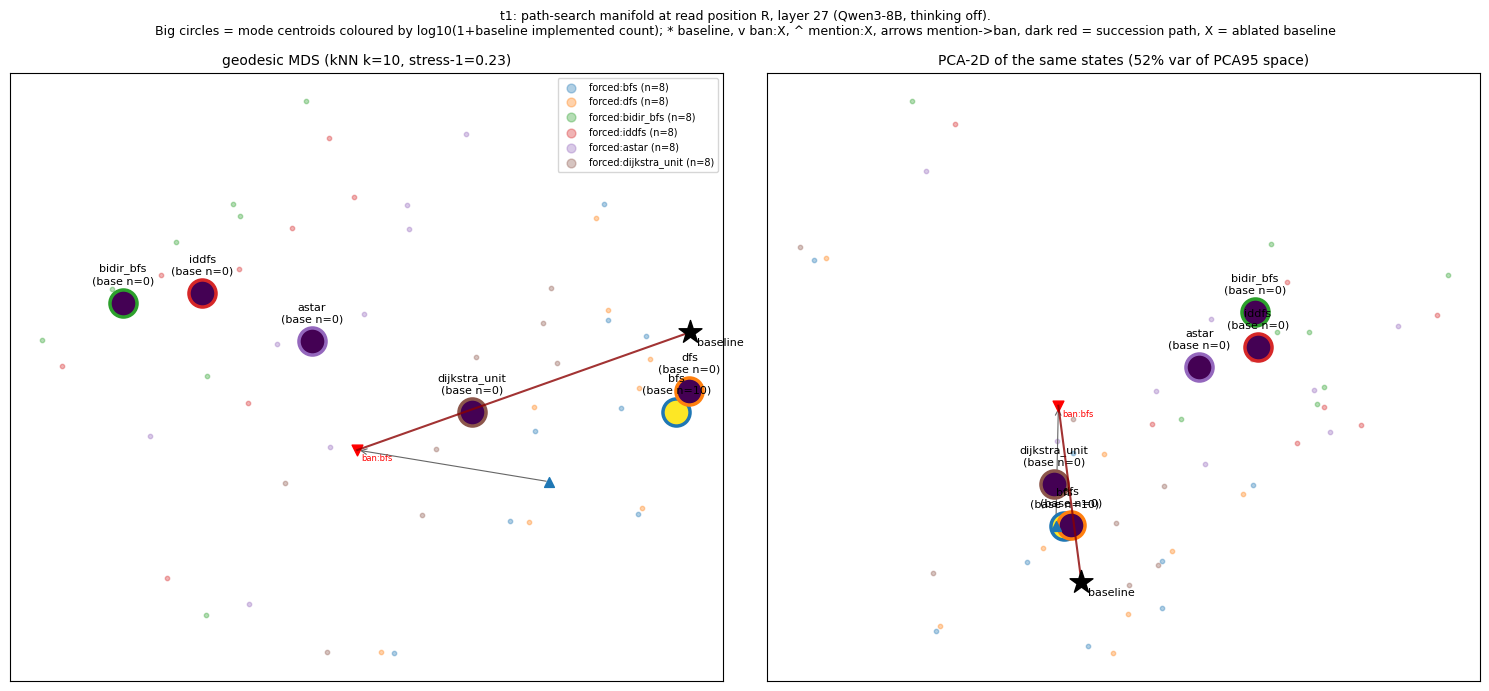

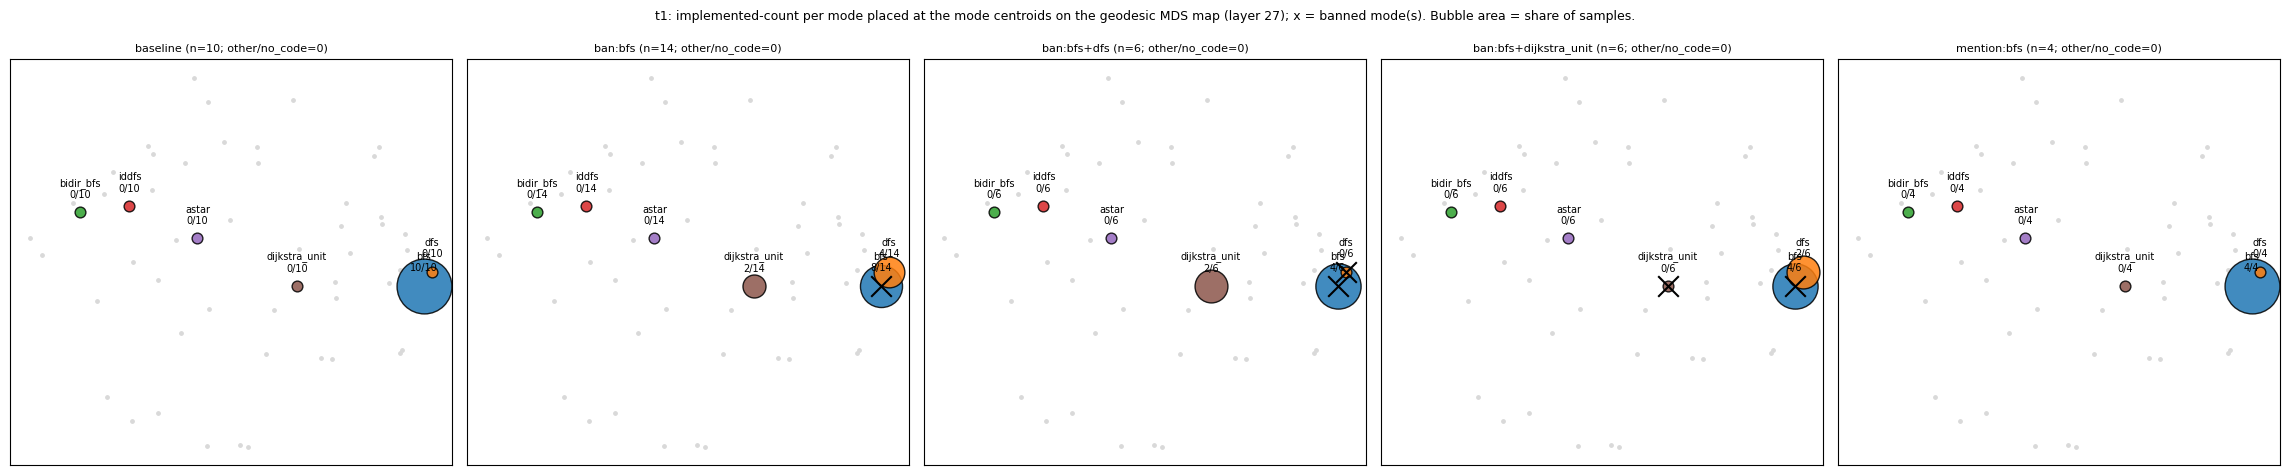

,statistic,demo,full run
0,PCA95 dimensions,12.000,22.000
1,TwoNN intrinsic dimension,3.260,4.160
2,TwoNN of column-shuffled nulls (mean),8.620,11.920
3,MDS stress-1,0.226,0.217
4,"Spearman(geodesic, Euclidean)",0.929,0.873


In [31]:
# --- analysis/analyze.py (verbatim; k = KNN_K, MDS restarts = MDS_N_INIT, TwoNN nulls = N_TWONN_NULLS,
# figures shown inline) ---
# ============================================================================================ E4 manifold
def manifold(index, H, gate, summA, geoB, phaseC, rows=None) -> dict:
    import matplotlib.pyplot as plt
    from scipy.stats import spearmanr
    from sklearn.manifold import MDS

    out = {}
    for t in TASKS:
        cat = CATALOGUE[t]
        l = gate[t]["l_star"]
        iN = [i for i, r in enumerate(index) if r["task"] == t and r["condition"].startswith("forced:")]
        lab = [index[i]["condition"].split(":")[1] for i in iN]
        Xn = H[l][iN]
        mu, comps, ev = pca95(Xn)
        P = (Xn - mu) @ comps.T
        C = np.stack([Xn[[k for k, m in enumerate(lab) if m == mm]].mean(0) for mm in cat])
        G, ginfo = knn_graph(P, KNN_K)
        # leaf points: centroids, baseline, ban:X, mention:X, listall, succession, ablated baseline
        leaf_names, leaf_vecs = [], []
        for j, m in enumerate(cat):
            leaf_names.append(f"centroid:{m}")
            leaf_vecs.append(C[j])

        def mean_cond(c):
            ii = [i for i, r in enumerate(index) if r["task"] == t and r["condition"] == c]
            return H[l][ii].mean(0) if ii else None

        conds = ["baseline", "listall"] + [f"ban:{m}" for m in cat] + [f"mention:{m}" for m in cat]
        chain = phaseC.get("succession", {}).get(t, {}).get("chain", [])
        for k in range(2, len(chain) + 1):
            conds.append("ban:" + "+".join(chain[:k]))
        for c in conds:
            v = mean_cond(c)
            if v is not None:
                leaf_names.append(c)
                leaf_vecs.append(v)
        abl = CACHE / f"hR_ablated_{t}.npz"
        if abl.exists():
            Z = np.load(abl)
            band = [int(x) for x in Z["band"]]
            if l in band:
                leaf_names.append("ablated_baseline")
                leaf_vecs.append(Z["h"][band.index(l)].astype(np.float32).mean(0))
        Q = (np.stack(leaf_vecs) - mu) @ comps.T
        GA = attach(G, P, Q, KNN_K)
        from scipy.sparse.csgraph import shortest_path

        Dall = shortest_path(GA, directed=False)
        Dall = (Dall + Dall.T) / 2
        finite = np.isfinite(Dall).all()
        mds = MDS(n_components=2, dissimilarity="precomputed", n_init=MDS_N_INIT, random_state=0, normalized_stress="auto")
        Y = mds.fit_transform(np.where(np.isfinite(Dall), Dall, np.nanmax(Dall[np.isfinite(Dall)]) * 2))
        from scipy.spatial.distance import pdist, squareform

        Dy = squareform(pdist(Y))
        iu = np.triu_indices(len(Dall), 1)
        stress1 = float(np.sqrt(np.sum((Dall[iu] - Dy[iu]) ** 2) / np.sum(Dall[iu] ** 2)))
        # geodesic vs euclidean rank correlation (over points)
        from scipy.spatial.distance import cdist

        De = cdist(P, P)
        npnt = len(P)
        ii = np.triu_indices(npnt, 1)
        rho = float(spearmanr(Dall[:npnt, :npnt][ii], De[ii])[0])
        # testing plan 8: geodesic >= Euclidean for every pair, symmetric distance matrix
        Graw = shortest_path(GA, directed=False)
        geo_checks = {"geodesic_ge_euclidean_all_pairs": bool((Dall[:npnt, :npnt] + 1e-4 >= De).all()),
                      "symmetric_max_abs_diff": float(np.nanmax(np.abs(Graw - Graw.T)[np.isfinite(Graw)]))}
        # intrinsic dimension vs column-shuffled nulls
        idim = twonn_id(P)
        nulls = []
        for s in range(N_TWONN_NULLS):
            Ps = P.copy()
            for c in range(Ps.shape[1]):
                Ps[:, c] = RNG.permutation(Ps[:, c])
            nulls.append(twonn_id(Ps))
        counts = {m: summA[t]["baseline_label_counts"].get(m, 0) for m in cat}
        out[t] = {"layer": l, "pca_dims": int(comps.shape[0]), "pca_explained": float(ev.sum()), "graph": ginfo,
                  "mds_stress1": stress1, "geodesic_vs_euclidean_spearman": rho, "twonn_id": idim,
                  "twonn_null_mean": float(np.nanmean(nulls)), "twonn_null_p5_p95": [float(np.nanpercentile(nulls, 5)),
                                                                                       float(np.nanpercentile(nulls, 95))],
                  "leaf_names": leaf_names, "mds_xy_leaves": Y[npnt:].tolist(), "all_finite": bool(finite),
                  "centroid_geodesic": Dall[npnt:npnt + len(cat), npnt:npnt + len(cat)].tolist(),
                  "baseline_counts": counts, "checks": geo_checks}
        # ---------------------------------------------------------------- figure: MDS + PCA side by side
        cmap = plt.get_cmap("tab10")
        fig, axes = plt.subplots(1, 2, figsize=(15, 7.0))
        Ppca = P[:, :2]
        Qpca = Q[:, :2]
        for ax, (pts, lv, title) in zip(axes, [(Y[:npnt], Y[npnt:], f"geodesic MDS (kNN k={KNN_K}, stress-1={stress1:.2f})"),
                                               (Ppca, Qpca, f"PCA-2D of the same states ({ev[:2].sum() * 100:.0f}% var of PCA95 space)")]):
            for j, m in enumerate(cat):
                sel = [k for k, mm in enumerate(lab) if mm == m]
                ax.scatter(pts[sel, 0], pts[sel, 1], s=10, alpha=0.35, color=cmap(j), label=f"forced:{m} (n={len(sel)})")
            vmax = max(np.log10(1 + max(counts.values())), 1e-6)
            for j, m in enumerate(cat):
                c = math.log10(1 + counts[m]) / vmax
                ax.scatter(lv[j, 0], lv[j, 1], s=380, marker="o", c=[plt.get_cmap("viridis")(c)], edgecolors=cmap(j),
                           linewidths=2.5, zorder=5)
                ax.annotate(f"{m}\n(base n={counts[m]})", lv[j], fontsize=8, ha="center", va="bottom",
                            xytext=(0, 12), textcoords="offset points", zorder=6)
            name_pos = {n: lv[k] for k, n in enumerate(leaf_names)}
            for n, p in name_pos.items():
                if n.startswith("centroid"):
                    continue
                if n == "baseline":
                    ax.scatter(*p, marker="*", s=300, c="k", zorder=7)
                    ax.annotate("baseline", p, fontsize=8, xytext=(5, -10), textcoords="offset points")
                elif n == "listall":
                    ax.scatter(*p, marker="P", s=120, c="0.3", zorder=7)
                    ax.annotate("list-all", p, fontsize=7, xytext=(5, 3), textcoords="offset points")
                elif n == "ablated_baseline":
                    ax.scatter(*p, marker="X", s=200, c="m", zorder=7)
                    ax.annotate("ablated baseline", p, fontsize=8, color="m", xytext=(5, 3), textcoords="offset points")
                elif n.startswith("ban:") and "+" not in n:
                    ax.scatter(*p, marker="v", s=60, c="r", zorder=6)
                    ax.annotate(n, p, fontsize=6, color="r", xytext=(3, -8), textcoords="offset points")
                elif n.startswith("ban:"):
                    ax.scatter(*p, marker="D", s=50, c="darkred", zorder=6)
                elif n.startswith("mention:"):
                    ax.scatter(*p, marker="^", s=50, c="tab:blue", zorder=6)
            for m in cat:
                a, b = name_pos.get(f"mention:{m}"), name_pos.get(f"ban:{m}")
                if a is not None and b is not None:
                    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="0.4", lw=0.8))
            path = ["baseline"] + ["ban:" + "+".join(chain[:k]) for k in range(1, len(chain) + 1)]
            path = [name_pos[p] for p in path if p in name_pos]
            if len(path) >= 2:
                pa = np.array(path)
                ax.plot(pa[:, 0], pa[:, 1], "-", color="darkred", lw=1.5, alpha=0.8, zorder=6)
            ax.set_title(title, fontsize=10)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[0].legend(fontsize=7, loc="best", markerscale=2)
        fig.suptitle(f"{t}: path-search manifold at read position R, layer {l} (Qwen3-8B, thinking off).\nBig circles = "
                     f"mode centroids coloured by log10(1+baseline implemented count); * baseline, v ban:X, ^ mention:X, "
                     f"arrows mention->ban, dark red = succession path, X = ablated baseline", fontsize=9)
        fig.tight_layout()
        for ext in ("png", "pdf"):
            fig.savefig(FIG / f"manifold_{t}.{ext}", dpi=160)
        plt.show()  # notebook: display inline (original: plt.close(fig))
        # ---------------------------------------------------------------- figure: where do the bans send the model?
        if rows is not None:
            X1 = summA[t]["modal"]
            ban_conds = sorted({r["condition"] for r in rows["C"] if r["task"] == t and r["condition"].startswith("ban:")},
                               key=lambda c: (c.count("+"), c))
            panels = [("baseline", [r for r in rows["A"] if r["task"] == t and r["condition"] == "baseline"])]
            panels += [(c, [r for r in rows["C"] if r["task"] == t and r["condition"] == c]) for c in ban_conds]
            mcond = f"mention:{X1}"
            mr = [r for r in rows["C"] if r["task"] == t and r["condition"] == mcond]
            if mr:
                panels.append((mcond, mr))
            fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4.8), squeeze=False)
            for ax, (c, rr) in zip(axes[0], panels):
                cnt = Counter(r["label"] for r in rr)
                ax.scatter(Y[:npnt, 0], Y[:npnt, 1], s=6, c="0.85")
                for j, m in enumerate(cat):
                    k = cnt.get(m, 0)
                    ax.scatter(Y[npnt + j, 0], Y[npnt + j, 1], s=60 + 1500 * k / max(len(rr), 1), color=cmap(j),
                               alpha=0.85, edgecolors="k", zorder=5)
                    ax.annotate(f"{m}\n{k}/{len(rr)}", (Y[npnt + j, 0], Y[npnt + j, 1]), fontsize=7, ha="center",
                                va="bottom", xytext=(0, 9), textcoords="offset points", zorder=6)
                banned = c.split(":", 1)[1].split("+") if c.startswith("ban:") else []
                for b in banned:
                    jb = cat.index(b)
                    ax.scatter(Y[npnt + jb, 0], Y[npnt + jb, 1], marker="x", s=220, c="k", zorder=7)
                oth = cnt.get("other", 0) + cnt.get("no_code", 0)
                ax.set_title(f"{c} (n={len(rr)}; other/no_code={oth})", fontsize=8)
                ax.set_xticks([])
                ax.set_yticks([])
            fig.suptitle(f"{t}: implemented-count per mode placed at the mode centroids on the geodesic MDS map "
                         f"(layer {l}); x = banned mode(s). Bubble area = share of samples.", fontsize=9)
            fig.tight_layout()
            for ext in ("png", "pdf"):
                fig.savefig(FIG / f"ban_shift_on_manifold_{t}.{ext}", dpi=160)
            plt.show()  # notebook: display inline (original: plt.close(fig))
    return out


man = manifold(index, H, gate, summA, geoB, phaseC, rows)
jdump(man, "manifold.json")
mt, mref = man["t1"], meta["full_run_reference"]["manifold"]
display(pd.DataFrame([
    {"statistic": "PCA95 dimensions", "demo": mt["pca_dims"], "full run": mref["pca_dims"]},
    {"statistic": "TwoNN intrinsic dimension", "demo": round(mt["twonn_id"], 2), "full run": round(mref["twonn_id"], 2)},
    {"statistic": "TwoNN of column-shuffled nulls (mean)", "demo": round(mt["twonn_null_mean"], 2), "full run": round(mref["twonn_null_mean"], 2)},
    {"statistic": "MDS stress-1", "demo": round(mt["mds_stress1"], 3), "full run": round(mref["mds_stress1"], 3)},
    {"statistic": "Spearman(geodesic, Euclidean)", "demo": round(mt["geodesic_vs_euclidean_spearman"], 3),
     "full run": round(mref["geodesic_vs_euclidean_spearman"], 3)},
]))

### The forecast contest

`score_event()` scores each committed forecast against the realised outcome of an event. The **log score** is the
mean log probability that the forecast gave to the label of each program. A **top-1 hit** means the forecast's top
algorithm is the realised mode. In the run, the primary events were `t1|ban:bfs` and `t2|ban:dijkstra`; the step-2
bans are exploratory. The `BUY` row relates the gain in algorithmic diversity (Hill number over correct programs)
to the pass rate lost under the ban.

In [32]:
# --- analysis/analyze.py (verbatim) ---
# ============================================================================================ E5 contest
PREDS = ["association", "frequency", "geodesic", "decoder"]

def score_event(ev: dict, rr: list[dict], cat: list[str]) -> dict:
    S = ev["survivors"]
    bset = ev["banset"]
    comp = [r for r in rr if r["passed"] and r["label"] not in bset and r["label"] != "no_code"]
    cnt = Counter(r["label"] for r in comp)
    real = np.array([cnt.get(m, 0) for m in S], float)
    lead_ok = False
    ranked = cnt.most_common()
    if ranked:
        lead = (ranked[0][1] - (ranked[1][1] if len(ranked) > 1 else 0)) / max(len(comp), 1)
        lead_ok = lead >= 0.15
    realised = ranked[0][0] if (ranked and lead_ok) else None
    out = {"n": len(rr), "n_compliant": len(comp), "compliance": len(comp) / max(len(rr), 1),
           "realised_counts": dict(cnt), "realised_mode": realised or "no clear mode",
           "realised_in_survivors": realised in S if realised else None, "predictors": {}}
    scored = [r for r in rr if r["label"] in S or r["label"] == "other"]
    for p in PREDS + ["association_X1"]:
        q = np.array([ev["distributions"][p][m] for m in S])
        top1 = S[int(np.argmax(q))]
        qm = 0.98 * (0.95 * q + 0.05 / len(S))
        lp = [math.log(qm[S.index(r["label"])]) if r["label"] in S else math.log(0.02) for r in scored]
        rs = real + 0.5
        js = js_div(q, rs / rs.sum())
        from scipy.stats import spearmanr

        sp = float(spearmanr(q, real)[0]) if len(S) > 2 and real.std() > 0 and q.std() > 0 else float("nan")
        top2p = set(np.array(S)[np.argsort(-q)[:2]])
        top2r = set(np.array(S)[np.argsort(-real)[:2]])
        tied = bool(ev.get("top1_tied", {}).get(p, False))
        out["predictors"][p] = {"top1": top1, "tied": tied,
                                "hit": (None if tied else ((top1 == realised) if realised else False)),
                                "log_score_mean": float(np.mean(lp)) if lp else float("nan"), "n_scored": len(lp),
                                "js_to_realised": js, "spearman": sp, "top2_agreement": len(top2p & top2r) / 2}
    return out

def contest(rows, preds, phaseC) -> dict:
    events = {}
    for eid, ev in preds["events"].items():
        t = ev["task"]
        cat = CATALOGUE[t]
        if ev["kind"] == "ban":
            cond = "ban:" + "+".join(ev["banset"])
            rr = [r for r in rows["C"] if r["task"] == t and r["condition"] == cond]
        else:
            # removal event scored on the strongest successful d_X arm (filled in by c2)
            continue
        if not rr:
            continue
        sc = score_event(ev, rr, cat)
        per_para = {}
        for pid in sorted({r["paraphrase_id"] for r in rr}):
            rp = [r for r in rr if r["paraphrase_id"] == pid]
            per_para[pid] = {"n": len(rp), "compliant": sum(r["passed"] and r["label"] not in ev["banset"] and r["label"] != "no_code" for r in rp),
                             "labels": dict(Counter(r["label"] for r in rp))}
        sc["per_paraphrase"] = per_para
        sc["exploratory"] = bool(phaseC.get("events", {}).get(eid, {}).get("exploratory", False))
        sc["ban_failure"] = sc["compliance"] < 0.5
        sc.update({"event": eid, "task": t, "banset": ev["banset"], "survivors": ev["survivors"],
                   "committed_top1": ev["top1"], "concordance": ev["concordance"], "stability": ev["stability"],
                   "ambiguity_flag": ev["ambiguity_flag"]})
        events[eid] = sc
    return events

def contest_aggregate(events: dict, primary_only: bool = False) -> dict:
    agg = {}
    sc = [e for e in events.values() if not (primary_only and e.get("exploratory"))]
    for p in PREDS + ["association_X1"]:
        scored = [e for e in sc if e["predictors"][p]["hit"] is not None]
        hits = sum(bool(e["predictors"][p]["hit"]) for e in scored)
        n = len(scored)
        agg[p] = {"hits": hits, "events": n, "events_tied_excluded": len(sc) - n, "hit_rate": hits / max(n, 1),
                  "wilson": wilson(hits, n),
                  "mean_log_score": float(np.nanmean([e["predictors"][p]["log_score_mean"] for e in sc])) if sc else None,
                  "mean_js": float(np.nanmean([e["predictors"][p]["js_to_realised"] for e in sc])) if sc else None,
                  "mean_top2": float(np.nanmean([e["predictors"][p]["top2_agreement"] for e in sc])) if sc else None}
    trio = ["association", "frequency", "geodesic"]
    M = {a: {b: float(np.mean([e["committed_top1"][a] == e["committed_top1"][b] for e in sc])) if sc else None
             for b in trio} for a in trio}
    return {"per_predictor": agg, "agreement_matrix_top1": M, "n_events": len(sc),
            "note": "descriptive only: about 4-7 events, no p-values"}


# --- analysis/analyze.py main() (verbatim) ---
# contest (ban events) -- timestamps after commit
ce = contest(rows, preds, phaseC)
for eid, e in ce.items():
    e["commit_sha256"] = commit["sha256"]
    e["distributions"] = preds["events"][eid]["distributions"]
    e["hits"] = {p: e["predictors"][p]["hit"] for p in PREDS}
    first = min(r["utc"] for r in rows["C"] if f"{e['task']}|ban:{'+'.join(e['banset'])}" == r.get("event_tag"))
    e["first_sample_after_commit"] = bool(first > commit["unix"])
agg = contest_aggregate(ce)
agg_primary = contest_aggregate(ce, primary_only=True)
jdump({"events": ce, "aggregate_all": agg, "aggregate_primary": agg_primary, "commit": commit}, "contest.json")
# (C3 shift decomposition and C2 removal analysis need all band layers / Phase-D samples: skipped)
# E8 BUY row (prompt-ban part)
buy = {}
for t in TASKS:
    X = summA[t]["modal"]
    b = summ[t].get("baseline")
    pb = summ[t].get(f"ban:{X}")
    row = {}
    if b and pb:
        dp = (b["pass_rate"] - pb["pass_rate"]) * 100
        row["prompt_ban"] = {"hill_cc_base": b["hill_cc"], "hill_cc_ban": pb["hill_cc"], "pass_base": b["pass_rate"],
                             "pass_ban": pb["pass_rate"], "d_hill_per_pass_point_lost": (pb["hill_cc"] - b["hill_cc"]) / dp if dp > 0 else None}
    buy[t] = row
jdump(buy, "buy.json")

full_ct = meta["full_run_reference"]["contest_t1_events"]
display(pd.DataFrame([{"event": eid, "exploratory": e["exploratory"], "realised (demo)": e["realised_mode"],
                       "realised (full run)": full_ct[eid]["realised_mode"]}
                      | {f"{p} log score (demo / full)": f"{e['predictors'][p]['log_score_mean']:.2f} / {full_ct[eid]['log_score_mean'][p]:.2f}"
                         for p in PREDS}
                      for eid, e in ce.items()]))
print("BUY (prompt ban):", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in buy["t1"]["prompt_ban"].items()})
print("first ban sample after the commit:", {eid: e["first_sample_after_commit"] for eid, e in ce.items()},
      "(the replay commits after the run's samples; in the run every event was True, commit sha256 "
      f"{meta['full_run_reference']['commit_sha256'][:12]}...)")

,event,exploratory,realised (demo),realised (full run),association log score (demo / full),frequency log score (demo / full),geodesic log score (demo / full),decoder log score (demo / full)
0,t1|ban:bfs,False,no clear mode,no clear mode,-3.26 / -3.54,-1.63 / -1.63,-1.40 / -1.34,-1.42 / -1.29
1,t1|ban:bfs+dfs,True,dijkstra_unit,dijkstra_unit,-1.00 / -1.00,-1.41 / -1.41,-1.14 / -1.07,-3.40 / -4.12
2,t1|ban:bfs+dijkstra_unit,True,dfs,dfs,-3.97 / -3.97,-1.41 / -1.41,-1.22 / -1.28,-1.63 / -1.37


BUY (prompt ban): {'hill_cc_base': 1.0, 'hill_cc_ban': 2.478, 'pass_base': 1.0, 'pass_ban': 0.786, 'd_hill_per_pass_point_lost': 0.069}
first ban sample after the commit: {'t1|ban:bfs': False, 't1|ban:bfs+dfs': False, 't1|ban:bfs+dijkstra_unit': False} (the replay commits after the run's samples; in the run every event was True, commit sha256 186f7182ebb7...)


## Results: the demo next to the full run

The tables and figure below put the main T1 numbers side by side: the demo (this notebook, 100 programs, 8
forced-named states per algorithm) and the full run (all programs, 30 states per algorithm). The demo graph is built
on fewer states, so its geodesic distances are on a different scale. The bar chart therefore compares distances
divided by the median inter-centroid distance, the scale the geodesic forecast itself uses.

Share of programs implementing each algorithm (demo / full run):


,condition,demo n,full-run n,bfs,dfs,bidir_bfs,iddfs,astar,dijkstra_unit
0,baseline,10,200,1.00 / 1.00,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00
1,ban:bfs,14,100,0.57 / 0.62,0.29 / 0.29,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00,0.14 / 0.09
2,ban:bfs+dfs,6,50,0.67 / 0.58,0.00 / 0.04,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00,0.33 / 0.38
3,ban:bfs+dijkstra_unit,6,50,0.67 / 0.62,0.33 / 0.34,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00,0.00 / 0.04
4,mention:bfs,4,50,1.00 / 1.00,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00,0.00 / 0.00


Geodesic distance from the BFS centroid (demo / full run): {'dfs': '44 / 41', 'bidir_bfs': '83 / 95', 'iddfs': '76 / 82', 'astar': '73 / 71', 'dijkstra_unit': '47 / 58'}
Mean log score over the 3 T1 ban events (higher = better), demo / full run: {'association': '-2.74 / -2.84', 'frequency': '-1.48 / -1.48', 'geodesic': '-1.25 / -1.23', 'decoder': '-2.15 / -2.26'}


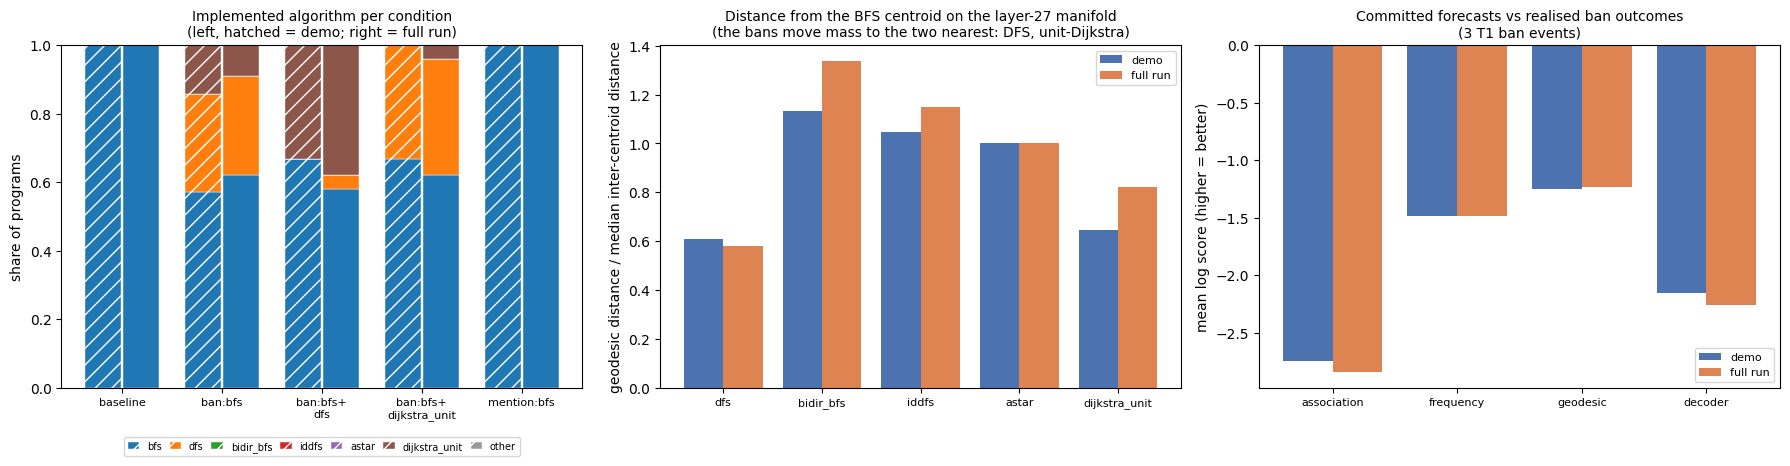

In [33]:
cat = CATALOGUE["t1"]
full = meta["full_run_reference"]
full_counts = {"baseline": full["phaseA"]["baseline_label_counts"]} | {
    eid.split("|")[1]: e["label_counts_all"] for eid, e in full["phaseC_events"].items()}
conds = ["baseline", "ban:bfs", "ban:bfs+dfs", "ban:bfs+dijkstra_unit", "mention:bfs"]

# (1) where does the mass go? label shares per condition, demo vs full run
tab = []
for c in conds:
    d = summ["t1"][c]["label_counts"]
    nd, nf = sum(d.values()), sum(full_counts[c].values())
    tab.append({"condition": c, "demo n": nd, "full-run n": nf}
               | {m: f"{d.get(m, 0) / nd:.2f} / {full_counts[c].get(m, 0) / nf:.2f}" for m in cat})
print("Share of programs implementing each algorithm (demo / full run):")
display(pd.DataFrame(tab))

# (2) the geometry: distance from the BFS centroid on the geodesic map
Dd = np.array(man["t1"]["centroid_geodesic"])
Df = np.array(full["manifold"]["centroid_geodesic"])
iu = np.triu_indices(len(cat), 1)
dnorm, fnorm = Dd[0] / np.median(Dd[iu]), Df[0] / np.median(Df[iu])
print("Geodesic distance from the BFS centroid (demo / full run):",
      {m: f"{Dd[0, j]:.0f} / {Df[0, j]:.0f}" for j, m in enumerate(cat) if m != "bfs"})

# (3) the contest: mean log score per predictor over the T1 events
lsd = {p: np.mean([e["predictors"][p]["log_score_mean"] for e in ce.values()]) for p in PREDS}
lsf = {p: np.mean([e["log_score_mean"][p] for e in full["contest_t1_events"].values()]) for p in PREDS}
print("Mean log score over the 3 T1 ban events (higher = better), demo / full run:",
      {p: f"{lsd[p]:.2f} / {lsf[p]:.2f}" for p in PREDS})

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
cmap = plt.get_cmap("tab10")
w = 0.38
for k, (src_name, counts_of) in enumerate((("demo", lambda c: summ["t1"][c]["label_counts"]), ("full run", lambda c: full_counts[c]))):
    bottom = np.zeros(len(conds))
    for j, m in enumerate(cat + ["other"]):
        sh = np.array([counts_of(c).get(m, 0) / max(sum(counts_of(c).values()), 1) for c in conds])
        axes[0].bar(np.arange(len(conds)) + (k - 0.5) * w, sh, w * 0.95, bottom=bottom, color=cmap(j) if m != "other" else "0.6",
                    label=m if k == 0 else None, hatch="//" if k == 0 else None, edgecolor="white", lw=0.3)
        bottom += sh
axes[0].set_xticks(np.arange(len(conds)))
axes[0].set_xticklabels([c.replace("+", "+\n") for c in conds], fontsize=8)
axes[0].set_ylabel("share of programs")
axes[0].set_title("Implemented algorithm per condition\n(left, hatched = demo; right = full run)", fontsize=10)
axes[0].legend(fontsize=7, ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.13), columnspacing=0.8, handlelength=1.2)
others = [m for m in cat if m != "bfs"]
x = np.arange(len(others))
axes[1].bar(x - 0.2, [dnorm[cat.index(m)] for m in others], 0.4, label="demo", color="#4c72b0")
axes[1].bar(x + 0.2, [fnorm[cat.index(m)] for m in others], 0.4, label="full run", color="#dd8452")
axes[1].set_xticks(x)
axes[1].set_xticklabels(others, fontsize=8)
axes[1].set_ylabel("geodesic distance / median inter-centroid distance")
axes[1].set_title("Distance from the BFS centroid on the layer-27 manifold\n(the bans move mass to the two nearest: DFS, unit-Dijkstra)", fontsize=10)
axes[1].legend(fontsize=8)
x = np.arange(len(PREDS))
axes[2].bar(x - 0.2, [lsd[p] for p in PREDS], 0.4, label="demo", color="#4c72b0")
axes[2].bar(x + 0.2, [lsf[p] for p in PREDS], 0.4, label="full run", color="#dd8452")
axes[2].set_xticks(x)
axes[2].set_xticklabels(PREDS, fontsize=8)
axes[2].set_ylabel("mean log score (higher = better)")
axes[2].set_title("Committed forecasts vs realised ban outcomes\n(3 T1 ban events)", fontsize=10)
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

### Reading the results

* **Collapse.** Every baseline program is BFS, and mentioning BFS keeps it at BFS. The model can write the other
  algorithms when it is asked to (the manipulation check), but on its own it never does.
* **Bans mostly fail, and what moves stays close.** Under `ban:bfs`, most programs are still BFS. The rest go to
  DFS and unit-Dijkstra, the two centroids closest to BFS on the read-position manifold, and never to the far side
  (A\*, IDDFS, bidirectional BFS). Banning the next neighbour as well pushes the mass one more step along the map:
  `ban:bfs+dfs` gives unit-Dijkstra, and `ban:bfs+dijkstra_unit` gives DFS. In the words of the original request,
  the implemented count moves *to the edge of the banned region*, not to the opposite side.
* **Geometry beats the model's self-report.** The geodesic forecast scores better than the model's own ranking of
  "the most standard alternative" (association), which points to A\*.
* **Caveats.** These are 2 primary events plus 3 exploratory ones in the full run, so everything is descriptive.
  T1's R gate failed on the decoder criterion. The demo uses 8 states per algorithm instead of 30, so its numbers
  are noisier versions of the full-run ones.